<a href="https://colab.research.google.com/github/samuel-m-chow/data-science/blob/main/NBA_Shot_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**WARNING** Please leverage "High-RAM" runtime configurations to avoid having computation challenges due to memory restrictions.

# NBA Shot Analysis

## Introduction

Over the past two decades, the NBA has undergone one of the most dramatic
strategic transformations in professional sports history. The rise of analytics
has reshaped how teams think about shot selection. The midrange jumper has nearly vanished, corner 3s have become a staple of every offense, and players are increasingly evaluated not just by how much they score but by where and how efficiently they shoot. This shift raises a deeper question that goes beyond league-wide trends: do individual players actually perform better when shooting from the zones they specialize in?

This notebook sets out to answer that question. We combine two datasets to
build a comprehensive picture of NBA shooting across 20 seasons:

- **NBA Shots** (Kaggle): shot-level data covering every recorded NBA shot
  from 2004 to 2023, including court location, zone, action type, distance,
  and outcome, giving us over 4 million rows in total
- **NBA Player Info** (nba_api): player-level attributes collected via the
  NBA's official stats API, including position, height, weight, age, draft
  information, and years of experience

Our analysis is structured around three central questions:

1. **How has shot selection and efficiency evolved across the league, and what are general shooting efficiency patterns?** We aim to explore and understand change in shot selection over the years through zone trends, seasonal efficiency patterns, shooting accuracy by quarter and game situation, positional breakdowns of FG% and shot distance, and action type efficiency. This covers both how the game has changed over time and how shooting efficiency varies across different contexts within a game.

2. **Do players develop characteristic zone profiles, and how do those profiles change with age?** We construct era-adjusted zone share metrics that capture how much each player over or under-indexes in each zone relative to league average, then examine how those profiles evolve over a player's career.

3. **Does zone specialization predict shooting efficiency?** We test whether players shoot better from the zones they specialize in using a two-stage modeling approach. First is a baseline model using only court coordinates, and an enriched model that adds player identity and zone specialization features   derived from our EDA. We train and compare three model architectures: Logistic Regression, Random Forest, and XGBoost. We fit these across both feature sets, evaluating on AUC, accuracy, and F1. **The modeling dataset contains over 3.8 million shots** after cleaning, merging, and balancing for class distribution, well above the 50,000 row threshold.

The notebook is organized as follows.

Sections 1 and 2 explore the shots and player info datasets independently through EDA. Section 3 introduces an expected points framework to evaluate shot quality. Section 4 combines the datasets and builds the era-adjusted zone profiles that power the modeling.

Section 5 covers feature engineering, where we construct the specialization features that power the enriched models. Section 6 contains the modeling and analysis, including the zone specialization correlation analysis, the baseline vs. enriched model comparison, feature importance, and the characteristic zone efficiency premium.

Section 7 is the conclusion to all of the EDA, modeling, and analysis. Sections 8 and 9 outline challenges and potential next steps, respectively.

## Setup

### Package imports and data loading

In [ ]:
import kagglehub
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn import preprocessing
import gdown
import warnings
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import roc_auc_score, log_loss, RocCurveDisplay, confusion_matrix, classification_report, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score
from sklearn.utils import resample
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)

### Shots Data from Kaggle

The shots dataset we are using comes from this Kaggle link: https://www.kaggle.com/datasets/mexwell/nba-shots/data


In [ ]:
# Loading shots data
shots_path = kagglehub.dataset_download("mexwell/nba-shots")
dfs = []
for f in sorted(os.listdir(shots_path)):
    if f.endswith(".csv"):
        dfs.append(pd.read_csv(f"{shots_path}/{f}"))
all_shots = pd.concat(dfs, ignore_index=True)
print(all_shots.shape)

Using Colab cache for faster access to the 'nba-shots' dataset.
(4231262, 26)


### Player Info Data Collection

Player info was collected using the `nba_api` library which is an API coming from the NBA's official stats. For each unique `PLAYER_ID` in the shots dataset,
we called `CommonPlayerInfo` to retrieve all the attributes from the API.

This process requires 1 API call per player with a 2 second sleep between requests to attempt to avoid any errors, so the full scrape takes a while to complete. **The code below is left
commented out for reference**. The saved CSV from these results are loaded directly from Google Drive.

In [ ]:
# Loading player info
# from nba_api.stats.endpoints import commonplayerinfo

# player_ids = all_shots['PLAYER_ID'].unique().astype(str).tolist()

# print(f"Total unique players to fetch: {len(player_ids)}")

# player_data = []

# for i, player_id in enumerate(player_ids):
#     info = commonplayerinfo.CommonPlayerInfo(player_id = player_id)
#     row = info.common_player_info.get_data_frame().iloc[0]

#     player_data.append({
#         'person_id': str(row['PERSON_ID']),
#         'name': row['DISPLAY_FIRST_LAST'],
#         'birthdate': row['BIRTHDATE'],
#         'position': row['POSITION'],
#         'height': row['HEIGHT'],
#         'weight': row['WEIGHT'],
#         'school': row['SCHOOL'],
#         'country': row['COUNTRY'],
#         'draft_year': row['DRAFT_YEAR'],
#         'draft_round': row['DRAFT_ROUND'],
#         'draft_number': row['DRAFT_NUMBER'],
#         'from_year': row['FROM_YEAR'],
#         'to_year': row['TO_YEAR'],
#         'team_name': row['TEAM_NAME']
#     })

#     if (i + 1) % 50 == 0:
#         print(f"Progress: {i+1}/{len(player_ids)} players fetched")

#     time.sleep(2)

# player_info = pd.DataFrame(player_data)


gdown.download(f"https://drive.google.com/uc?id=19zcQsvd0D_DZM7JZzs-_5EEedHBy5q5N", "nba_api_player_info_2.csv", quiet=False)
player_info = pd.read_csv("nba_api_player_info_2.csv")
player_info['person_id'] = player_info['person_id'].astype(str)
print(player_info.shape)

Downloading...
From: https://drive.google.com/uc?id=19zcQsvd0D_DZM7JZzs-_5EEedHBy5q5N
To: /content/nba_api_player_info_2.csv
100%|██████████| 243k/243k [00:00<00:00, 83.7MB/s]

(2162, 15)


## 1: Shots Dataset EDA

In this section we explore the raw shots dataset with some basic cleaning to understand:
- Data types, missing values, and shape of the data
- The date range and season coverage
- Distributions of key variables (shot type, zone, distance, outcome)
- How shot frequency and accuracy vary by zone and action type


### 1.1 Basic Info and Missing Values

In [ ]:
all_shots.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4231262 entries, 0 to 4231261
Data columns (total 26 columns):
 #   Column          Dtype  
---  ------          -----  
 0   SEASON_1        int64  
 1   SEASON_2        object 
 2   TEAM_ID         int64  
 3   TEAM_NAME       object 
 4   PLAYER_ID       int64  
 5   PLAYER_NAME     object 
 6   POSITION_GROUP  object 
 7   POSITION        object 
 8   GAME_DATE       object 
 9   GAME_ID         int64  
 10  HOME_TEAM       object 
 11  AWAY_TEAM       object 
 12  EVENT_TYPE      object 
 13  SHOT_MADE       bool   
 14  ACTION_TYPE     object 
 15  SHOT_TYPE       object 
 16  BASIC_ZONE      object 
 17  ZONE_NAME       object 
 18  ZONE_ABB        object 
 19  ZONE_RANGE      object 
 20  LOC_X           float64
 21  LOC_Y           float64
 22  SHOT_DISTANCE   int64  
 23  QUARTER         int64  
 24  MINS_LEFT       int64  
 25  SECS_LEFT       int64  
dtypes: bool(1), float64(2), int64(8), object(15)
memory usage: 811.1+ MB


In [ ]:
print(f"Dataset shape: {all_shots.shape}")
print(f"\nDate range: {all_shots['GAME_DATE'].min()} to {all_shots['GAME_DATE'].max()}")
print(f"Unique players: {all_shots['PLAYER_ID'].nunique():,}")
print(f"Unique teams:   {all_shots['TEAM_ID'].nunique()}")
print(f"Unique seasons: {all_shots['SEASON_1'].nunique()}")
print(f"\nMissing values:")
missing = all_shots.isnull().sum()
print(missing[missing > 0])

Dataset shape: (4231262, 26)

Date range: 01-01-2005 to 12-31-2023
Unique players: 2,162
Unique teams:   30
Unique seasons: 21

Missing values:
POSITION_GROUP    7930
POSITION          7930
dtype: int64


**Observations:**
- The dataset spans multiple NBA seasons starting from Jan 2005 to Dec 2023.
- We have granularity for each shot attempt with location, zone, action type, and outcome.
- The only major issue with missing values is `POSITION` and `POSITION_GROUP`. We will be able to fill this in using the `Player Info` dataset later on.
- Each row is one shot attempt with player identification.

### 1.2 Shot Outcome Distribution

In [ ]:
total_shots = len(all_shots)
made = (all_shots['SHOT_MADE'] == True).sum()
missed = (all_shots['SHOT_MADE'] == False).sum()
missing = all_shots['SHOT_MADE'].isna().sum()

pd.DataFrame({
    'Outcome': ['Made', 'Missed', 'Missing', 'Total'],
    'Count': [made, missed, missing, total_shots],
    'Percentage': [f'{made/total_shots*100:.2f}%', f'{missed/total_shots*100:.2f}%',
                   f'{missing/total_shots*100:.2f}%', '100%']
})

,Outcome,Count,Percentage
0,Made,1936550,45.77%
1,Missed,2294712,54.23%
2,Missing,0,0.00%
3,Total,4231262,100%


The league-wide field goal percentage across all of our seasons is around 46% which is consistent with known NBA averages. Missed shots slightly outnumber makes, and there are no shots with missing results.

### 1.3 Shot Type Distribution (2PT vs 3PT)

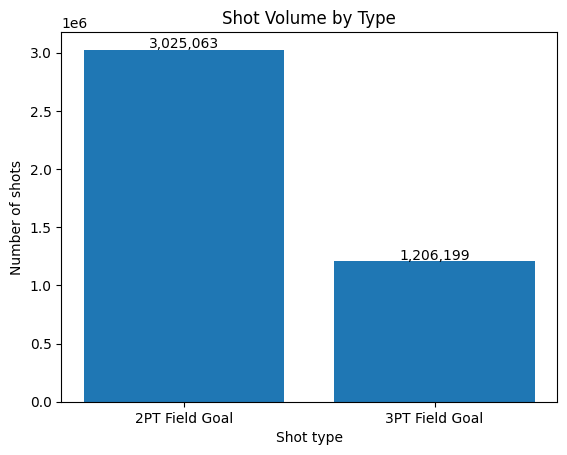

FG% by shot type:
SHOT_TYPE
2PT Field Goal    49.73
3PT Field Goal    35.82
Name: SHOT_MADE, dtype: float64


In [ ]:
shot_type_counts = all_shots['SHOT_TYPE'].value_counts()

plt.bar(shot_type_counts.index, shot_type_counts.values)
plt.title('Shot Volume by Type')
plt.xlabel('Shot type')
plt.ylabel('Number of shots')
for i, val in enumerate(shot_type_counts.values):
    plt.text(i, val + 15000, f'{val:,}', ha='center')
plt.show()

fg_by_type = all_shots.groupby('SHOT_TYPE')['SHOT_MADE'].mean() * 100
print("FG% by shot type:")
print(fg_by_type.round(2))

There are almost 3 times as many 2-point field goal attempts compared to 3-point field goal attempts. 2-point field goal shooting percentage is almost 50%, while 3-point shooting percentage is close to 36%.

### 1.4 Shot Distance Distribution

We look at the distribution of shots based on where they were taken from on the floor based on the X and Y coordinates.

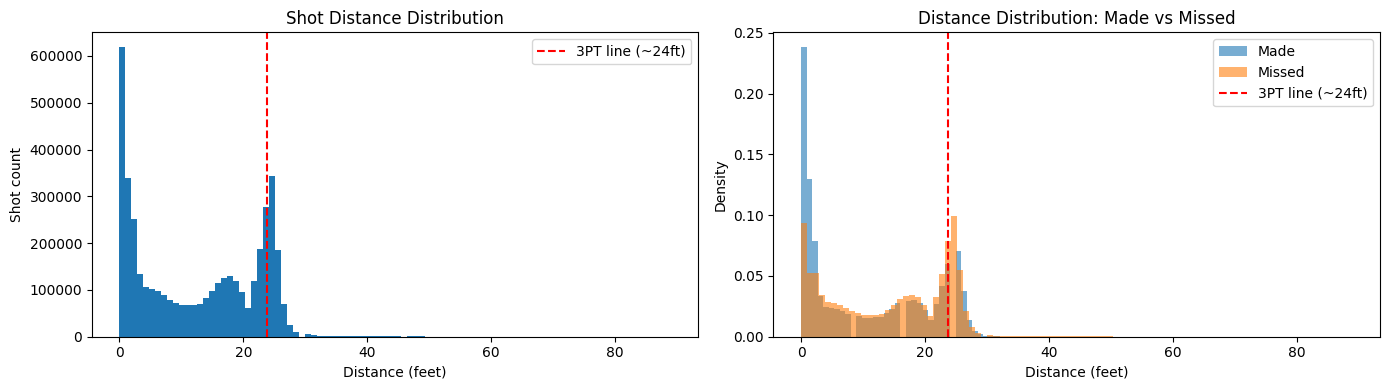

Distance summary stats:
count    4231262.00
mean          12.56
std           10.12
min            0.00
25%            2.00
50%           13.00
75%           23.00
max           89.00
Name: SHOT_DISTANCE, dtype: float64


In [ ]:
fig, (p1, p2) = plt.subplots(1, 2, figsize=(14, 4))

p1.hist(all_shots['SHOT_DISTANCE'], bins=92)
p1.set_title('Shot Distance Distribution')
p1.set_xlabel('Distance (feet)')
p1.set_ylabel('Shot count')
p1.axvline(23.75, color='red', linestyle='--', label='3PT line (~24ft)')
p1.legend()

made = all_shots[all_shots['SHOT_MADE'] == True]['SHOT_DISTANCE']
missed = all_shots[all_shots['SHOT_MADE'] == False]['SHOT_DISTANCE']
p2.hist(made, bins=92, alpha=0.6, label='Made', density=True)
p2.hist(missed, bins=92, alpha=0.6, label='Missed', density=True)
p2.set_title('Distance Distribution: Made vs Missed')
p2.set_xlabel('Distance (feet)')
p2.set_ylabel('Density')
p2.axvline(23.75, color='red', linestyle='--', label='3PT line (~24ft)')
p2.legend()

plt.tight_layout()
plt.show()

print("Distance summary stats:")
print(all_shots['SHOT_DISTANCE'].describe().round(2))

Shot distance has a bimodal distribution, with a large cluster of shots in the paint (under 8 ft) and another cluster beyond the 3-point line (~24+ ft). The midrange (8–22 ft) has comparatively less shot attempts than paint and 3-pointers. Made shots tend to cluster at shorter distances.

#### LOC_X and LOC_Y Distributions

Analyzing the number of shots taken from specific coordinates on the court.

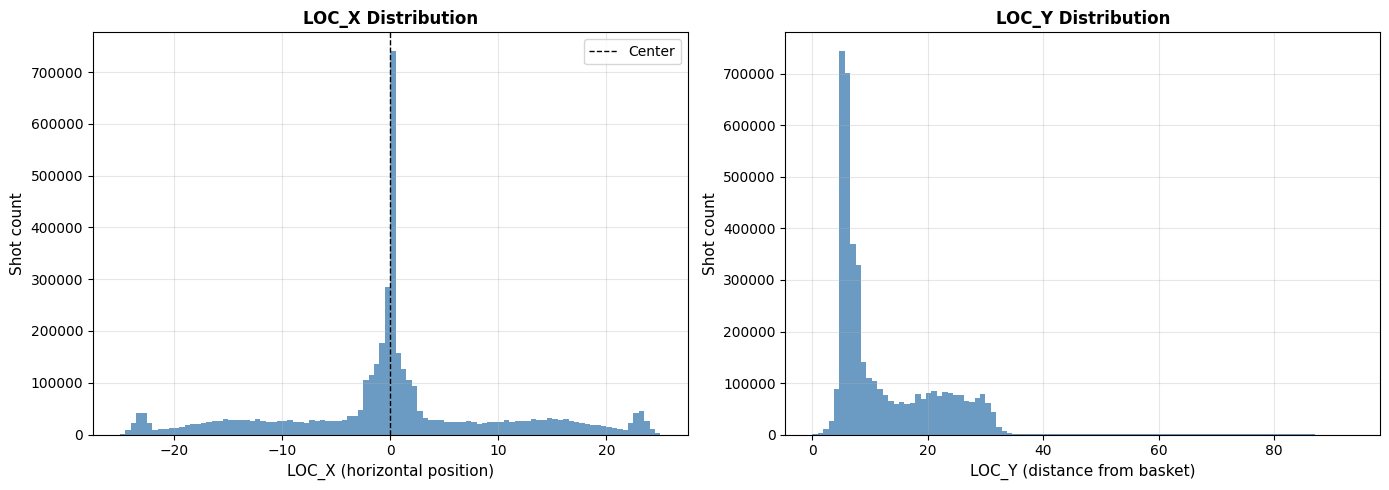

In [ ]:
fig, (p1, p2) = plt.subplots(1, 2, figsize=(14, 5))

p1.hist(all_shots['LOC_X'], bins=100, color='steelblue', edgecolor='none', alpha=0.8)
p1.axvline(0, color='black', lw=1, linestyle='--', label='Center')
p1.set_xlabel('LOC_X (horizontal position)', fontsize=11)
p1.set_ylabel('Shot count', fontsize=11)
p1.set_title('LOC_X Distribution', fontsize=12, fontweight='bold')
p1.legend()
p1.grid(alpha=0.3)

p2.hist(all_shots['LOC_Y'], bins=100, color='steelblue', edgecolor='none', alpha=0.8)
p2.set_xlabel('LOC_Y (distance from basket)', fontsize=11)
p2.set_ylabel('Shot count', fontsize=11)
p2.set_title('LOC_Y Distribution', fontsize=12, fontweight='bold')
p2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

LOC_X has a sharp peak at zero which is the high volume of shots taken
directly in front of the basket. The distribution is roughly symmetric around
zero, with secondary clusters at around ±22-25 representing corner 3-point
attempts. LOC_Y is similarly concentrated near 3-4ft (right where the basket is)and drops off sharply, which corresponds to paint shots. The secondary cluster around LOC_Y = 25 corresponds to 3-point attempts.

#### Makes vs. Misses by LOC_X and LOC_Y

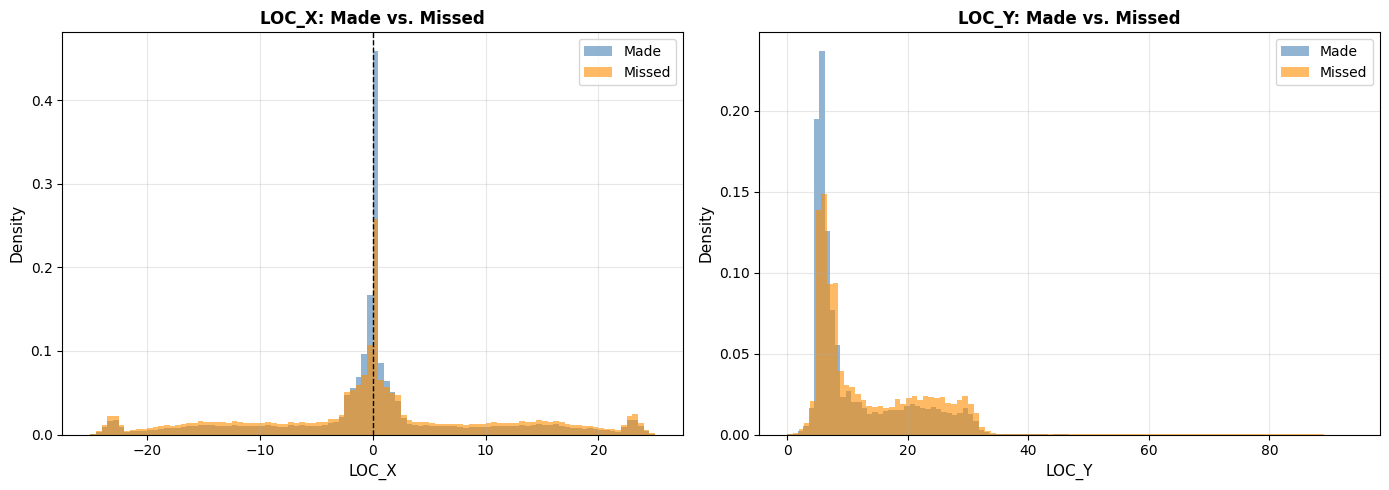

In [ ]:
made_shots = all_shots[all_shots['SHOT_MADE'] == True]
missed_shots = all_shots[all_shots['SHOT_MADE'] == False]

fig, (p1, p2) = plt.subplots(1, 2, figsize=(14, 5))

p1.hist(made_shots['LOC_X'], bins=100, alpha=0.6, color='steelblue',
        label='Made', density=True, edgecolor='none')
p1.hist(missed_shots['LOC_X'], bins=100, alpha=0.6, color='darkorange',
        label='Missed', density=True, edgecolor='none')
p1.axvline(0, color='black', lw=1, linestyle='--')
p1.set_xlabel('LOC_X', fontsize=11)
p1.set_ylabel('Density', fontsize=11)
p1.set_title('LOC_X: Made vs. Missed', fontsize=12, fontweight='bold')
p1.legend()
p1.grid(alpha=0.3)

p2.hist(made_shots['LOC_Y'], bins=100, alpha=0.6, color='steelblue',
        label='Made', density=True, edgecolor='none')
p2.hist(missed_shots['LOC_Y'], bins=100, alpha=0.6, color='darkorange',
        label='Missed', density=True, edgecolor='none')
p2.set_xlabel('LOC_Y', fontsize=11)
p2.set_ylabel('Density', fontsize=11)
p2.set_title('LOC_Y: Made vs. Missed', fontsize=12, fontweight='bold')
p2.legend()
p2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

The made and missed distributions are nearly identical for LOC_X, suggesting
that horizontal position alone is not a strong differentiator of shot outcome.
LOC_Y tells a clearer story, with made shots being more heavily concentrated at very low values near zero, while missed shots are more spread out across the midrange and 3-point distances. This might indicate that proximity to the basket is the strongest predictor of FG%.

#### FG% by LOC_X and LOC_Y

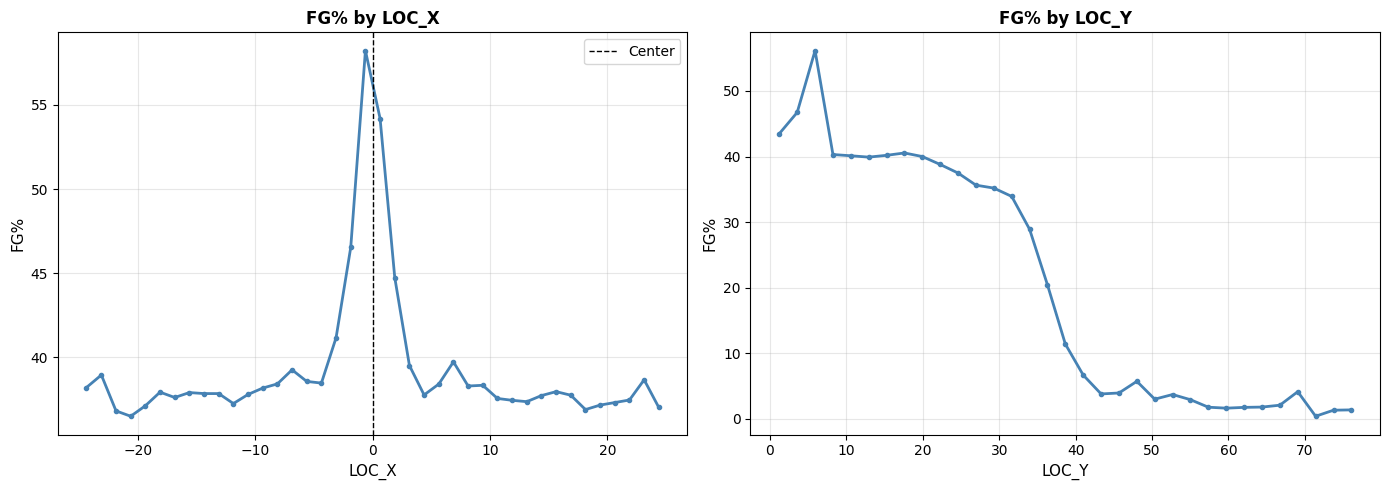

In [ ]:
locx_fg = all_shots.groupby(
    pd.cut(all_shots['LOC_X'], bins=40)
).agg(attempts=('SHOT_MADE', 'count'), fg_pct=('SHOT_MADE', 'mean')).reset_index()
locx_fg = locx_fg[locx_fg['attempts'] >= 200]
locx_fg['x_mid'] = locx_fg['LOC_X'].apply(lambda b: b.mid)
locx_fg['fg_pct'] = locx_fg['fg_pct'] * 100

locy_fg = all_shots.groupby(
    pd.cut(all_shots['LOC_Y'], bins=40)
).agg(attempts=('SHOT_MADE', 'count'), fg_pct=('SHOT_MADE', 'mean')).reset_index()
locy_fg = locy_fg[locy_fg['attempts'] >= 200]
locy_fg['y_mid'] = locy_fg['LOC_Y'].apply(lambda b: b.mid)
locy_fg['fg_pct'] = locy_fg['fg_pct'] * 100

fig, (p1, p2) = plt.subplots(1, 2, figsize=(14, 5))

p1.plot(locx_fg['x_mid'], locx_fg['fg_pct'],
        color='steelblue', linewidth=2, marker='o', markersize=3)
p1.axvline(0, color='black', lw=1, linestyle='--', label='Center')
p1.set_xlabel('LOC_X', fontsize=11)
p1.set_ylabel('FG%', fontsize=11)
p1.set_title('FG% by LOC_X', fontsize=12, fontweight='bold')
p1.legend()
p1.grid(alpha=0.3)

p2.plot(locy_fg['y_mid'], locy_fg['fg_pct'],
        color='steelblue', linewidth=2, marker='o', markersize=3)
p2.set_xlabel('LOC_Y', fontsize=11)
p2.set_ylabel('FG%', fontsize=11)
p2.set_title('FG% by LOC_Y', fontsize=12, fontweight='bold')
p2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

The FG% by LOC_X chart reflects the symmetry of the court, since efficiency on the left side mirrors the right side almost very closely. It peaks sharply at zero where straight-on shots dominate. This directly motivates taking the absolute value of LOC_X in the model rather than using the raw signed value,
since a shot at LOC_X = -5 and LOC_X = 5 are very similar.

The FG% by LOC_Y chart shows the non-linear curve that reflects efficiency. FG%
peaks around LOC_Y = 5-7 at nearly 57%, drops through the midrange to around
35-40%, then falls sharply beyond LOC_Y = 30, which corresponds roughly to the three-point line distance. These are the shots that are taken essentially behind the basket which are difficult. This non-linearity is exactly why tree-based models are better suited than Logistic Regression for our modeling process since they should be able to capture the curved efficiency surface naturally without manual feature engineering.

#### Symmetry Check

In [ ]:
left = all_shots[all_shots['LOC_X'] < 0]['SHOT_MADE'].mean() * 100
right = all_shots[all_shots['LOC_X'] > 0]['SHOT_MADE'].mean() * 100
center = all_shots[all_shots['LOC_X'] == 0]['SHOT_MADE'].mean() * 100

print(f"FG% by court side:")
print(f"Left (LOC_X < 0): {left:.2f}%")
print(f"Center (LOC_X = 0): {center:.2f}%")
print(f"Right (LOC_X > 0): {right:.2f}%")

FG% by court side:
Left (LOC_X < 0): 44.07%
Center (LOC_X = 0): 61.73%
Right (LOC_X > 0): 43.25%


The symmetry check confirms what the FG% chart suggested. Left and right sides
of the court are nearly identical at 44.07% and 43.25% respectively, while the
center column at LOC_X = 0 sits at 61.73% reflecting the concentration of
high-efficiency paint shots along the center axis.

### 1.5 Zone and Action Type Breakdowns

We now break down shot efficiency by zone and action type. The zone tells us
where on the floor a shot was taken, and action type tells us how it was created. Looking at them together gives us a clearer picture of which combinations are actually efficient and which ones teams should be moving away from. We filter out backcourt shots for cleaner analysis since those are heaves that are basically outlier shots.

We also want to remove any backcourt shots to simplify our analysis and make it a bit cleaner.

In [ ]:
cleaned_shots = all_shots[all_shots['ZONE_NAME'] != 'Back Court'].copy()

zone_stats = cleaned_shots.groupby(['SHOT_TYPE', 'ZONE_RANGE', 'BASIC_ZONE', 'ZONE_NAME']).agg(
    attempts = ('SHOT_MADE', 'count'),
    makes = ('SHOT_MADE', 'sum')
).reset_index()
zone_stats['FG_PCT'] = (zone_stats['makes'] / zone_stats['attempts'] * 100).round(2)
zone_stats = zone_stats[zone_stats['attempts'] >= 100].sort_values('FG_PCT', ascending = False)

print("Shot efficiency by zone (min 100 attempts):")
display(zone_stats)

Shot efficiency by zone (min 100 attempts):


,SHOT_TYPE,ZONE_RANGE,BASIC_ZONE,ZONE_NAME,attempts,makes,FG_PCT
17,2PT Field Goal,Less Than 8 ft.,Restricted Area,Center,1343949,827724,61.59
13,2PT Field Goal,8-16 ft.,Mid-Range,Center,41032,17698,43.13
10,2PT Field Goal,8-16 ft.,In The Paint (Non-RA),Center,164838,70034,42.49
11,2PT Field Goal,8-16 ft.,In The Paint (Non-RA),Left Side,41134,16779,40.79
12,2PT Field Goal,8-16 ft.,In The Paint (Non-RA),Right Side,43455,17633,40.58
0,2PT Field Goal,16-24 ft.,Mid-Range,Center,134034,53980,40.27
16,2PT Field Goal,Less Than 8 ft.,In The Paint (Non-RA),Center,394746,158899,40.25
3,2PT Field Goal,16-24 ft.,Mid-Range,Right Side,109485,43869,40.07
1,2PT Field Goal,16-24 ft.,Mid-Range,Left Side,121335,48545,40.01
2,2PT Field Goal,16-24 ft.,Mid-Range,Left Side Center,152696,61010,39.96


In [ ]:
action_stats = cleaned_shots.groupby(['ACTION_TYPE', 'SHOT_TYPE']).agg(
    attempts = ('SHOT_MADE', 'count'),
    makes = ('SHOT_MADE', 'sum')
).reset_index()
action_stats['FG_PCT'] = (action_stats['makes'] / action_stats['attempts'] * 100).round(2)
action_stats = action_stats[action_stats['attempts'] >= 1000].sort_values('FG_PCT', ascending = False)

print("Top 15 most efficient shot actions (min 1,000 attempts):")
display(action_stats.head(15))

print("\nLeast efficient shot actions:")
display(action_stats.tail(10))

Top 15 most efficient shot actions (min 1,000 attempts):


,ACTION_TYPE,SHOT_TYPE,attempts,makes,FG_PCT
83,Running Slam Dunk Shot,2PT Field Goal,1109,1090,98.29
85,Slam Dunk Shot,2PT Field Goal,23562,23067,97.90
25,Driving Slam Dunk Shot,2PT Field Goal,3680,3568,96.96
71,Running Dunk Shot,2PT Field Goal,18647,17652,94.66
60,Putback Slam Dunk Shot,2PT Field Goal,1147,1084,94.51
2,Cutting Dunk Shot,2PT Field Goal,24483,22848,93.32
65,Running Alley Oop Dunk Shot,2PT Field Goal,2293,2119,92.41
38,Follow Up Dunk Shot,2PT Field Goal,2255,2072,91.88
61,Reverse Dunk Shot,2PT Field Goal,2917,2656,91.05
0,Alley Oop Dunk Shot,2PT Field Goal,28203,25427,90.16



Least efficient shot actions:


,ACTION_TYPE,SHOT_TYPE,attempts,makes,FG_PCT
15,Driving Floating Jump Shot,2PT Field Goal,65763,28488,43.32
19,Driving Jump shot,2PT Field Goal,7753,3259,42.04
77,Running Jump Shot,3PT Field Goal,18791,7694,40.95
80,Running Pull-Up Jump Shot,3PT Field Goal,9749,3856,39.55
55,Pullup Jump shot,3PT Field Goal,80746,31564,39.09
89,Step Back Jump shot,3PT Field Goal,40284,15463,38.38
48,Jump Shot,3PT Field Goal,1039556,370402,35.63
31,Fadeaway Jump Shot,3PT Field Goal,2121,750,35.36
47,Jump Shot,2PT Field Goal,954897,321609,33.68
106,Turnaround Jump Shot,3PT Field Goal,1044,293,28.07


Dunks and layups near the rim have the highest efficiency. Corner 3s outperform above-the-break 3s. Midrange pull-ups and step-backs are among the least efficient shot types which corresponds to what we have seen over the past decade with modern team strategy.

2-point jump shots seem to be particularly inefficient, even more than 3-point jump shots. This doesn't seem right at first glance, so we will dig further into these shots below to see what may be influencing the low FG_PCT.

### 1.6 A Closer Look at 2PT Jump Shots

During our action type analysis, we noticed that 2PT jump shots had a high volume
and low FG% (33.68%). We dig into this further by breaking down attempts and efficiency by
distance zone, since "Jump Shot" is a broad catch-all label in the data.

In [ ]:
jump_2pt = cleaned_shots[(cleaned_shots['ACTION_TYPE'] == 'Jump Shot') & (cleaned_shots['SHOT_TYPE'] == '2PT Field Goal')]

print("By zone range:")
display(jump_2pt.groupby('ZONE_RANGE').agg(
    attempts = ('SHOT_MADE', 'count'),
    fg_pct = ('SHOT_MADE', 'mean')
).assign(fg_pct=lambda x: (x['fg_pct'] * 100).round(2)).sort_values('attempts', ascending = False))

print("\nBy zone name (sub-8ft only):")
display(jump_2pt[jump_2pt['SHOT_DISTANCE'] < 8]['ZONE_NAME'].value_counts())

By zone range:


,attempts,fg_pct
ZONE_RANGE,,
16-24 ft.,534915,37.78
8-16 ft.,275659,32.06
Less Than 8 ft.,144082,21.58
24+ ft.,241,29.88



By zone name (sub-8ft only):


,count
ZONE_NAME,
Center,143895


A few observations:

- The low FG% seems legitimate, as these shots are are mid-range jump shots, the least efficient shot in modern
basketball.
- 241 shots are logged as 2PT attempts at 24ft+, which is beyond the 3PT line and likely a data
quality issue we will address during cleaning.
- Sub-8ft jump shots (144k attempts, 21.58% FG%) are all labeled as "Center" zone, which may suggest that
"Jump Shot" is used as a catch-all label for shots near the paint that don't fit a more specific
action type like a layup or floater. These are likely heavily contested attempts which lead to the low FG%.

### 1.7 Shots by Quarter

Beyond just volume and overall FG%, we can look at how shot selection shifts across quarters. Do teams take more 3s late in games? Does zone efficiency hold up in the fourth quarter?

In [ ]:
quarter_stats = all_shots.groupby('QUARTER').agg(
    attempts = ('SHOT_MADE', 'count'),
    fg_pct = ('SHOT_MADE', 'mean')
).reset_index()
quarter_stats['fg_pct'] = (quarter_stats['fg_pct'] * 100).round(2)
quarter_stats

,QUARTER,attempts,fg_pct
0,1,1102970,46.72
1,2,1057886,46.04
2,3,1038414,45.77
3,4,1002538,44.56
4,5,25270,41.49
5,6,3554,40.77
6,7,557,40.22
7,8,73,45.21


At an aggregate, shot volume decreases slightly each quarter, which is expected as the game progresses.
FG% also dips slightly in Q4 (44.56%) compared to Q1 (46.72%), possibly due to fatigue or
tighter defense in close games. Overtime quarters show much lower volume since only a subset
of games go to OT, so those shots should be interpreted with a grain of salt.

In [ ]:
shot_type_counts = cleaned_shots.groupby(['QUARTER', 'SHOT_TYPE']).size().unstack(fill_value=0)
shot_type_mix = shot_type_counts.divide(shot_type_counts.sum(axis=1), axis=0) * 100

print("Shot mix (%) by quarter:")
display(shot_type_mix)

Shot mix (%) by quarter:


SHOT_TYPE,2PT Field Goal,3PT Field Goal
QUARTER,,
1,74.143546,25.856454
2,72.266325,27.733675
3,71.297531,28.702469
4,68.806652,31.193348
5,68.033469,31.966531
6,68.603667,31.396333
7,72.432432,27.567568
8,68.493151,31.506849


There is a noticeable shift toward 3PT attempts as the game progresses from 25.9% in Q1 to
31.2% in Q4. This could be due to teams trailing late and needing to close deficits quickly, leading teams padding their advantage with efficient long-range shots.

In [ ]:
zone_type_counts = cleaned_shots.groupby(['QUARTER', 'ZONE_RANGE']).size().unstack(fill_value=0)
zone_mix_df = zone_type_counts.divide(zone_type_counts.sum(axis=1), axis=0) * 100

ordered_zones = ['Less Than 8 ft.', '8-16 ft.', '16-24 ft.', '24+ ft.']
zone_mix_df = zone_mix_df[ordered_zones]

print("Zone shot mix (%) by quarter:")
display(zone_mix_df)

Zone shot mix (%) by quarter:


ZONE_RANGE,Less Than 8 ft.,8-16 ft.,16-24 ft.,24+ ft.
QUARTER,,,,
1,41.446004,15.250531,17.472376,25.831089
2,42.318269,14.183401,15.787318,27.711012
3,40.806387,14.245149,16.268314,28.680151
4,40.226996,13.392731,15.208982,31.171291
5,38.049728,14.034183,15.969386,31.946703
6,37.545839,14.245416,16.812412,31.396333
7,38.378378,15.135135,18.918919,27.567568
8,47.945205,10.958904,9.589041,31.506849


The shift toward 3s in Q4 is reflected here as well with 24+ ft. attempts rise from 25.8% to 31.2%. At-rim attempts (Less Than 8 ft.) drop from 41.4% in Q1 to 40.2% in Q4, and midrange zones (8-16 ft. and 16-24 ft.) also shrink slightly in Q4, suggesting teams are adjusting their shot selection toward the more efficient shots late in games.

To get a more complete picture, we combine accuracy and volume into a single
heatmap view. This lets us see not just where efficiency drops in Q4, but
whether the zones driving that drop are also the zones teams are leaning into
more heavily late in games.

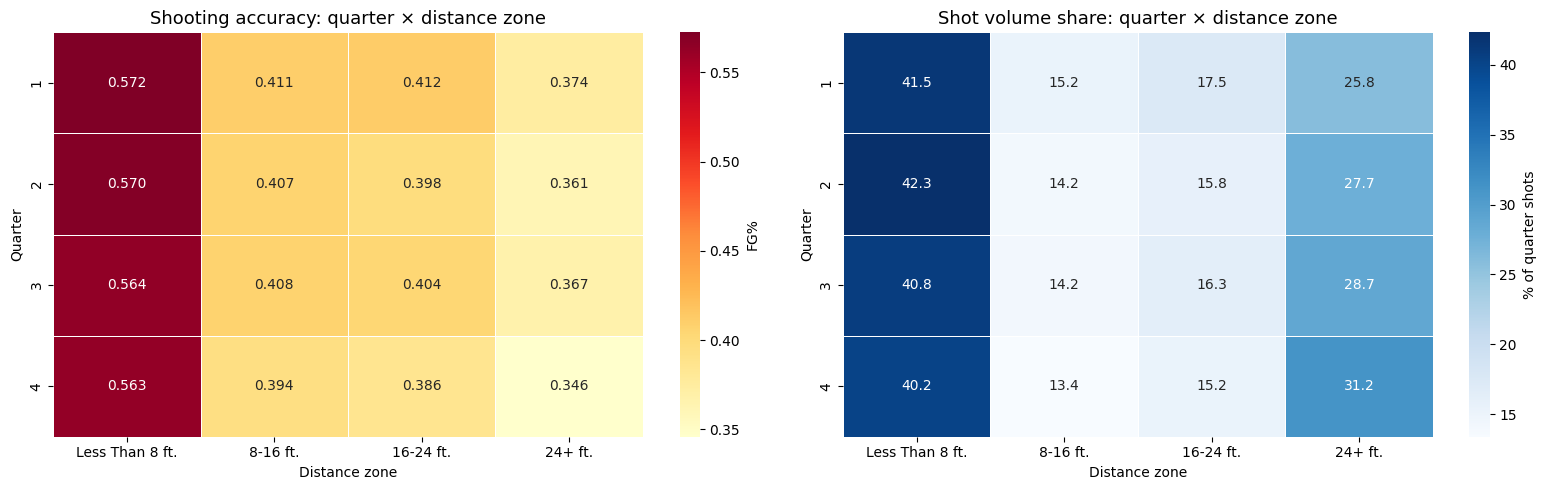

In [ ]:
zone_performance = cleaned_shots.groupby(['QUARTER', 'ZONE_RANGE']).agg(
    avg_accuracy=('SHOT_MADE', 'mean'),
    shot_count=('SHOT_MADE', 'count')
).reset_index()

zone_performance['quarter_total'] = zone_performance.groupby('QUARTER')['shot_count'].transform('sum')
zone_performance['pct_of_shots'] = (zone_performance['shot_count'] / zone_performance['quarter_total'] * 100).round(2)

ordered_zones = ['Less Than 8 ft.', '8-16 ft.', '16-24 ft.', '24+ ft.']
zone_performance['ZONE_RANGE'] = pd.Categorical(zone_performance['ZONE_RANGE'],
                                                categories=ordered_zones, ordered=True)
zone_performance = zone_performance.sort_values(['QUARTER', 'ZONE_RANGE'])

accuracy_pivot = zone_performance[zone_performance['QUARTER'] <= 4].pivot(
    index='QUARTER', columns='ZONE_RANGE', values='avg_accuracy'
)[ordered_zones]

volume_pivot = zone_performance[zone_performance['QUARTER'] <= 4].pivot(
    index='QUARTER', columns='ZONE_RANGE', values='pct_of_shots'
)[ordered_zones]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.heatmap(accuracy_pivot, annot=True, cmap='YlOrRd', fmt='.3f', ax=axes[0],
            linewidths=0.5, cbar_kws={'label': 'FG%'})
axes[0].set_title('Shooting accuracy: quarter × distance zone', fontsize=13)
axes[0].set_ylabel('Quarter')
axes[0].set_xlabel('Distance zone')

sns.heatmap(volume_pivot, annot=True, cmap='Blues', fmt='.1f', ax=axes[1],
            linewidths=0.5, cbar_kws={'label': '% of quarter shots'})
axes[1].set_title('Shot volume share: quarter × distance zone', fontsize=13)
axes[1].set_ylabel('Quarter')
axes[1].set_xlabel('Distance zone')

plt.tight_layout()
plt.savefig("shot_accuracy_heatmap.png", dpi=150, bbox_inches='tight')
plt.show()

Accuracy at the rim is consistently the highest regardless of quarter. 24+ ft accuracy dips in the 4th quarter, potentially due to game strategy, pressure situations, or fatigue. Shot distribution shifts slightly in later quarters, with 3s taking more of the share of shots as the game goes on.

In [ ]:
zone_performance = cleaned_shots.groupby(['QUARTER', 'ZONE_RANGE']).agg(
    avg_accuracy = ('SHOT_MADE', 'mean'),
    shot_count = ('SHOT_MADE', 'count')
).reset_index()

zone_performance['quarter_total'] = zone_performance.groupby('QUARTER')['shot_count'].transform('sum')
zone_performance['pct_of_shots'] = (zone_performance['shot_count'] / zone_performance['quarter_total'] * 100).round(2)
zone_performance['avg_accuracy'] = (zone_performance['avg_accuracy'] * 100).round(2)

ordered_zones = ['Less Than 8 ft.', '8-16 ft.', '16-24 ft.', '24+ ft.']
zone_performance['ZONE_RANGE'] = pd.Categorical(zone_performance['ZONE_RANGE'], categories = ordered_zones, ordered = True)
zone_performance = zone_performance.sort_values(['QUARTER', 'ZONE_RANGE']).reset_index(drop = True)

display(zone_performance[zone_performance['QUARTER'] <= 4])

,QUARTER,ZONE_RANGE,avg_accuracy,shot_count,quarter_total,pct_of_shots
0,1,Less Than 8 ft.,57.25,455882,1099942,41.45
1,1,8-16 ft.,41.08,167747,1099942,15.25
2,1,16-24 ft.,41.17,192186,1099942,17.47
3,1,24+ ft.,37.36,284127,1099942,25.83
4,2,Less Than 8 ft.,57.01,446291,1054606,42.32
5,2,8-16 ft.,40.67,149579,1054606,14.18
6,2,16-24 ft.,39.79,166494,1054606,15.79
7,2,24+ ft.,36.09,292242,1054606,27.71
8,3,Less Than 8 ft.,56.41,422351,1035012,40.81
9,3,8-16 ft.,40.78,147439,1035012,14.25


Close shot (Less than 8ft.) accuracy is the highest across all quarters (~56-57%) and remains stable, suggesting fatigue may not meaningfully affect close-range finishing. However, accuracy drops noticeably in Q4 for midrange and long-range shots. 3PT accuracy falls from 37.4% in Q1 to 34.6% in Q4. This decreased accuracy, combined with the higher volume of 3s late in games, indicates that teams take more 3s but also shoot worse. This could be due to pressure in tight games, loose play in blowouts, or fatigue setting in.

### 1.8 Shooting Trends by Season

In [ ]:
season_trends = cleaned_shots.groupby('SEASON_1').agg(
    attempts=('SHOT_MADE', 'count'),
    fg_pct=('SHOT_MADE', 'mean'),
    three_pt_rate=('SHOT_TYPE', lambda x: (x == '3PT Field Goal').mean()),
    avg_distance=('SHOT_DISTANCE', 'mean')
).reset_index().sort_values('SEASON_1')

season_trends['fg_pct'] = (season_trends['fg_pct'] * 100).round(2)
season_trends['three_pt_rate'] = (season_trends['three_pt_rate'] * 100).round(2)
season_trends['avg_distance'] = season_trends['avg_distance'].round(2)

display(season_trends)

,SEASON_1,attempts,fg_pct,three_pt_rate,avg_distance
0,2004,189358,43.96,18.51,11.50
1,2005,197148,44.85,19.41,11.64
2,2006,193833,45.48,20.03,11.68
3,2007,195571,45.94,21.05,11.72
4,2008,199904,45.85,21.99,12.03
5,2009,198473,46.00,22.17,11.90
6,2010,200400,46.26,21.97,11.73
7,2011,199205,45.98,21.95,12.02
8,2012,160841,44.89,22.39,11.97
9,2013,201093,45.38,24.14,12.05


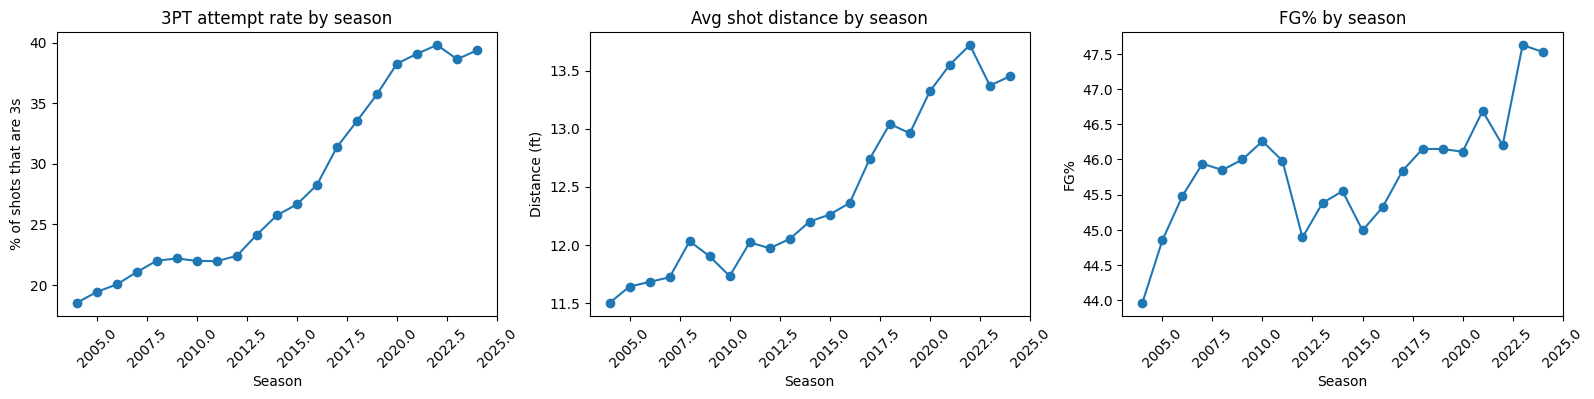

In [ ]:
fig, (p1, p2, p3) = plt.subplots(1, 3, figsize=(16, 4))

p1.plot(season_trends['SEASON_1'], season_trends['three_pt_rate'], marker='o')
p1.set_title('3PT attempt rate by season')
p1.set_xlabel('Season')
p1.set_ylabel('% of shots that are 3s')
p1.tick_params(axis='x', rotation=45)

p2.plot(season_trends['SEASON_1'], season_trends['avg_distance'], marker='o')
p2.set_title('Avg shot distance by season')
p2.set_xlabel('Season')
p2.set_ylabel('Distance (ft)')
p2.tick_params(axis='x', rotation=45)

p3.plot(season_trends['SEASON_1'], season_trends['fg_pct'], marker='o')
p3.set_title('FG% by season')
p3.set_xlabel('Season')
p3.set_ylabel('FG%')
p3.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

The data spans 2004 to 2024 and clearly captures the analytics and 3PT revolution in the NBA. 3PT attempt rate has more than doubled over this period, from 18.5% in 2004 to ~39% by 2022, with the steepest climb happening between 2015 and 2020. Average shot distance has followed the same trend, rising from 11.5ft in 2004 and peaking at 13.7ft in 2022. Despite the shift toward longer shots, overall FG% has seen a general upward trend from 43.96% in 2004 to 47% in 2024, which supports that trend of the league getting better at shot selection rather than just taking more 3s indiscriminately. Teams are replacing inefficient mid-range jumpers with corner 3s and at-rim attempts, both of which are high efficiency shots.

### 1.9 Zone Trends by Season

In [ ]:
zone_range_trends = cleaned_shots.groupby(['SEASON_1', 'ZONE_RANGE']).size().unstack(fill_value=0)
zone_range_distribution = zone_range_trends.divide(zone_range_trends.sum(axis=1), axis=0) * 100

ordered_zones = ['Less Than 8 ft.', '8-16 ft.', '16-24 ft.', '24+ ft.']
zone_range_distribution = zone_range_distribution[ordered_zones]

display(zone_range_distribution)

ZONE_RANGE,Less Than 8 ft.,8-16 ft.,16-24 ft.,24+ ft.
SEASON_1,,,,
2004,40.619884,17.950126,22.942258,18.487732
2005,40.510682,16.450078,23.666484,19.372755
2006,41.074533,15.207421,23.709585,20.008461
2007,41.271968,14.690828,23.018239,21.018965
2008,39.586001,14.896650,23.569814,21.947535
2009,40.332942,14.794960,22.744655,22.127443
2010,41.243014,14.953593,21.825848,21.977545
2011,41.800658,14.810873,21.429181,21.959288
2012,42.116749,14.630598,20.860353,22.392300


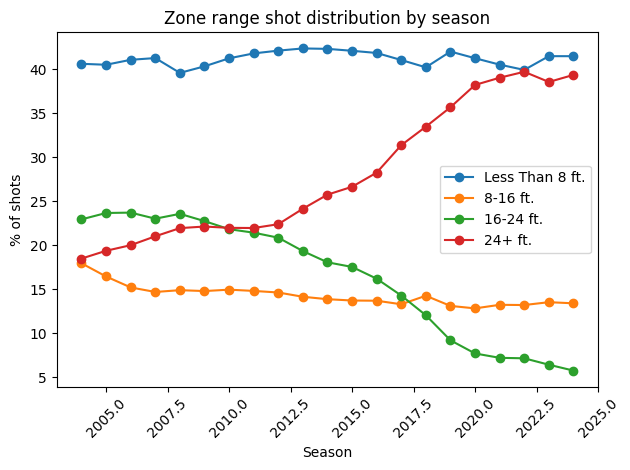

In [ ]:
for zone in ordered_zones:
    plt.plot(zone_range_distribution.index, zone_range_distribution[zone], marker='o', label=zone)

plt.title('Zone range shot distribution by season')
plt.xlabel('Season')
plt.ylabel('% of shots')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

When analyzing zone range distribution by season, the most striking trend is the steep decline of the 16-24 ft. midrange zone. In 2004, 22.9% of all shots came from this zone, but by 2024 it became nearly extinct at 5.8% of shots. This is the clearest visual evidence of the analytics revolution in basketball, as this zone represents the classic midrange jumper that offers 2 points at relatively low efficiency. At the same time, 24+ ft. attempts (3-pointers) have more than doubled from 18.5% in 2004 to 39.4% in 2024. The 8-16 ft. zone has also had a decline, while at-rim attempts (Less Than 8 ft.) have remained remarkably stable at around 40-42% throughout. This provides even more details that expand on the graphs in section 1.8.

In [ ]:
zone_name_trends = cleaned_shots.groupby(['SEASON_1', 'ZONE_NAME']).size().unstack(fill_value=0)
zone_name_mix = zone_name_trends.divide(zone_name_trends.sum(axis=1), axis=0) * 100

display(zone_name_mix)

ZONE_NAME,Center,Left Side,Left Side Center,Right Side,Right Side Center
SEASON_1,,,,,
2004,50.741981,15.377750,9.994825,13.642941,10.242504
2005,50.617810,14.639763,10.643273,13.376245,10.722909
2006,51.279710,14.120919,10.762873,12.828053,11.008445
2007,51.743357,13.793456,11.059411,12.206309,11.197468
2008,51.270610,13.218845,11.464003,12.411457,11.635085
2009,51.595431,13.398800,11.058431,12.390098,11.557240
2010,52.541417,12.963573,10.894711,12.201597,11.398703
2011,52.994654,12.782310,10.681961,12.108632,11.432444
2012,53.687803,12.291020,10.818759,11.684832,11.517586


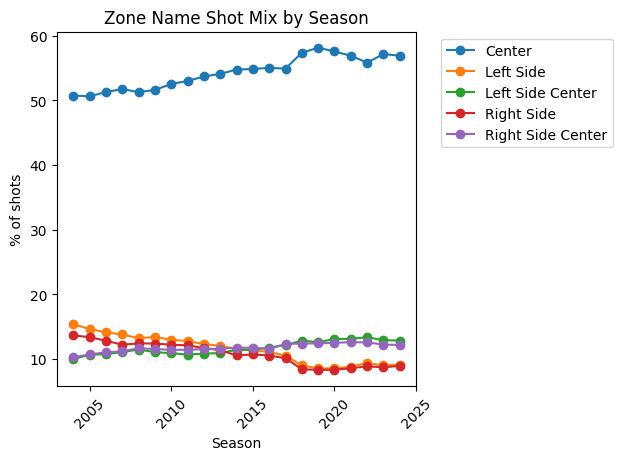

In [ ]:
for zone in zone_name_mix.columns:
    plt.plot(zone_name_mix.index, zone_name_mix[zone], marker='o', label=zone)

plt.title('Zone Name Shot Mix by Season')
plt.xlabel('Season')
plt.ylabel('% of shots')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The Center zone dominates throughout and has actually grown from 50.7% in 2004 to 56.9% in 2024, reflecting the consolidation of shots toward the paint and straight-on 3s. The most dramatic declines are on the sides, where the Left Side and Right Side zones have each dropped by roughly half, from 15% and 13% respectively in 2004 to 9% each by 2024. These side zones largely correspond to midrange pull-ups and side-angle 2PT jumpers that analytics has identified as the least efficient shots in basketball. Left Side Center and Right Side Center have remained relatively stable, likely because these zones capture corner 3s which are among the most efficient shots on the floor.

In [ ]:
corner_3s = cleaned_shots[
    (cleaned_shots['ZONE_NAME'].isin(['Left Side', 'Right Side'])) &
    (cleaned_shots['SHOT_TYPE'] == '3PT Field Goal')
]

corner_trends = corner_3s.groupby('SEASON_1').size()
total_by_season = cleaned_shots.groupby('SEASON_1').size()
corner_pct = (corner_trends / total_by_season * 100).round(2)

print("Corner 3s as % of all shots by season:")
print(corner_pct)

Corner 3s as % of all shots by season:
SEASON_1
2004     5.05
2005     5.51
2006     5.71
2007     5.99
2008     6.09
2009     6.41
2010     5.93
2011     6.19
2012     6.08
2013     6.72
2014     6.63
2015     7.00
2016     7.33
2017     7.48
2018     7.43
2019     8.22
2020     8.70
2021     9.29
2022    10.01
2023     9.75
2024    10.16
dtype: float64


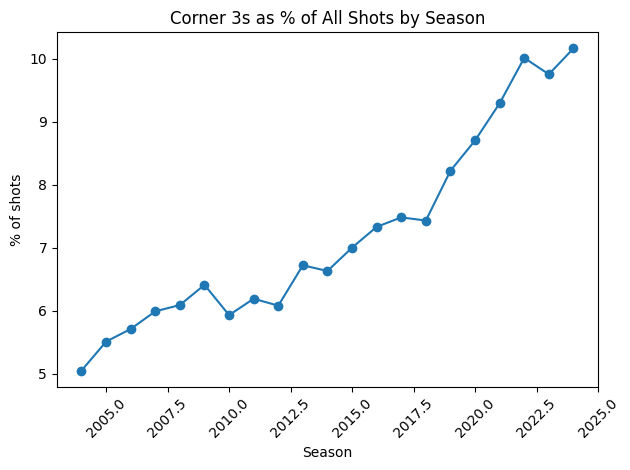

In [ ]:



















plt.plot(corner_pct.index, corner_pct.values, marker='o')
plt.title('Corner 3s as % of All Shots by Season')
plt.xlabel('Season')
plt.ylabel('% of shots')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Corner 3s have nearly doubled as a share of total shots over the past two decades, from 5.05% in 2004 to 10.16% in 2024. The growth is steady and consistent, with the steepest climb happening after 2018. This makes sense given that corner 3s are considered the most efficient shot in basketball. They have a shorter distance than above-the-break 3s (~22ft vs ~23.75ft)
with similar or better accuracy. Teams have clearly identified and exploited this, with the corner 3 becoming a staple of modern offensive systems.

### 1.10 Shooting Efficiency by Season

In [ ]:
zone_efficiency = cleaned_shots.groupby(['SEASON_1', 'ZONE_RANGE']).agg(
    fg_pct=('SHOT_MADE', 'mean')
).reset_index()
zone_efficiency['fg_pct'] = (zone_efficiency['fg_pct'] * 100).round(2)

zone_efficiency_pivot = zone_efficiency.pivot(index='SEASON_1', columns='ZONE_RANGE', values='fg_pct')
zone_efficiency_pivot = zone_efficiency_pivot[ordered_zones]

display(zone_efficiency_pivot)

ZONE_RANGE,Less Than 8 ft.,8-16 ft.,16-24 ft.,24+ ft.
SEASON_1,,,,
2004,53.66,37.70,38.81,35.13
2005,54.60,38.26,40.02,35.98
2006,55.27,39.02,40.45,36.24
2007,56.26,39.61,40.36,36.23
2008,56.44,39.11,40.87,36.67
2009,56.31,39.30,40.69,37.13
2010,57.25,40.05,40.22,35.86
2011,56.25,39.62,40.31,36.26
2012,55.16,38.87,38.78,35.18


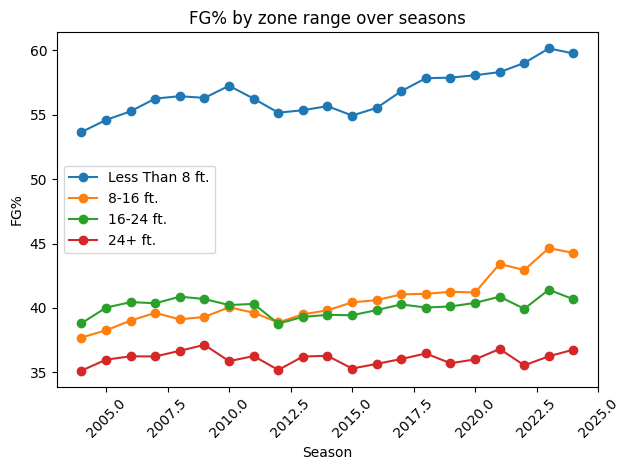

In [ ]:
for zone in ordered_zones:
    plt.plot(zone_efficiency_pivot.index, zone_efficiency_pivot[zone], marker='o', label=zone)

plt.title('FG% by zone range over seasons')
plt.xlabel('Season')
plt.ylabel('FG%')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

At-rim efficiency (Less Than 8 ft.) has improved meaningfully over the two decades, rising from 53.66% in 2004 to 59-60% by 2023-2024. Midrange efficiency (8-16 ft. and 16-24 ft.) has remained relatively flat throughout, hovering
around 38-41% and 38-41% respectively. This stability reinforces that the efficiency never improved, so the rational response was to simply take fewer of them.

Perhaps the most surprising finding is that 24+ ft. efficiency has barely changed at all, sitting around 35-37% throughout the entire period. Despite the massive increase in 3PT volume and the emergence of specialized shooters, the league as a whole has not gotten meaningfully better at making 3s. This suggests that as more players attempt 3s, the marginal shooter
entering the pool is offsetting any gains from specialization, keeping the overall rate flat. However, from a points-per-attempt standpoint, the 3s are still more efficient compared to midrange shots, hence why we have seen an increase in 3-point shots as a whole.

## 2: Player Info Dataset EDA

Here we explore the `nba_api_player_info` dataset independently before merging it with shot data. We want to understand:
- How many players are in the dataset and how they overlap with the shots data
- Distribution of physical attributes (height, weight) by position
- Draft year and experience trends

### 2.1 Basic Info

In [ ]:
player_info.info()
print(f"\nShape: {player_info.shape}")
print(f"\nMissing values:")
print(player_info.isnull().sum()[player_info.isnull().sum() > 0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2162 entries, 0 to 2161
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   person_id     2162 non-null   object 
 1   name          2162 non-null   object 
 2   birthdate     2162 non-null   object 
 3   position      2135 non-null   object 
 4   height        2135 non-null   object 
 5   weight        2135 non-null   float64
 6   school        2161 non-null   object 
 7   country       2162 non-null   object 
 8   draft_year    2162 non-null   object 
 9   draft_round   2112 non-null   object 
 10  draft_number  2110 non-null   object 
 11  from_year     2162 non-null   int64  
 12  to_year       2162 non-null   int64  
 13  team_name     1517 non-null   object 
 14  birth_year    2162 non-null   int64  
dtypes: float64(1), int64(3), object(11)
memory usage: 253.5+ KB

Shape: (2162, 15)

Missing values:
position         27
height           27
weight           27
s

In [ ]:
player_info.head(10)

,person_id,name,birthdate,position,height,weight,school,country,draft_year,draft_round,draft_number,from_year,to_year,team_name,birth_year
0,1000,Shandon Anderson,1973-12-31T00:00:00,Guard-Forward,6-6,215.0,Georgia,USA,1996,2,54,1996,2005,Knicks,1973
1,101106,Andrew Bogut,1984-11-28T00:00:00,Center,7-0,260.0,Utah,Australia,2005,1,1,2005,2018,Bucks,1984
2,101107,Marvin Williams,1986-06-19T00:00:00,Forward,6-8,237.0,North Carolina,USA,2005,1,2,2005,2019,Hawks,1986
3,101108,Chris Paul,1985-05-06T00:00:00,Guard,6-0,175.0,Wake Forest,USA,2005,1,4,2005,2025,NaN,1985
4,101109,Raymond Felton,1984-06-26T00:00:00,Guard,6-1,205.0,North Carolina,USA,2005,1,5,2005,2018,Bobcats,1984
5,101110,Martell Webster,1986-12-04T00:00:00,Forward-Guard,6-7,230.0,Seattle Preparatory HS (WA),USA,2005,1,6,2005,2014,Trail Blazers,1986
6,101111,Charlie Villanueva,1984-08-24T00:00:00,Forward,6-11,232.0,Connecticut,USA,2005,1,7,2005,2015,Pistons,1984
7,101112,Channing Frye,1983-05-17T00:00:00,Forward-Center,7-0,255.0,Arizona,USA,2005,1,8,2005,2018,Suns,1983
8,101113,Ike Diogu,1983-09-11T00:00:00,Forward,6-9,250.0,Arizona State,USA,2005,1,9,2005,2011,NaN,1983
9,101114,Deron Williams,1984-06-26T00:00:00,Guard,6-3,200.0,Illinois,USA,2005,1,3,2005,2016,Jazz,1984


### 2.2 Position Distribution

Before merging with the shots data, we want to understand how players are
distributed across positions. Position is one of the primary drivers of shot profile. Centers, forwards, and guards operate in different areas of the court.Knowing the position breakdown also helps us anticipate any class imbalance issues when we later cut the shooting data by position in section 4.

In [ ]:
pos_counts = player_info['position'].value_counts().reset_index()
pos_counts.columns = ['Position', 'Count']
pos_counts['Percentage'] = (pos_counts['Count'] / pos_counts['Count'].sum() * 100).round(2)
pos_counts

,Position,Count,Percentage
0,Guard,820,38.41
1,Forward,643,30.12
2,Center,238,11.15
3,Guard-Forward,157,7.35
4,Forward-Center,129,6.04
5,Center-Forward,80,3.75
6,Forward-Guard,68,3.19


We note that there are position combos such as Guard-Forward and Forward-Center. We will handle this in the cleaning section later on.

### 2.3 Height and Weight Distributions

Height is stored as a string in `feet-inches` format (for example, `"6-5"`). We convert this to total
inches for easier numerical analysis.

In [ ]:
player_info['height_inches'] = player_info['height'].apply(
    lambda h: int(h.split('-')[0]) * 12 + int(h.split('-')[1])
    if isinstance(h, str) and '-' in h else np.nan
)

print(f"Successfully parsed: {player_info['height_inches'].notna().sum()}")
print(f"Missing: {player_info['height_inches'].isna().sum()}")

player_info[player_info['height_inches'].isna()][['person_id', 'name', 'height']].head()

Successfully parsed: 2135
Missing: 27


,person_id,name,height
59,101180,Sarunas Jasikevicius,NaN
1139,200799,Guillermo Diaz,NaN
1144,200810,Allan Ray,NaN
1192,201164,Rudy Fernandez,NaN
1246,201576,Anthony Randolph,NaN


27 players have no height recorded in the source API data. These are mostly international players
and players from earlier seasons where biographical data is incomplete. Since this is a very small
fraction of the dataset, we leave these as NaN and exclude them from any height-based analysis.

In [ ]:
# Counting number of shots from players withi missing height
missing_height_ids = player_info[player_info['height_inches'].isna()]['person_id'].tolist()
all_shots[all_shots['PLAYER_ID'].astype(str).isin(missing_height_ids)]['PLAYER_NAME'].value_counts()

,count
PLAYER_NAME,
Andres Nocioni,4478
Tyler Hansbrough,2156
Rudy Fernandez,1853
Anthony Randolph,1494
Juan Carlos Navarro,766
Sarunas Jasikevicius,751
Jeffery Taylor,730
Marcus Fizer,659
Viktor Khryapa,567


All 27 players do appear in the shots dataset, so their records will be excluded from any
height-based analysis. The most significant omissions are Andres Nocioni (4,478 shots) and
Tyler Hansbrough (2,156 shots), though the overall impact is small relative to the full dataset
size.

In [ ]:
print(f"Players with weight: {player_info['weight'].notna().sum()}")
print(f"Missing: {player_info['weight'].isna().sum()}")


Players with weight: 2135
Missing: 27


In [ ]:
missing_height = player_info[player_info['height_inches'].isna()]['person_id'].tolist()
missing_weight = player_info[player_info['weight'].isna()]['person_id'].tolist()

print(set(missing_height) == set(missing_weight))

True


The exact same players missing height are also missing weight, indicating that this is an issue with the data source.

### 2.4 Height vs Weight by Position

In [ ]:
# Simplifying positions to 3 main categories for cleaner plots
def simplify_position(pos):
    pos = str(pos).upper()
    if 'CENTER' in pos: return 'Center'
    if 'FORWARD' in pos: return 'Forward'
    if 'GUARD' in pos: return 'Guard'
    return 'Other'

player_info['simple_position'] = player_info['position'].apply(simplify_position)

player_info['simple_position'].value_counts().reset_index().rename(columns={'simple_position': 'Position', 'count': 'Count'})


,Position,Count
0,Forward,868
1,Guard,820
2,Center,447
3,Other,27


In [ ]:
others = player_info[player_info['simple_position'] == 'Other']['person_id'].tolist()

print(set(others) == set(missing_height))

True


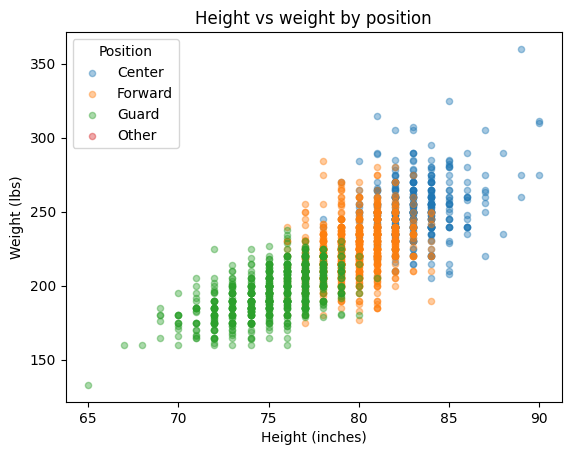

In [ ]:
for pos, grp in player_info.groupby('simple_position'):
    plt.scatter(grp['height_inches'], grp['weight'], label=pos, alpha=0.4, s=20)

plt.title('Height vs weight by position')
plt.xlabel('Height (inches)')
plt.ylabel('Weight (lbs)')
plt.legend(title='Position')
plt.show()

As expected, there are clear clusters in the height/weight space. Centers are the tallest and heaviest, guards are shorter and lighter, and forwards fall between. The 27 players with the "Other" position correspond exactly to the same 27 players with missing height data, confirming this is a data completeness
issue from the source API. These players will likely be
excluded from any position or physical attribute analysis during the cleaning phase.

## 3: Efficiency Metrics EDA

### 3.1 Player Expected Points

In [ ]:
# Calculate the previous season statistics

# Filtering backcourt shots for cleaner analysis
cleaned_shots = all_shots[all_shots['ZONE_NAME'] != 'Back Court'].copy()
cleaned_shots = cleaned_shots[cleaned_shots['ZONE_RANGE'] != 'Back Court Shot']


zone_stats_yr = cleaned_shots.groupby(['SEASON_1','SHOT_TYPE', 'ZONE_RANGE', 'BASIC_ZONE', 'ZONE_NAME']).agg(
    attempts = ('SHOT_MADE', 'count'),
    makes = ('SHOT_MADE', 'sum')
).reset_index()
zone_stats_yr['FG_PCT'] = (zone_stats_yr['makes'] / zone_stats_yr['attempts'] * 100).round(2)
zone_stats_yr = zone_stats_yr[zone_stats_yr['attempts'] >= 100].sort_values(['SEASON_1','FG_PCT'], ascending = False)

print("Shot efficiency by year by zone (min 100 attempts):")
display(zone_stats_yr)

Shot efficiency by year by zone (min 100 attempts):


,SEASON_1,SHOT_TYPE,ZONE_RANGE,BASIC_ZONE,ZONE_NAME,attempts,makes,FG_PCT
502,2024,2PT Field Goal,Less Than 8 ft.,Restricted Area,Center,64669,42884,66.31
498,2024,2PT Field Goal,8-16 ft.,Mid-Range,Center,2036,946,46.46
495,2024,2PT Field Goal,8-16 ft.,In The Paint (Non-RA),Center,12413,5657,45.57
496,2024,2PT Field Goal,8-16 ft.,In The Paint (Non-RA),Left Side,2262,1012,44.74
501,2024,2PT Field Goal,Less Than 8 ft.,In The Paint (Non-RA),Center,25865,11215,43.36
...,...,...,...,...,...,...,...,...
13,2004,2PT Field Goal,8-16 ft.,Mid-Range,Left Side,11556,4314,37.33
14,2004,2PT Field Goal,8-16 ft.,Mid-Range,Right Side,10735,3904,36.37
23,2004,3PT Field Goal,24+ ft.,Above the Break 3,Left Side Center,10093,3479,34.47
24,2004,3PT Field Goal,24+ ft.,Above the Break 3,Right Side Center,9957,3408,34.23


In [ ]:
# Calculate per game, per player expected points
# Use previous year shots data for current year efficiency metrics

zone_stats_yr_adj = zone_stats_yr.copy()
zone_stats_yr_adj['SEASON_1'] = zone_stats_yr_adj['SEASON_1'] + 1

expectedPoints = cleaned_shots[['SEASON_1', 'SHOT_TYPE', 'ZONE_RANGE', 'BASIC_ZONE', 'ZONE_NAME', 'SHOT_MADE', 'PLAYER_NAME', 'GAME_ID']] \
  .merge(zone_stats_yr_adj, how='left', on=['SEASON_1', 'SHOT_TYPE', 'ZONE_RANGE', 'BASIC_ZONE', 'ZONE_NAME'])

# Calculate individual shot and point data per row
expectedPoints['VALUE'] = expectedPoints['SHOT_TYPE'].map({'2PT Field Goal':2, '3PT Field Goal': 3})
expectedPoints['POINTS'] = expectedPoints['SHOT_MADE'].astype(int) * expectedPoints['VALUE']
expectedPoints['EXPECTED_POINTS'] = expectedPoints['VALUE'].astype(int) * (expectedPoints['FG_PCT'] / 100)



Leveraging the previous year seasonal league averages in granularity, we will compare the next season per game, per player performance agains the expectation given the type shots the player has taken.

In [ ]:
# Seasonal data

expectedPointsGroup = expectedPoints.groupby(['SEASON_1','PLAYER_NAME', 'GAME_ID', 'SHOT_TYPE', 'ZONE_RANGE', 'BASIC_ZONE', 'ZONE_NAME']).agg(
    shots=('SHOT_MADE', 'size'),
    points_scored=('POINTS', 'sum'),
    expected_points=('EXPECTED_POINTS', 'sum')
).sort_values("SEASON_1", ascending=False)

expectedPointsGroup['expected_point_plus_minus'] = expectedPointsGroup['points_scored'] - expectedPointsGroup['expected_points']

In [ ]:
expectedPointsGroup

shots  \
SEASON_1 PLAYER_NAME     GAME_ID  SHOT_TYPE      ZONE_RANGE      BASIC_ZONE            ZONE_NAME                  
2024     Zion Williamson 22301157 2PT Field Goal 8-16 ft.        In The Paint (Non-RA) Center                 1   
                         22301170 2PT Field Goal Less Than 8 ft. Restricted Area       Center                 8   
                         22301230 2PT Field Goal Less Than 8 ft. Restricted Area       Center                 4   
                                                                 In The Paint (Non-RA) Center                 2   
                                                 8-16 ft.        In The Paint (Non-RA) Right Side             1   
...                                                                                                         ...   
2004     Aaron McKie     20300039 2PT Field Goal 16-24 ft.       Mid-Range             Left Side              2   
                         20300026 2PT Field Goal Less Than 8 ft. Restricted Area       Center                 1   
                                                 8-16 ft.        Mid-Range             Right Side             1   
                                                 16-24 ft.       Mid-Range             Right Side Center      1   
                                                                                       Left Side Center       1   

                                                                                                          points_scored  \
SEASON_1 PLAYER_NAME     GAME_ID  SHOT_TYPE      ZONE_RANGE      BASIC_ZONE            ZONE_NAME                          
2024     Zion Williamson 22301157 2PT Field Goal 8-16 ft.        In The Paint (Non-RA) Center                         0   
                         22301170 2PT Field Goal Less Than 8 ft. Restricted Area       Center                        14   
                         22301230 2PT Field Goal Less Than 8 ft. Restricted Area       Center                         6   
                                                                 In The Paint (Non-RA) Center                         4   
                                                 8-16 ft.        In The Paint (Non-RA) Right Side                     2   
...                                                                                                                 ...   
2004     Aaron McKie     20300039 2PT Field Goal 16-24 ft.       Mid-Range             Left Side                      0   
                         20300026 2PT Field Goal Less Than 8 ft. Restricted Area       Center                         2   
                                                 8-16 ft.        Mid-Range             Right Side                     2   
                                                 16-24 ft.       Mid-Range             Right Side Center              0   
                                                                                       Left Side Center               0   

                                                                                                          expected_points  \
SEASON_1 PLAYER_NAME     GAME_ID  SHOT_TYPE      ZONE_RANGE      BASIC_ZONE            ZONE_NAME                            
2024     Zion Williamson 22301157 2PT Field Goal 8-16 ft.        In The Paint (Non-RA) Center                      0.9264   
                         22301170 2PT Field Goal Less Than 8 ft. Restricted Area       Center                     10.6608   
                         22301230 2PT Field Goal Less Than 8 ft. Restricted Area       Center                      5.3304   
                                                                 In The Paint (Non-RA) Center                      1.7316   
                                                 8-16 ft.        In The Paint (Non-RA) Right Side                  0.9036   
...                                                                                                                   ...   
2004     A

In [ ]:
# Performance
mean = expectedPointsGroup['expected_point_plus_minus'].mean()
std = expectedPointsGroup['expected_point_plus_minus'].std()
print(mean, std)

expectedPointsGroup['expected_point_effeciency'] = np.where(expectedPointsGroup['expected_point_plus_minus'] > mean + std, 1, np.where(expectedPointsGroup['expected_point_plus_minus'] < mean - std, -1, 0))


0.08460357913591711 1.5977293133325403


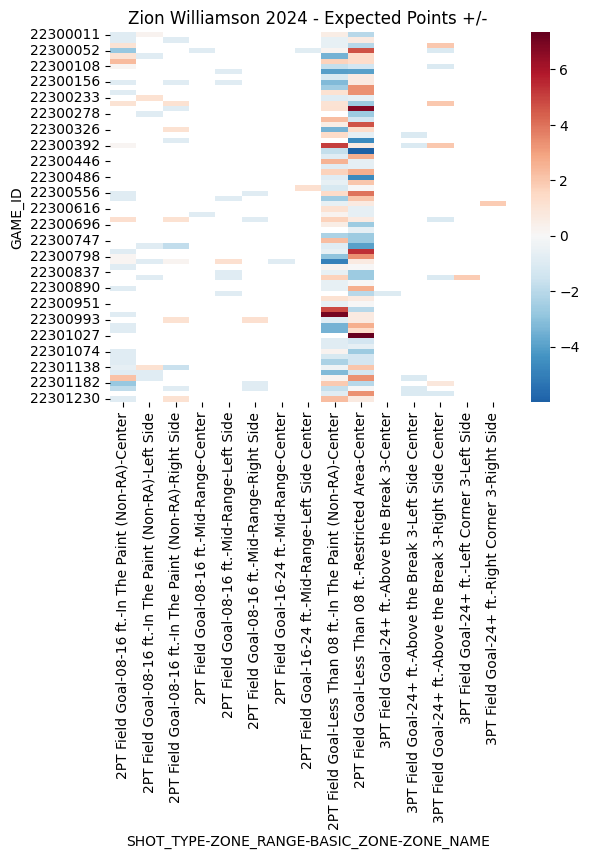

In [ ]:
# Heatmap - Zion Williamson
zion = expectedPointsGroup.xs((2024, 'Zion Williamson'), level=('SEASON_1', 'PLAYER_NAME')).sort_values('GAME_ID').reset_index()
## Clean up data
zone_sort = {
    'Less Than 8 ft.': 'Less Than 08 ft.',
    '8-16 ft.': '08-16 ft.',
}
zion['ZONE_RANGE'] = zion['ZONE_RANGE'].replace(zone_sort)


## Pivot to indicator x and y values for heatmap
zion_pivot = zion.pivot_table(
    index='GAME_ID',
    columns=['SHOT_TYPE', 'ZONE_RANGE', 'BASIC_ZONE', 'ZONE_NAME'],
    values='expected_point_plus_minus',
    aggfunc='sum'
)

sns.heatmap(zion_pivot, annot=False, fmt='.1f', cmap='RdBu_r', center=0)
plt.title("Zion Williamson 2024 - Expected Points +/-")
plt.show()

After analyzing the heatmap for a few matches in 2024 for Zion Williamson, you can identify which shots he has taken in the match where he performed worse than expectation, in addition, other places where he outperformed expectation. There does not exist a centralized cluster, but a lot of Zion Williamson's "game" are *"2PT Field Goals-Less than 08 ft. In the Paint (Non-RA) Center"* and *"2PT Field Goals-Less than 08 ft. Restricted Area"*; but we notice that he is very inconsistent and often under performs. It's worth noting that being below expected points does not necessarily mean a player is inefficient in absolute terms. Zion operates almost entirely in high-expectation zones like the restricted area where the league average is already above 60%, so the bar he is measured against on every shot is significantly higher than it would be for a player whose diet includes more 3s and midrange attempts. A missed layup costs more in expected points terms than a missed 3.



In [ ]:
zion_pivot

SHOT_TYPE         2PT Field Goal                                           \
ZONE_RANGE             08-16 ft.                                            
BASIC_ZONE In The Paint (Non-RA)                      Mid-Range             
ZONE_NAME                 Center Left Side Right Side    Center Left Side   
GAME_ID                                                                     
22300011                 -0.9264     0.230        NaN       NaN       NaN   
22300022                 -0.9264       NaN    -0.9036       NaN       NaN   
22300034                  1.0736       NaN        NaN       NaN       NaN   
22300052                 -2.7792       NaN        NaN   -0.9044       NaN   
22300071                  1.0736    -0.885        NaN       NaN       NaN   
...                          ...       ...        ...       ...       ...   
22301170                  2.1472    -0.885        NaN       NaN       NaN   
22301182                 -2.7792       NaN        NaN       NaN       NaN   
22301195                 -1.8528       NaN    -0.9036       NaN       NaN   
22301204                     NaN       NaN        NaN       NaN       NaN   
22301230                 -0.9264       NaN     1.0964       NaN       NaN   

SHOT_TYPE                                                               \
ZONE_RANGE            16-24 ft.                       Less Than 08 ft.   
BASIC_ZONE            Mid-Range                  In The Paint (Non-RA)   
ZONE_NAME  Right Side    Center Left Side Center                Center   
GAME_ID                                                                  
22300011          NaN       NaN              NaN                0.5368   
22300022          NaN       NaN              NaN               -0.5974   
22300034          NaN       NaN              NaN               -0.5974   
22300052          NaN       NaN          -0.8178                0.2078   
22300071          NaN       NaN              NaN               -3.4632   
...               ...       ...              ...                   ...   
22301170          NaN       NaN              NaN                0.2078   
22301182      -0.8522       NaN              NaN                1.8788   
22301195      -0.8522       NaN              NaN               -1.7316   
22301204          NaN       NaN              NaN               -0.8658   
22301230          NaN       NaN              NaN                2.2684   

SHOT_TYPE                     3PT Field Goal                   \
ZONE_RANGE                           24+ ft.                    
BASIC_ZONE Restricted Area Above the Break 3                    
ZONE_NAME           Center            Center Left Side Center   
GAME_ID                                                         
22300011           -1.9934               NaN              NaN   
22300022            0.6740               NaN              NaN   
22300034           -1.9912               NaN              NaN   
22300052            4.6740               NaN              NaN   
22300071            1.3414               NaN              NaN   
...                    ...               ...              ...   
22301170            3.3392               NaN          -1.0755   
22301182           -1.9956               NaN              NaN   
22301195            0.0044               NaN          -1.0755   
22301204            3.3370               NaN          -1.0755   
22301230            0.6696               NaN              NaN   

SHOT_TYPE                                                  
ZONE_RANGE                                                 
BASIC_ZONE                   Left Corner 3 Right Corner 3  
ZONE_NAME  Right Side Center     Left Side     Right Side  
GAME_ID                                                    
22300011                 NaN           NaN            NaN  
22300022                 NaN           NaN            NaN  
22300034              1.9311           NaN            NaN  
22300052             -1.0689           NaN            NaN  
2

The heatmap shares the expected points and its performance by a sample of games for Zion Williamson depending on the shot type, zone range, basic zone, and zone name. Red colors in the heatmap showcases an efficient players match for the shot type as it would be better than the expectation.

For example, if the shooting percentage for corner 3 point shot is 50%, if a player takes one shot in the following season game from that area, *the expectations would be 1.5 points for the shot attempt*; but if they miss the shot they are below expectations since **1.5 > 0**. Now if the player took two shots and made 1, they are at expectation since **1.5*2 = 3**. If they player made both shots they would be above expectation since **1.5*2 < 6**.

Using "Expected Points", we can understand what is the players shot quality relative to the previous season league averages for the shot type, zone range basic zone, and zone name. Players who have a expected points lower than 0 performed worse than league average for the game, and players above 0 performed better. Players around 0 performed on average and to expectation.

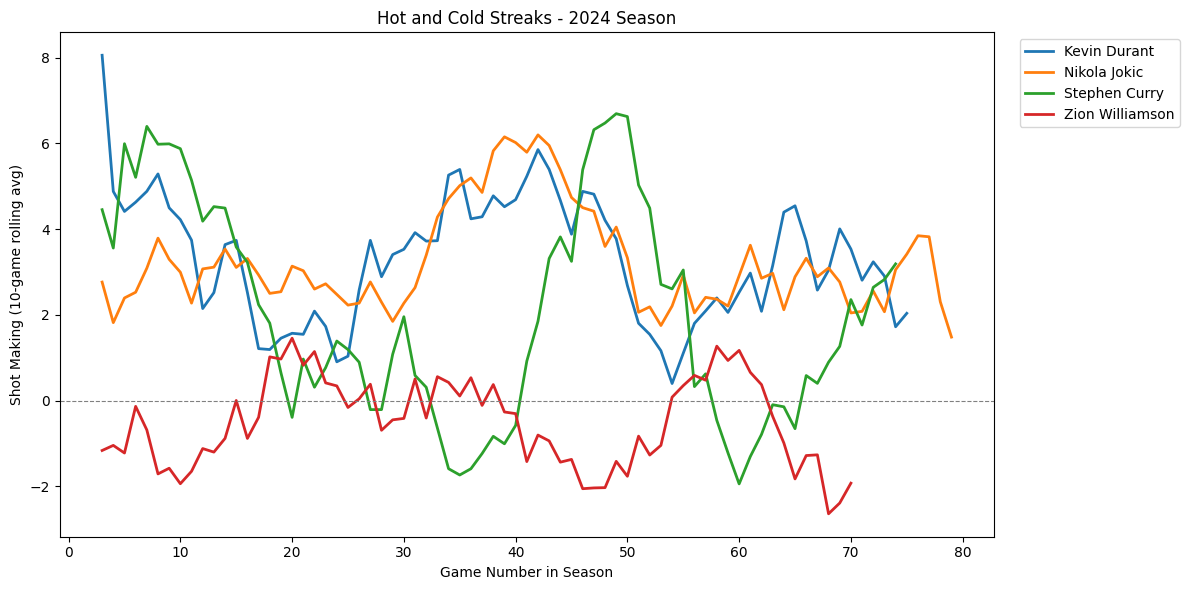

In [ ]:
# Group zone-level rows into one row per player per game
per_game = (
    expectedPointsGroup.reset_index()
    .groupby(['SEASON_1', 'PLAYER_NAME', 'GAME_ID'])
    .agg(shots=('shots', 'sum'),
         points_scored=('points_scored', 'sum'),
         expected_points=('expected_points', 'sum'))
    .reset_index()
)
per_game['plus_minus'] = per_game['points_scored'] - per_game['expected_points']
per_game = per_game.sort_values(['PLAYER_NAME', 'SEASON_1', 'GAME_ID'])
per_game['game_num'] = per_game.groupby(['SEASON_1', 'PLAYER_NAME']).cumcount() + 1

# 10-game rolling average of plus/minus
per_game['rolling_pm'] = (
    per_game.groupby(['SEASON_1', 'PLAYER_NAME'])['plus_minus']
    .transform(lambda s: s.rolling(10, min_periods=3).mean()) # low min_periods keeps early season lines visible in the plot
)

players = ['Zion Williamson', 'Kevin Durant', 'Stephen Curry', 'Nikola Jokic']
subset = per_game[(per_game['SEASON_1'] == 2024) & (per_game['PLAYER_NAME'].isin(players))]

plt.figure(figsize=(12, 6))
sns.lineplot(data=subset, x='game_num', y='rolling_pm',
             hue='PLAYER_NAME', linewidth=2)
plt.axhline(0, color='gray', lw=0.8, linestyle='--')
plt.xlabel('Game Number in Season')
plt.ylabel('Shot Making (10-game rolling avg)')
plt.title('Hot and Cold Streaks - 2024 Season')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

When taking a look at the expected points over a rolling 10-game average, you can tell, when comparing star players that Zion Williamson is much less efficient than Kevin Durant, Nikola Jokic, and Stephen Curry. While there are stretches of time where Zion performs better compared to expected, other players consistently perform more efficiently. Stephen Curry has also seen stretches of poor efficiency while Kevin Durant and Nikola Jokic are very efficient.

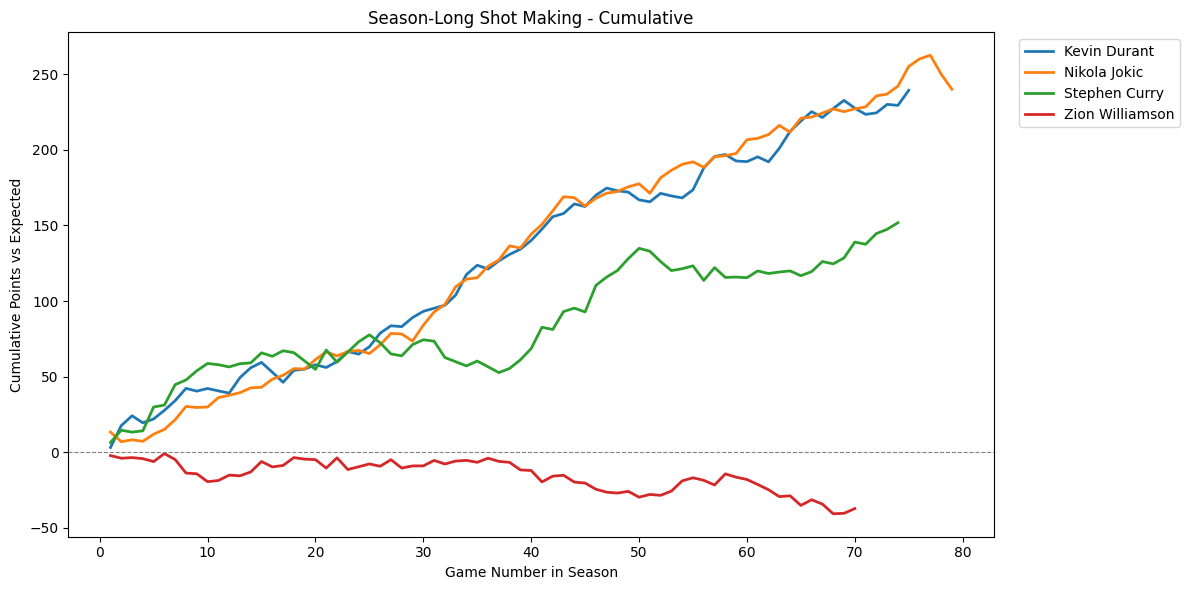

In [ ]:
per_game['cumulative_pm'] = (
    per_game.groupby(['SEASON_1', 'PLAYER_NAME'])['plus_minus'].cumsum()
)

subset = per_game[(per_game['SEASON_1'] == 2024) & (per_game['PLAYER_NAME'].isin(players))]

plt.figure(figsize=(12, 6))
sns.lineplot(data=subset, x='game_num', y='cumulative_pm',
             hue='PLAYER_NAME', linewidth=2)
plt.axhline(0, color='gray', lw=0.8, linestyle='--')
plt.xlabel('Game Number in Season')
plt.ylabel('Cumulative Points vs Expected')
plt.title('Season-Long Shot Making - Cumulative')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

From an efficiency perspective, you can notice a few things; in 2024 Zion Williamson was consistently under performing compared to expected points all season long. While other star players are scoring above the expected points and cumulatively improving.



### 3.2 Clutch / Late Game

In [ ]:
# Flag clutch shots: Q4 or OT with under 5 minutes remaining
all_shots['IS_CLUTCH'] = ((all_shots['QUARTER'] >= 4) & (all_shots['MINS_LEFT'] <= 4)).astype(int)

# Overall clutch vs non-clutch
all_shots.groupby('IS_CLUTCH').agg(
    ATTEMPTS=('SHOT_MADE', 'count'),
    FG_PCT=('SHOT_MADE', 'mean'),
    THREE_PT_RATE=('SHOT_TYPE', lambda x: (x == '3PT Field Goal').mean()),
)

,ATTEMPTS,FG_PCT,THREE_PT_RATE
IS_CLUTCH,,,
0,3768877,0.460186,0.279346
1,462385,0.437220,0.331711


In [ ]:
all_shots.groupby(['IS_CLUTCH', 'SHOT_TYPE']).agg(
    ATTEMPTS=('SHOT_MADE', 'count'),
    FG_PCT=('SHOT_MADE', 'mean'),
)

ATTEMPTS    FG_PCT
IS_CLUTCH SHOT_TYPE                         
0         2PT Field Goal   2716056  0.497941
          3PT Field Goal   1052821  0.362788
1         2PT Field Goal    309007  0.492122
          3PT Field Goal    153378  0.326611

In [ ]:
all_shots.groupby(['IS_CLUTCH', 'ZONE_RANGE']).agg(
    ATTEMPTS=('SHOT_MADE', 'count'),
    FG_PCT=('SHOT_MADE', 'mean'),
)

ATTEMPTS    FG_PCT
IS_CLUTCH ZONE_RANGE                         
0         16-24 ft.          617519  0.403113
          24+ ft.           1042213  0.365912
          8-16 ft.           544667  0.406973
          Back Court Shot      9740  0.026899
          Less Than 8 ft.   1554738  0.567408
1         16-24 ft.           66662  0.374516
          24+ ft.            152666  0.327801
          8-16 ft.            58423  0.387912
          Back Court Shot       618  0.030744
          Less Than 8 ft.    184016  0.567733

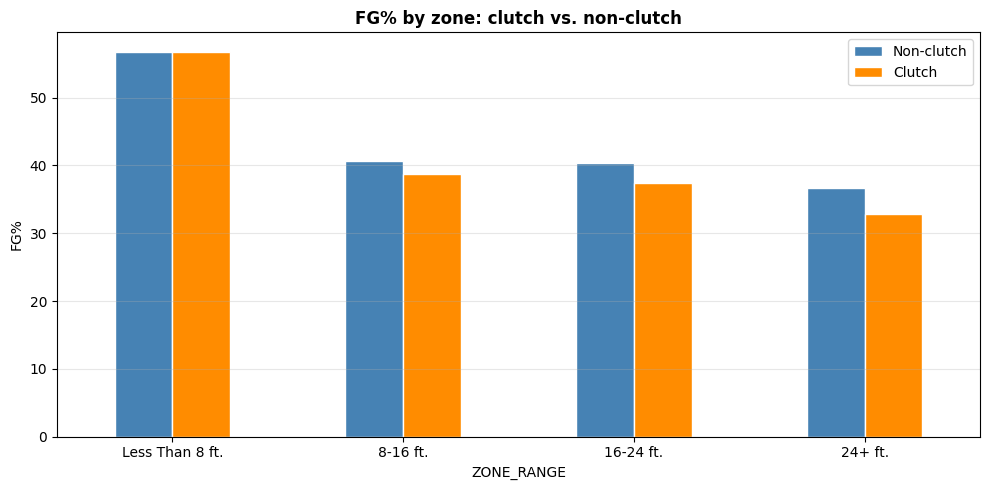

In [ ]:
ordered_zones = ['Less Than 8 ft.', '8-16 ft.', '16-24 ft.', '24+ ft.']

fg_pivot = (all_shots[all_shots['ZONE_RANGE'].isin(ordered_zones)]
            .groupby(['ZONE_RANGE', 'IS_CLUTCH'])['SHOT_MADE'].mean()
            .unstack() * 100).loc[ordered_zones]
fg_pivot.columns = ['Non-clutch', 'Clutch']

fg_pivot.plot(kind='bar', figsize=(10, 5), color=['steelblue', 'darkorange'],
              edgecolor='white', rot=0)
plt.ylabel('FG%')
plt.title('FG% by zone: clutch vs. non-clutch', fontweight='bold')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Historically, *when* a shot is taken matters. We see a clear decrease in field goal percentage during "clutch" moments, which is defined here as the final 5 minutes of Q4 or any overtime period. Q4 and overtime are grouped together since both represent late-game, high-leverage situations where we expect pressure to affect shot selection.

Overall FG% drops from 46.0% in non-clutch situations to 44.0% in clutch, a decline of roughly 2 percentage points. Breaking this down by shot type reveals that 2PT efficiency is nearly unchanged (49.8% to 49.2%), while 3PT efficiency drops more noticeably (36.3% to 33.1%). In other words, almost all of the overall clutch penalty is concentrated in 3-point shooting.

Shot selection also shifts meaningfully in clutch moments. The ratio of 2PT to 3PT attempts moves by roughly 5 percentage points toward 3s:

| Situation   | 2PT attempts | 3PT attempts | 2PT share | 3PT share |
|-------------|--------------|--------------|-----------|-----------|
| Non-clutch  | 2,658,987    | 1,028,328    | 72%       | 28%       |
| Clutch      | 366,076      | 177,871      | 67%       | 33%       |

So the overall 2-point FG% drop in clutch is really two effects compounding: teams take a higher share of 3s (which are lower-efficiency by nature), and those 3s are themselves harder to make under late-game pressure.

Rim shots (Less Than 8 ft.) are essentially unaffected by clutch pressure. The FG% holds steady at 56.7% in both clutch and non-clutch situations, suggesting that close-range finishing is not affected in the clutch. The clutch penalty scales with distance: 8-16 ft. drops by 1.8 points (40.7% → 38.9%), 16-24 ft. drops by 2.6 points (40.3% → 37.8%), and 24+ ft. drops by 3.4 points (36.6% → 33.2%).

### 3.3 Does the "Hot-Hand" Exist?

In [ ]:
# Sort the shots
hot_hand = all_shots.sort_values(['GAME_DATE', 'GAME_ID', 'PLAYER_ID']).copy()
hot_hand['shot_number'] = hot_hand.groupby(['PLAYER_ID', 'GAME_ID']).cumcount() + 1

# Clean for players who have taken atleast 5 shots
shot_counts = hot_hand.groupby(['PLAYER_ID', 'GAME_ID'])['SHOT_MADE'].transform('count')
hot_hand = hot_hand[shot_counts >= 5].copy()

In [ ]:
# Review the last three shots from a player
hot_hand['prev3_makes'] = (
    hot_hand.groupby(['PLAYER_ID', 'GAME_ID'])['SHOT_MADE'].transform(lambda shot: shot.shift(1).rolling(3).sum())
)

# Filter for data with 3 shot minimums
shot_history_3 = hot_hand.dropna(subset=['prev3_makes']).copy()
shot_history_3['prev3_makes'] = shot_history_3['prev3_makes'].astype(int)

# Label the history
cold = shot_history_3[shot_history_3['prev3_makes'] == 0]['SHOT_MADE'].mean()
hot = shot_history_3[shot_history_3['prev3_makes'] == 3]['SHOT_MADE'].mean()
base = shot_history_3['SHOT_MADE'].mean()

print("FG% average", cold)
print("FG% for being cold (last 3 miss)", cold)
print("FG% for being hot (last 3 make)", hot)
print("FG% for Cold/Hot Delta", hot - cold)


FG% average 0.47461592395270413
FG% for being cold (last 3 miss) 0.47461592395270413
FG% for being hot (last 3 make) 0.4681499509999246
FG% for Cold/Hot Delta -0.0064659729527795085


In [ ]:
conditional_fg = shot_history_3.groupby('prev3_makes').agg(
    ATTEMPTS=('SHOT_MADE', 'count'),
    FG_PCT = ('SHOT_MADE', 'mean')
).reset_index()

conditional_fg['FG_PCT'] = round(conditional_fg['FG_PCT'],2)

conditional_fg

,prev3_makes,ATTEMPTS,FG_PCT
0,0,419318,0.47
1,1,1121268,0.47
2,2,978690,0.47
3,3,278571,0.47


In [ ]:
# See hot/cold/overall FG% by season

season_hot_hand = shot_history_3.groupby('SEASON_1').apply(
    lambda g: pd.Series({
        'attempts': len(g),
        'fg_pct_overall': g['SHOT_MADE'].mean(),
        'fg_pct_cold': g.loc[g['prev3_makes'] == 0, 'SHOT_MADE'].mean(),
        'fg_pct_hot':  g.loc[g['prev3_makes'] == 3, 'SHOT_MADE'].mean(),
    })
).reset_index()

season_hot_hand['hot_cold_delta'] = season_hot_hand['fg_pct_hot'] - season_hot_hand['fg_pct_cold']

# Convert to percentages for display
for col in ['fg_pct_overall', 'fg_pct_cold', 'fg_pct_hot', 'hot_cold_delta']:
    season_hot_hand[col] = (season_hot_hand[col] * 100).round(2)

season_hot_hand

,SEASON_1,attempts,fg_pct_overall,fg_pct_cold,fg_pct_hot,hot_cold_delta
0,2004,125087.0,45.48,46.19,44.61,-1.58
1,2005,130135.0,46.42,46.66,45.00,-1.66
2,2006,127976.0,46.96,48.05,45.83,-2.22
3,2007,129121.0,47.48,48.04,46.78,-1.26
4,2008,132835.0,47.40,48.51,46.84,-1.66
5,2009,131962.0,47.43,48.26,46.38,-1.89
6,2010,133108.0,47.84,47.86,47.38,-0.48
7,2011,131118.0,47.54,47.69,47.09,-0.60
8,2012,104634.0,46.62,46.40,45.52,-0.88
9,2013,131587.0,46.99,47.66,45.99,-1.68


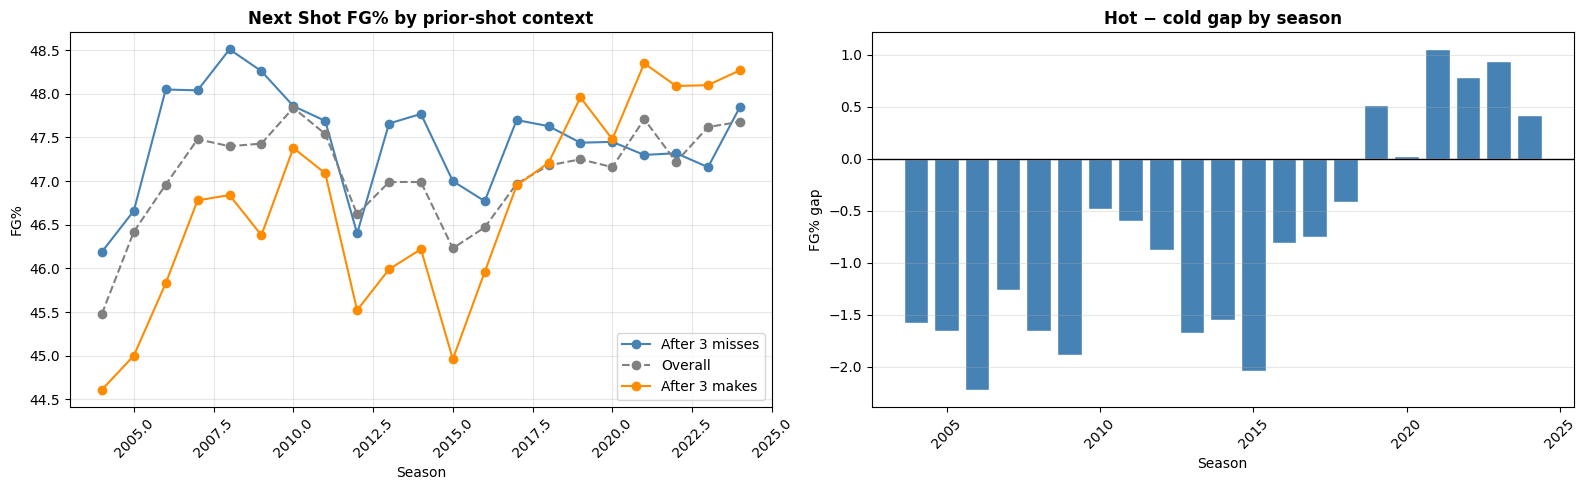

In [ ]:
fig, (p1, p2) = plt.subplots(1, 2, figsize=(16, 5))

# Plot Cold
p1.plot(season_hot_hand['SEASON_1'], season_hot_hand['fg_pct_cold'],
        marker='o', label='After 3 misses', color='steelblue')

# Plt Average
p1.plot(season_hot_hand['SEASON_1'], season_hot_hand['fg_pct_overall'],
        marker='o', label='Overall', color='gray', linestyle='--')
# Plot Hot
p1.plot(season_hot_hand['SEASON_1'], season_hot_hand['fg_pct_hot'],
        marker='o', label='After 3 makes', color='darkorange')

# Labels
p1.set_title('Next Shot FG% by prior-shot context', fontweight='bold')
p1.set_xlabel('Season')
p1.set_ylabel('FG%')
p1.tick_params(axis='x', rotation=45)
p1.legend()
p1.grid(alpha=0.3)

# Plt the delta
p2.bar(season_hot_hand['SEASON_1'], season_hot_hand['hot_cold_delta'],
       color='steelblue', edgecolor='white')
p2.axhline(0, color='black', lw=1)
p2.set_title('Hot − cold gap by season', fontweight='bold')
p2.set_xlabel('Season')
p2.set_ylabel('FG% gap')
p2.tick_params(axis='x', rotation=45)
p2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

At first glance, pooling all 20 seasons together suggests no meaningful hot-hand effect. But breaking the data out by season reveals a clear shift around 2017-2018.

From 2004 through 2017, the hot-cold gap is consistently negative, hovering between -0.5 and -2 percentage points.

From 2019 onward, the gap flips positive, reaching roughly +1 in 2021-2024. One potential explanation for this era shift is the broader move toward smarter shot selection. In the early 2000s, a player who had just made three shots in a row was likely being fed increasingly difficult looks as defenses adjusted, which would naturally reduce their FG% for the next shot. In the modern era, offenses are better designed to leverage a hot shooter via spacing the floor, running them off screens, getting them open catch-and-shoot looks, etc. This means the hot hand actually gets better shots to work with. The data doesn't let us separate those two effects, but the timing of the shift aligns closely with the analytics revolution that reshaped how teams manage offensive possessions.

## 4: Combining Datasets and Additional EDA

### 4.1 Merging Shooting and Player Info Datasets and Coverage Check

Now that we've explored both datasets independently, we merge them based on player ID to bring the shot-level data and player attributes together into one view. This lets us cut the shooting data by position, age, and physical attributes which weren't available in the shots dataset alone. We do a left join so we retain all shots and simply leave player attributes as NaN for any players not found in the player info dataset, then check coverage to understand how much of the shot data we can actually use.

In [ ]:
cleaned_shots['PLAYER_ID'] = cleaned_shots['PLAYER_ID'].astype(str)

merged = cleaned_shots.merge(
    player_info,
    left_on='PLAYER_ID',
    right_on='person_id',
    how='left'
)

total = len(cleaned_shots)
matched = merged['height_inches'].notna().sum()
print(f"Total shots (excl. backcourt): {total:,}")
print(f"Shots matched to player info: {matched:,} ({matched/total*100:.1f}%)")
print(f"Unmatched shots: {total-matched:,}")
merged.head()

Total shots (excl. backcourt): 4,220,904
Shots matched to player info: 4,203,880 (99.6%)
Unmatched shots: 17,024


,SEASON_1,SEASON_2,TEAM_ID,TEAM_NAME,PLAYER_ID,PLAYER_NAME,POSITION_GROUP,POSITION,GAME_DATE,GAME_ID,HOME_TEAM,AWAY_TEAM,EVENT_TYPE,SHOT_MADE,ACTION_TYPE,SHOT_TYPE,BASIC_ZONE,ZONE_NAME,ZONE_ABB,ZONE_RANGE,LOC_X,LOC_Y,SHOT_DISTANCE,QUARTER,MINS_LEFT,SECS_LEFT,person_id,name,birthdate,position,height,weight,school,country,draft_year,draft_round,draft_number,from_year,to_year,team_name,birth_year,height_inches,simple_position
0,2004,2003-04,1610612747,Los Angeles Lakers,977,Kobe Bryant,G,SG,04-14-2004,20301187,POR,LAL,Made Shot,True,Jump Shot,3PT Field Goal,Above the Break 3,Left Side Center,LC,24+ ft.,20.0,21.35,25,6,0,0,977,Kobe Bryant,1978-08-23T00:00:00,Forward-Guard,6-6,212.0,Lower Merion HS (PA),USA,1996,1,13,1996,2015,Lakers,1978,78.0,Forward
1,2004,2003-04,1610612757,Portland Trail Blazers,757,Damon Stoudamire,G,PG,04-14-2004,20301187,POR,LAL,Made Shot,True,Driving Layup Shot,2PT Field Goal,Restricted Area,Center,C,Less Than 8 ft.,-0.0,5.25,0,6,0,2,757,Damon Stoudamire,1973-09-03T00:00:00,Guard,5-10,171.0,Arizona,USA,1995,1,7,1995,2007,Trail Blazers,1973,70.0,Guard
2,2004,2003-04,1610612747,Los Angeles Lakers,977,Kobe Bryant,G,SG,04-14-2004,20301187,POR,LAL,Missed Shot,False,Jump Shot,2PT Field Goal,Mid-Range,Left Side Center,LC,16-24 ft.,13.3,24.45,23,6,0,9,977,Kobe Bryant,1978-08-23T00:00:00,Forward-Guard,6-6,212.0,Lower Merion HS (PA),USA,1996,1,13,1996,2015,Lakers,1978,78.0,Forward
3,2004,2003-04,1610612757,Portland Trail Blazers,757,Damon Stoudamire,G,PG,04-14-2004,20301187,POR,LAL,Made Shot,True,Jump Shot,2PT Field Goal,Mid-Range,Left Side,L,16-24 ft.,16.4,13.95,18,6,0,31,757,Damon Stoudamire,1973-09-03T00:00:00,Guard,5-10,171.0,Arizona,USA,1995,1,7,1995,2007,Trail Blazers,1973,70.0,Guard
4,2004,2003-04,1610612757,Portland Trail Blazers,757,Damon Stoudamire,G,PG,04-14-2004,20301187,POR,LAL,Missed Shot,False,Jump Shot,2PT Field Goal,Mid-Range,Right Side,R,16-24 ft.,-15.8,7.85,16,6,0,55,757,Damon Stoudamire,1973-09-03T00:00:00,Guard,5-10,171.0,Arizona,USA,1995,1,7,1995,2007,Trail Blazers,1973,70.0,Guard


#### Engineer Features: Age and Years in League

We engineer two features from the combined dataset that aren't directly
available in either source: age and years in league. Age is computed as the
difference between the season year and the player's birth year, and years in
league as the difference between the season and their rookie year. Both are
relevant to the modeling because shot profiles and efficiency tend to evolve
over a player's career, which we explore in sections 4.8 and 4.9.

In [ ]:
merged['age'] = merged['SEASON_1'] - merged['birth_year'] - 1
merged['years_in_league'] = merged['SEASON_1'] - merged['from_year'] + 1

### 4.2 Shooting Efficiency by Position

,simple_position,attempts,fg_pct,avg_distance,three_pt_rate
0,Center,849140,51.35,7.79,10.05
1,Forward,1705305,45.54,12.84,30.06
2,Guard,1649435,43.42,14.47,35.98


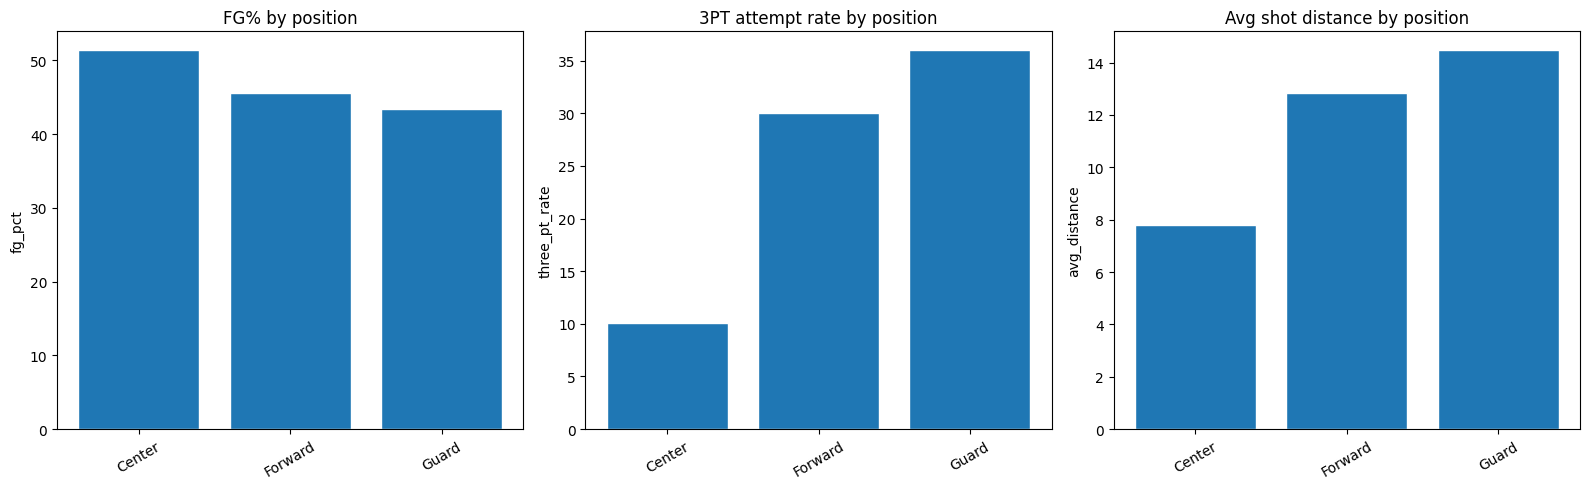

In [ ]:
pos_shooting = merged.groupby('simple_position').agg(
    attempts = ('SHOT_MADE', 'count'),
    fg_pct = ('SHOT_MADE', 'mean'),
    avg_distance = ('SHOT_DISTANCE', 'mean'),
    three_pt_rate = ('SHOT_TYPE', lambda x: (x == '3PT Field Goal').mean())
).reset_index()
pos_shooting = pos_shooting[pos_shooting['simple_position'] != 'Other']
pos_shooting['fg_pct'] = (pos_shooting['fg_pct'] * 100).round(2)
pos_shooting['three_pt_rate'] = (pos_shooting['three_pt_rate'] * 100).round(2)
pos_shooting['avg_distance'] = pos_shooting['avg_distance'].round(2)

display(pos_shooting)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
positions = pos_shooting['simple_position']

for ax, col, title in zip(axes,
    ['fg_pct', 'three_pt_rate', 'avg_distance'],
    ['FG% by position', '3PT attempt rate by position', 'Avg shot distance by position']):
    bars = ax.bar(positions, pos_shooting[col], edgecolor='white')
    ax.set_title(title, fontsize=12)
    ax.set_ylabel(col)
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

Centers are the most efficient shooters by a significant margin (51.35% FG%), which makes sense given their average shot distance of just 7.79ft. They operate a lot closer to the rim efficiency is highest compared to other positions. Guards are the least efficient (43.42%) but attempt 3s at the
highest rate (35.98%), with an average shooting distance of 14.47ft. Forwards fall in between on all metrics. This positional hierarchy is a direct reflection of where each position operates on the floor rather than any difference in shooting skill.

### 4.3 Zone Trends by Season and Position

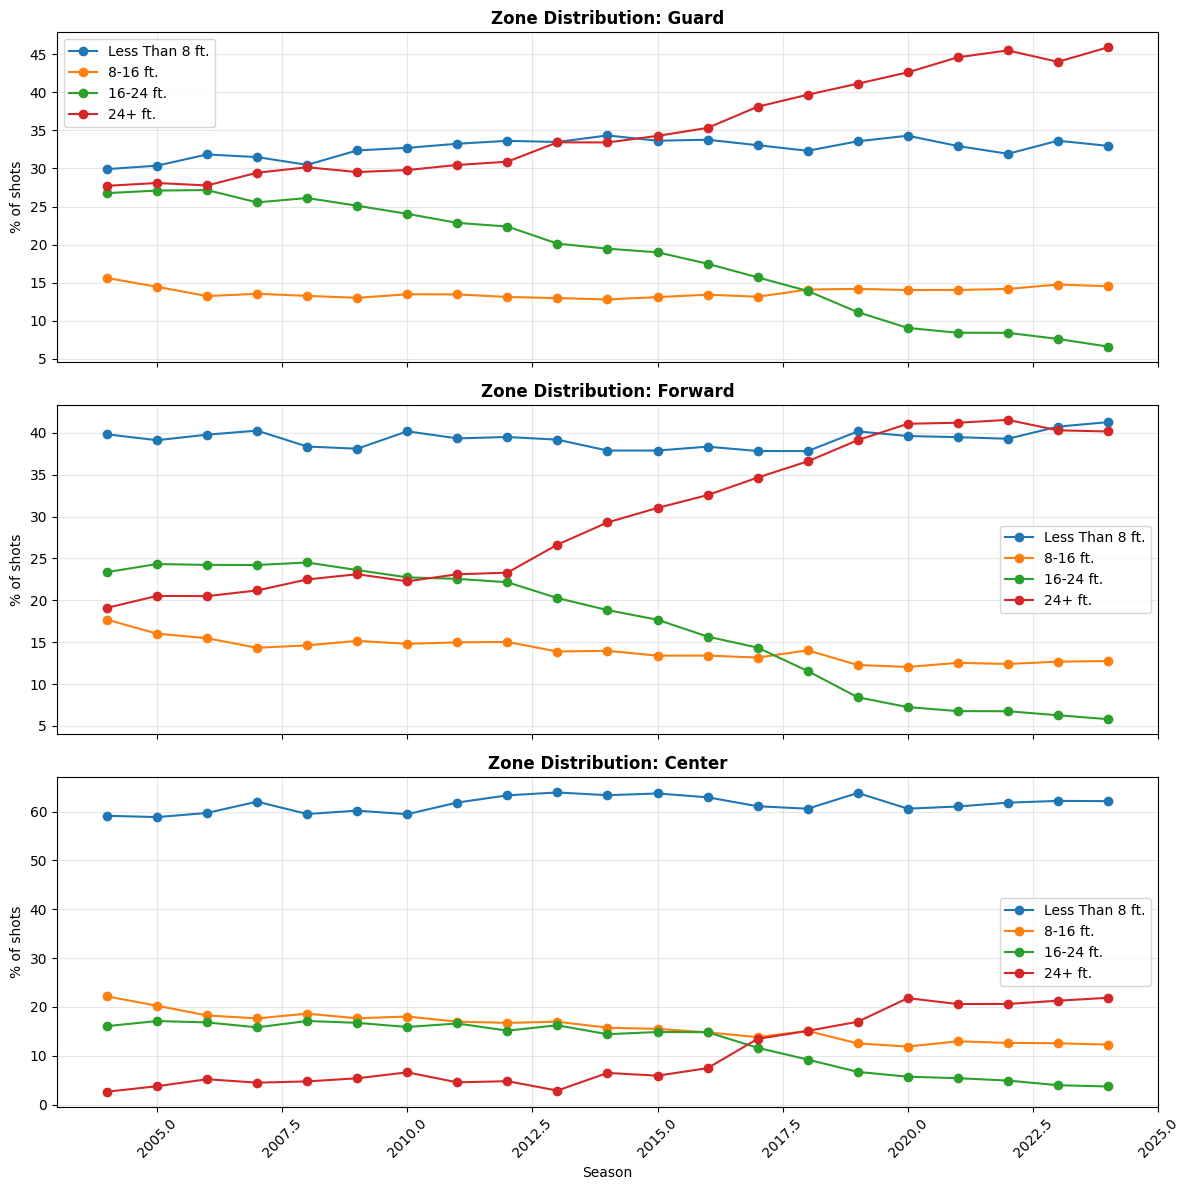

In [ ]:
position_labels =["Guard", "Forward", "Center"]

fig, axes = plt.subplots(len(position_labels), 1, figsize=(12, 4 * len(position_labels)), sharex=True)

if len(position_labels) == 1:
    axes = [axes]  # make it iterable

for ax, pos in zip(axes, position_labels):
    # Filter for this position
    pos_df = merged[merged['simple_position'] == pos]

    # Count shots per season and zone
    zone_counts = pos_df.groupby(['SEASON_1', 'ZONE_RANGE']).size().unstack(fill_value=0)

    # Convert to percentages
    zone_pct = zone_counts.divide(zone_counts.sum(axis=1), axis=0) * 100
    zone_pct = zone_pct[ordered_zones]  # ensure consistent order

    # Plot each zone
    for zone in ordered_zones:
        ax.plot(zone_pct.index, zone_pct[zone], marker='o', label=zone)

    ax.set_title(f'Zone Distribution: {pos}', fontsize=12, fontweight='bold')
    ax.set_ylabel('% of shots')
    ax.legend()
    ax.grid(alpha=0.3)

plt.xlabel('Season')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The position breakdown reinforces the same evolution that we saw across the entire league in section 1.9, but we can see a more granular breakdown now. The guard shot distribution shift follows the long midrange collapse, while the 3-point share rises very consistently, and rim attempts barely move. Forwards undergo the most dramatic transformation. After 2012, their 24+ ft. attempts spike sharply, while midrange zones fall together and close shots frequency stays steady. Centers remain the anchor of traditional shot profiles, with the Less Than 8 ft. zone dominating the entire timeline. However, we do see a slow but steady uptick in 3s paired with a steady decrease of midrange shots.

Across all three positions, the pattern is consistent with midrange shrinking, rim attempts holding, and 3s surging, with each role expressing the same efficiency logic in its own way.

### 4.4 Player-level Aggregation and Top Shooters

In [ ]:
player_season_stats = merged.groupby(['PLAYER_ID', 'PLAYER_NAME', 'SEASON_1', 'age', 'years_in_league']).agg(
    total_shots = ('SHOT_MADE', 'count'),
    made_shots = ('SHOT_MADE', 'sum'),
    fg_pct = ('SHOT_MADE', 'mean'),
    avg_distance = ('SHOT_DISTANCE', 'mean'),
    three_pt_rate = ('SHOT_TYPE', lambda x: (x == '3PT Field Goal').mean()),
    games_played = ('GAME_ID', 'nunique')
).reset_index()

significant = player_season_stats[player_season_stats['total_shots'] >= 200].copy()
significant['fg_pct'] = (significant['fg_pct'] * 100).round(2)
significant['three_pt_rate'] = (significant['three_pt_rate'] * 100).round(2)

print(f"Player-season combinations with 200+ shots: {len(significant):,}")
print("\nTop 10 by FG%:")
display(significant.nlargest(10, 'fg_pct')[['PLAYER_NAME', 'SEASON_1', 'age', 'years_in_league', 'total_shots', 'fg_pct', 'avg_distance', 'three_pt_rate']])

Player-season combinations with 200+ shots: 6,450

Top 10 by FG%:


,PLAYER_NAME,SEASON_1,age,years_in_league,total_shots,fg_pct,avg_distance,three_pt_rate
5191,DeAndre Jordan,2021,32,14,249,76.31,1.305221,0.40
2144,Mitchell Robinson,2022,23,5,343,76.09,0.752187,0.00
3432,Dereck Lively II,2024,19,2,296,74.66,1.986486,0.68
2142,Mitchell Robinson,2020,21,3,341,74.19,0.862170,0.00
2258,Robert Williams III,2022,24,5,368,73.64,2.029891,0.27
7741,Dwight Powell,2023,31,10,269,73.23,2.044610,1.86
2561,Daniel Gafford,2023,24,5,395,73.16,2.822785,0.00
9430,Dwight Howard,2020,34,17,277,72.92,2.032491,1.81
2257,Robert Williams III,2021,23,4,256,72.66,3.128906,0.00
2562,Daniel Gafford,2024,25,6,480,72.50,2.370833,0.00


The most efficient single seasons are dominated by big men who operate almost exclusively at the rim, with some names appearing over multiple seasons. Their average shot distances range from just 0.75ft to 2.8ft, and most have a near-zero 3PT rate, meaning virtually every shot they take is a dunk or layup. FG% values above 72% in these cases are less a testament to shooting skill and more a reflection of extreme shot selection since these players simply never take inefficient shots. This is worth keeping in mind when interpreting FG% as a standalone metric, as it is heavily influenced by where a player operates on the floor.

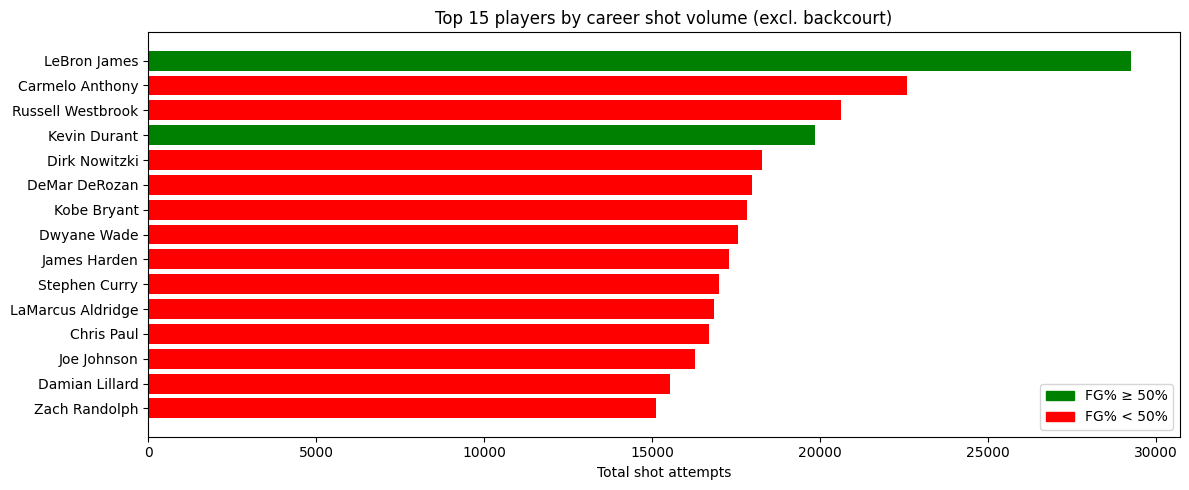

In [ ]:
career_shots = merged.groupby(['PLAYER_ID', 'PLAYER_NAME']).agg(
    total_shots=('SHOT_MADE', 'count'),
    career_fg_pct=('SHOT_MADE', 'mean')
).reset_index().sort_values('total_shots', ascending=False).head(15)

colors = ['green' if fg >= 0.50 else 'red' for fg in career_shots['career_fg_pct'][::-1]]

plt.figure(figsize=(12, 5))
plt.barh(career_shots['PLAYER_NAME'][::-1], career_shots['total_shots'][::-1], color=colors)
plt.title('Top 15 players by career shot volume (excl. backcourt)')
plt.xlabel('Total shot attempts')
green_patch = mpatches.Patch(color='green', label='FG% ≥ 50%')
red_patch = mpatches.Patch(color='red', label='FG% < 50%')
plt.legend(handles=[green_patch, red_patch], loc='lower right')
plt.tight_layout()
plt.show()

LeBron James leads by a wide margin with nearly 30,000 career shot attempts, followed by Carmelo Anthony and Russell Westbrook. The is basically a list of  high-usage stars from the 2004-2024 era like Kobe Bryant, Kevin Durant, and James Harden alongside high-volume guards like Chris Paul and Damian Lillard. Additionally, we can see that LeBron and Kevin Durant are the only two players on this list that have >50% shooting percentage, so they blend volume and efficiency very well.



### 4.5 Shooting Zone Distribution by Player and Season

We need to define what a characteristic zone actually is before we can ask whether players shoot better from their characteristic zones. We want to understand each player's shot distribution across zones in a
given season to get a better understanding of their shooting tendencies. We compute zone shares as the fraction of each player's attempts that come from each zone, and we do so at the  at the player-season level. This gives us the data we need for the era-adjustment in 4.6 and ultimately the specialization
features that feed into our model.

In [ ]:
ZONES = ['Less Than 8 ft.', '8-16 ft.', '16-24 ft.', '24+ ft.']
shots = merged[merged['ZONE_RANGE'].isin(ZONES)].copy()

zone_stats = (
    merged.groupby(['PLAYER_ID', 'PLAYER_NAME', 'SEASON_1', 'age', 'years_in_league', 'simple_position', 'ZONE_RANGE'])
    .agg(attempts=('SHOT_MADE', 'count'), makes=('SHOT_MADE', 'sum'))
    .reset_index()
)
zone_stats['fg_pct'] = zone_stats['makes'] / zone_stats['attempts']
zone_stats['PLAYER_ID'] = zone_stats['PLAYER_ID'].astype(str)

# Total attempts per player, season across all zones
total_attempts = (
    zone_stats.groupby(['PLAYER_ID', 'SEASON_1', 'age', 'years_in_league', 'simple_position'])['attempts']
    .sum().reset_index()
    .rename(columns={'attempts': 'total_attempts'})
)

# Calculating zone distribution per player, season
zone_stats = zone_stats.merge(total_attempts, on=['PLAYER_ID', 'SEASON_1', 'age', 'years_in_league', 'simple_position'])
zone_stats['zone_share'] = zone_stats['attempts'] / zone_stats['total_attempts']

print(f"Count of total shots in dataset before aggregating: {len(shots)}")
zone_stats.head(20)


Count of total shots in dataset before aggregating: 4220904


,PLAYER_ID,PLAYER_NAME,SEASON_1,age,years_in_league,simple_position,ZONE_RANGE,attempts,makes,fg_pct,total_attempts,zone_share
0,1000,Shandon Anderson,2004,30,9,Forward,16-24 ft.,89,32,0.359551,563,0.158082
1,1000,Shandon Anderson,2004,30,9,Forward,24+ ft.,127,36,0.283465,563,0.225577
2,1000,Shandon Anderson,2004,30,9,Forward,8-16 ft.,97,34,0.350515,563,0.172291
3,1000,Shandon Anderson,2004,30,9,Forward,Less Than 8 ft.,250,136,0.544000,563,0.444050
4,1000,Shandon Anderson,2005,31,10,Forward,16-24 ft.,44,21,0.477273,217,0.202765
5,1000,Shandon Anderson,2005,31,10,Forward,24+ ft.,29,5,0.172414,217,0.133641
6,1000,Shandon Anderson,2005,31,10,Forward,8-16 ft.,35,12,0.342857,217,0.161290
7,1000,Shandon Anderson,2005,31,10,Forward,Less Than 8 ft.,109,60,0.550459,217,0.502304
8,1000,Shandon Anderson,2006,32,11,Forward,16-24 ft.,48,22,0.458333,126,0.380952
9,1000,Shandon Anderson,2006,32,11,Forward,24+ ft.,19,5,0.263158,126,0.150794


In [ ]:
# Turn zone_stats dataframe into wide
def pivot_metric(df, value_col, suffix):
    pivot_df = df.pivot_table(
        index=['PLAYER_ID', 'PLAYER_NAME', 'age', 'years_in_league', 'SEASON_1'],
        columns='ZONE_RANGE',
        values=value_col
    ).reset_index()

    pivot_df.columns = [
        f"{c}_{suffix}" if c in ZONES else c
        for c in pivot_df.columns
    ]
    return pivot_df

shares_pivot = pivot_metric(zone_stats, 'zone_share', 'share')
attempts_pivot = pivot_metric(zone_stats, 'attempts', 'attempts')
fgpct_pivot = pivot_metric(zone_stats, 'fg_pct', 'fg_pct')

player_seasons = (
    shares_pivot
    .merge(attempts_pivot, on=['PLAYER_ID', 'PLAYER_NAME', 'age', 'years_in_league', 'SEASON_1'])
    .merge(fgpct_pivot, on=['PLAYER_ID', 'PLAYER_NAME', 'age', 'years_in_league', 'SEASON_1'])
    .merge(total_attempts, on=['PLAYER_ID', 'age', 'years_in_league', 'SEASON_1'])
)

# Fill missing zone shares with 0
player_seasons[['Less Than 8 ft._share', '8-16 ft._share', '16-24 ft._share', '24+ ft._share']] = player_seasons[['Less Than 8 ft._share', '8-16 ft._share', '16-24 ft._share', '24+ ft._share']].fillna(0)
player_seasons['PLAYER_ID'] = player_seasons['PLAYER_ID'].astype(str)

print(f"Count of players and seasons: {len(player_seasons)}")
player_seasons.head()

Count of players and seasons: 10306


,PLAYER_ID,PLAYER_NAME,age,years_in_league,SEASON_1,16-24 ft._share,24+ ft._share,8-16 ft._share,Less Than 8 ft._share,16-24 ft._attempts,24+ ft._attempts,8-16 ft._attempts,Less Than 8 ft._attempts,16-24 ft._fg_pct,24+ ft._fg_pct,8-16 ft._fg_pct,Less Than 8 ft._fg_pct,simple_position,total_attempts
0,1000,Shandon Anderson,30,9,2004,0.158082,0.225577,0.172291,0.444050,89.0,127.0,97.0,250.0,0.359551,0.283465,0.350515,0.544000,Forward,563
1,1000,Shandon Anderson,31,10,2005,0.202765,0.133641,0.161290,0.502304,44.0,29.0,35.0,109.0,0.477273,0.172414,0.342857,0.550459,Forward,217
2,1000,Shandon Anderson,32,11,2006,0.380952,0.150794,0.158730,0.309524,48.0,19.0,20.0,39.0,0.458333,0.263158,0.250000,0.564103,Forward,126
3,101106,Andrew Bogut,21,2,2006,0.059406,0.004950,0.097360,0.838284,36.0,3.0,59.0,508.0,0.277778,0.000000,0.440678,0.564961,Center,606
4,101106,Andrew Bogut,22,3,2007,0.070064,0.006369,0.132166,0.791401,44.0,4.0,83.0,497.0,0.250000,0.250000,0.361446,0.615694,Center,628


### 4.6 Adjust Shot Distribution Data to Account for Era

Raw zone shares can be misleading as a metric on its own because the league has changed dramatically over the 20 seasons in our dataset. A player taking 30% of their shots from 24+ ft. in 2004 was an outlier, but the same share in 2022 is below league average. Comparing raw zone shares across seasons would conflate a player's individual tendencies with the era they played in.

To fix this issue, we normalize each player's zone shares against the league average for that season. The resulting `share_vs_avg` metric captures how much a player shoots more or less in each zone relative to the other players in the league, making profiles comparable across eras. A player at +0.10 in the 24+ ft. zone in 2005 and a player at +0.10 in 2020 are both equally specialized relative to the league norms of their time. We verify the normalization is correct by confirming that the weighted mean of each zone's share_vs_avg across all player-seasons is zero.

In [ ]:
def compute_league_avg(zone_stats_filtered: pd.DataFrame) -> pd.DataFrame:
    league_zone = (
        zone_stats_filtered
        .groupby(['SEASON_1', 'ZONE_RANGE'])['attempts'].sum()
        .reset_index().rename(columns={'attempts': 'zone_attempts'})
    )
    season_totals = (
        league_zone.groupby('SEASON_1')['zone_attempts'].sum()
        .reset_index().rename(columns={'zone_attempts': 'season_total'})
    )

    league_zone = league_zone.merge(season_totals, on='SEASON_1')
    league_zone['league_zone_share'] = (
        league_zone['zone_attempts'] / league_zone['season_total']
    )

    wide = league_zone.pivot_table(
        index='SEASON_1', columns='ZONE_RANGE', values='league_zone_share'
    ).reset_index()

    wide.columns = [
        f"{c}_league_avg" if c in ZONES else c
        for c in wide.columns
    ]
    return wide

zone_stats_filtered = zone_stats.merge(
    player_seasons, on=['PLAYER_ID', 'SEASON_1'], how='inner'
)
print(f"zone_stats: {len(zone_stats):,} | zone_stats_filtered: {len(zone_stats_filtered):,}")

league_avg_wide = compute_league_avg(zone_stats_filtered)

player_seasons_full = player_seasons.merge(league_avg_wide, on='SEASON_1', how='left')
for zone in ZONES:
    player_seasons_full[f"{zone}_share_vs_avg"] = player_seasons_full[f"{zone}_share"] - player_seasons_full[f"{zone}_league_avg"]


print("Checking that each zone averages out to 0")
for zone in ZONES:
    weighted_mean = np.average(
        player_seasons_full[f"{zone}_share_vs_avg"],
        weights=player_seasons_full['total_attempts']
    )
    print(f"{zone}: {weighted_mean}")

player_seasons_full.head()

zone_stats: 38,491 | zone_stats_filtered: 38,491
Checking that each zone averages out to 0
Less Than 8 ft.: -2.8011608705263296e-18
8-16 ft.: -1.0773695655870499e-18
16-24 ft.: 1.7237913049392799e-18
24+ ft.: 8.618956524696399e-19


,PLAYER_ID,PLAYER_NAME,age,years_in_league,SEASON_1,16-24 ft._share,24+ ft._share,8-16 ft._share,Less Than 8 ft._share,16-24 ft._attempts,24+ ft._attempts,8-16 ft._attempts,Less Than 8 ft._attempts,16-24 ft._fg_pct,24+ ft._fg_pct,8-16 ft._fg_pct,Less Than 8 ft._fg_pct,simple_position,total_attempts,16-24 ft._league_avg,24+ ft._league_avg,8-16 ft._league_avg,Less Than 8 ft._league_avg,Less Than 8 ft._share_vs_avg,8-16 ft._share_vs_avg,16-24 ft._share_vs_avg,24+ ft._share_vs_avg
0,1000,Shandon Anderson,30,9,2004,0.158082,0.225577,0.172291,0.444050,89.0,127.0,97.0,250.0,0.359551,0.283465,0.350515,0.544000,Forward,563,0.229423,0.184877,0.179501,0.406199,0.037851,-0.007210,-0.071341,0.040700
1,1000,Shandon Anderson,31,10,2005,0.202765,0.133641,0.161290,0.502304,44.0,29.0,35.0,109.0,0.477273,0.172414,0.342857,0.550459,Forward,217,0.236665,0.193728,0.164501,0.405107,0.097197,-0.003210,-0.033900,-0.060087
2,1000,Shandon Anderson,32,11,2006,0.380952,0.150794,0.158730,0.309524,48.0,19.0,20.0,39.0,0.458333,0.263158,0.250000,0.564103,Forward,126,0.237096,0.200085,0.152074,0.410745,-0.101222,0.006656,0.143857,-0.049291
3,101106,Andrew Bogut,21,2,2006,0.059406,0.004950,0.097360,0.838284,36.0,3.0,59.0,508.0,0.277778,0.000000,0.440678,0.564961,Center,606,0.237096,0.200085,0.152074,0.410745,0.427538,-0.054714,-0.177690,-0.195134
4,101106,Andrew Bogut,22,3,2007,0.070064,0.006369,0.132166,0.791401,44.0,4.0,83.0,497.0,0.250000,0.250000,0.361446,0.615694,Center,628,0.230182,0.210190,0.146908,0.412720,0.378682,-0.014743,-0.160119,-0.203820


We normalize each player's shot distribution against league averages to eliminate the noise of league-wide shot trends such as the increase of 3-pointers or decrease of midranges over the time period. As the league has changed, raw zone shares become less informative on their own. By benchmarking against season-level baselines, we can clearly identify who is truly deviating from the norm, which players are ahead of the trend, lagging behind it, or have unique shot profiles. This makes the data far more meaningful for understanding play style, role, and how a player fits within the broader evolution of the game.

Additionally, the row counts are identical before and after the merge, confirming no shots were silently dropped due to ID mismatches. The weighted zone averages are all effectively zero (values on the order of 1e-18 are floating point rounding error, not real deviation), confirming the era-adjustment is correctly normalized. The share_vs_avg features are ready to use.

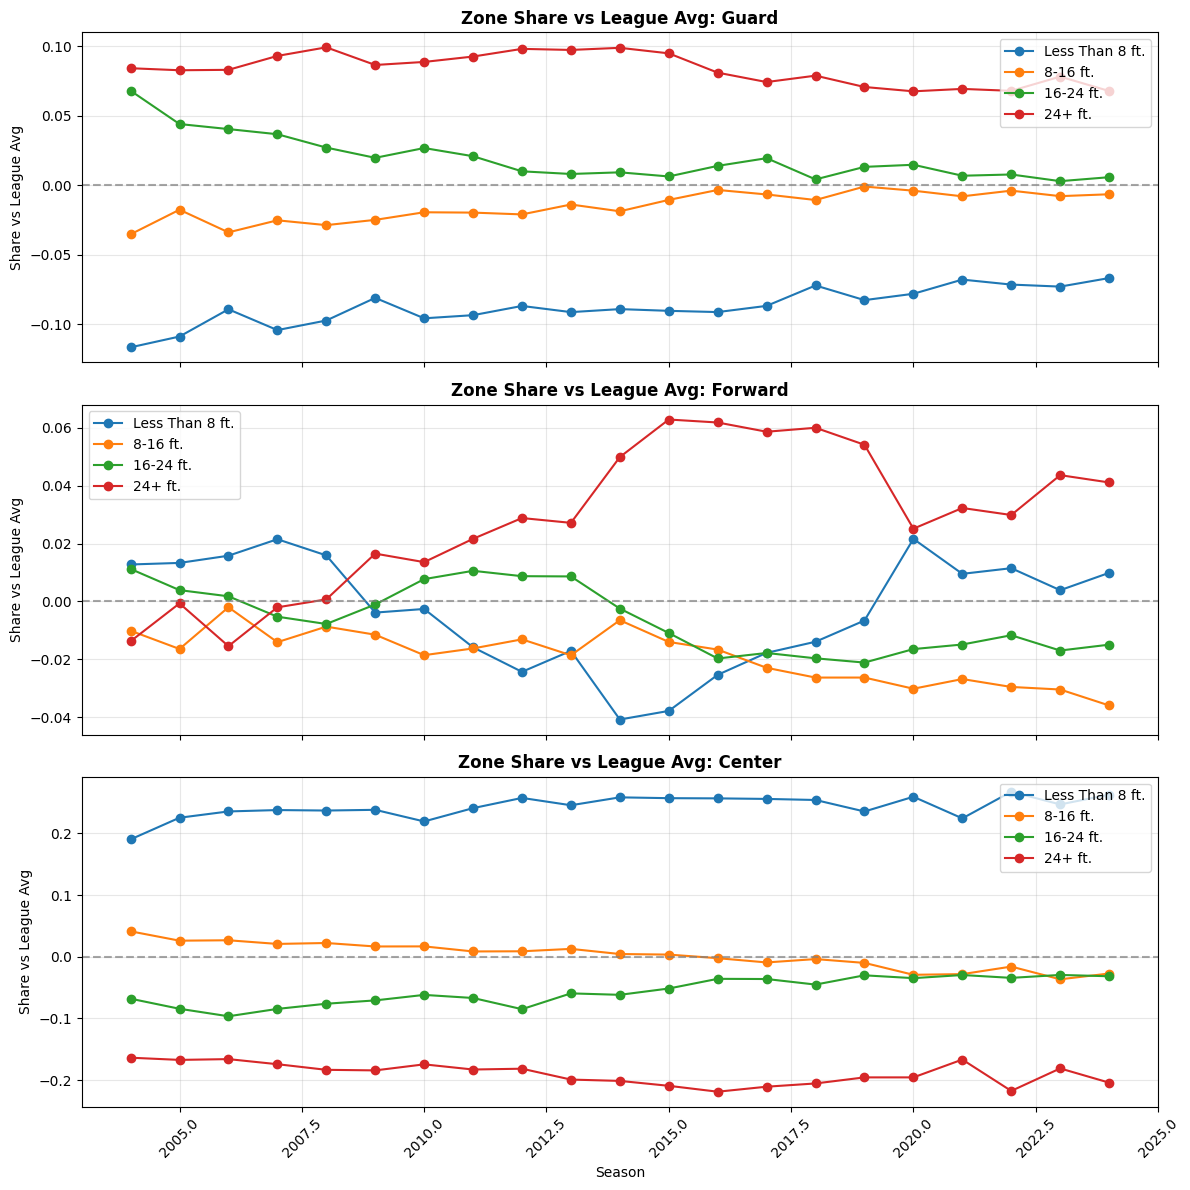

In [ ]:
share_vs_avg_cols = [f"{zone}_share_vs_avg" for zone in ['Less Than 8 ft.', '8-16 ft.', '16-24 ft.', '24+ ft.']]
fig, axes = plt.subplots(len(position_labels), 1, figsize=(12, 4 * len(position_labels)), sharex=True)

if len(position_labels) == 1:
    axes = [axes]

for ax, pos in zip(axes, position_labels):
    # Filter for this position
    pos_df = player_seasons_full[player_seasons_full['simple_position'] == pos]
    zone_means = pos_df.groupby('SEASON_1')[share_vs_avg_cols].mean()

    # Plot each zone
    for zone in ordered_zones:
        ax.plot(zone_means.index, zone_means[f"{zone}_share_vs_avg"], marker='o', label=zone)

    ax.set_title(f'Zone Share vs League Avg: {pos}', fontsize=12, fontweight='bold')
    ax.set_ylabel('Share vs League Avg')
    ax.axhline(0, color='gray', linestyle='--', alpha=0.7)
    ax.legend()
    ax.grid(alpha=0.3)

plt.xlabel('Season')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

We can now see the zone distribution relative to the league for each position which makes the roles even clearer. Guards sit well above the league in 24+ ft. attempts and well below it at the rim, while their midrange deficit mirrors the league-wide decline of that zone. The key here is that they shoot more shares of 3s compared to league average year after year. Forwards show the biggest identity shift. Early on, they track close to league norms, but starting around 2013-14, the 24+ ft. line shoots upward while their at-rim share dips below average. They essentially trade interior touches for long-range shots and spacing. Centers remain the outlier in the opposite direction, as they are above league average at the rim and massively below it from deep. This makes sense with their traditional role. However, the midrange deficit grows over time as their midrange disappear. The tiny but steady rise in 3-point attempts is the only hint of modernization, but the core identity stays anchored inside.


### 4.7 Histogram of Age

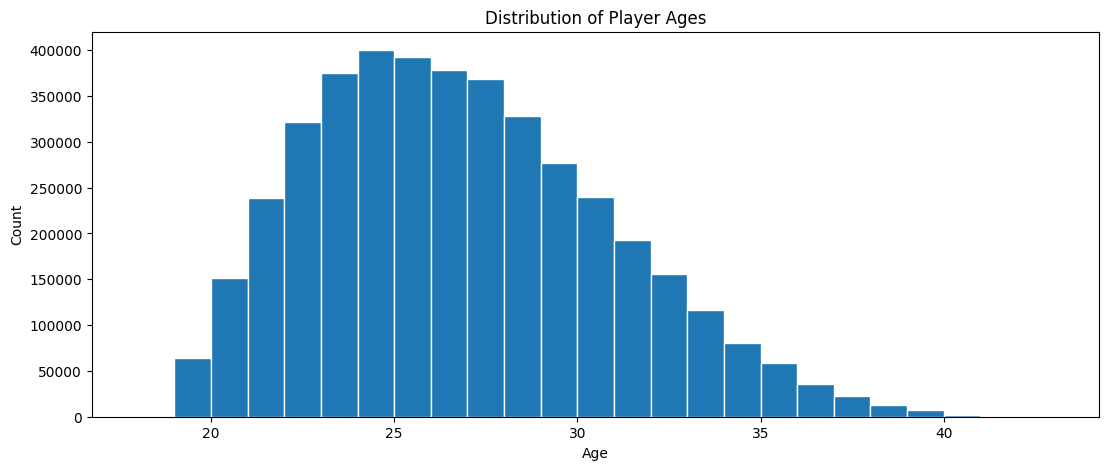

In [ ]:
plt.figure(figsize=(13,5))
plt.hist(merged['age'], bins=range(min(merged['age']), max(merged['age']), 1), edgecolor='white')
plt.xlabel("Age")
plt.ylabel("Count")
plt.title("Distribution of Player Ages")
plt.show()

The age distribution is right skewed with most of the shots coming from players between 22 and 32 years old, peaking around 25-27. This reflects the typical NBA career arc, as players enter the league in their late teens or early twenties, reach their prime usage years in their mid-to-late twenties, and slowly decline in their thirties as minutes and role decrease. The long right tail extending into the late 30s represents the small number of players who sustain long careers, and the very low counts at the extremes (under 20 and over 38) reflect how rare it is to appear and shoot shots in the league at those ages.

This distribution matters for the modeling context. The bulk of our data comes
from players in their prime years, so the era-adjusted zone profiles and
specialization features will be most reliable in that age range. The wider
standard deviation bands we noted in section 4.8 at ages 38+ are a direct
consequence of the thin sample here since there simply aren't enough shots from
players that age to produce stable estimates.

### 4.8 Era-Adjusted Zone Share by Age

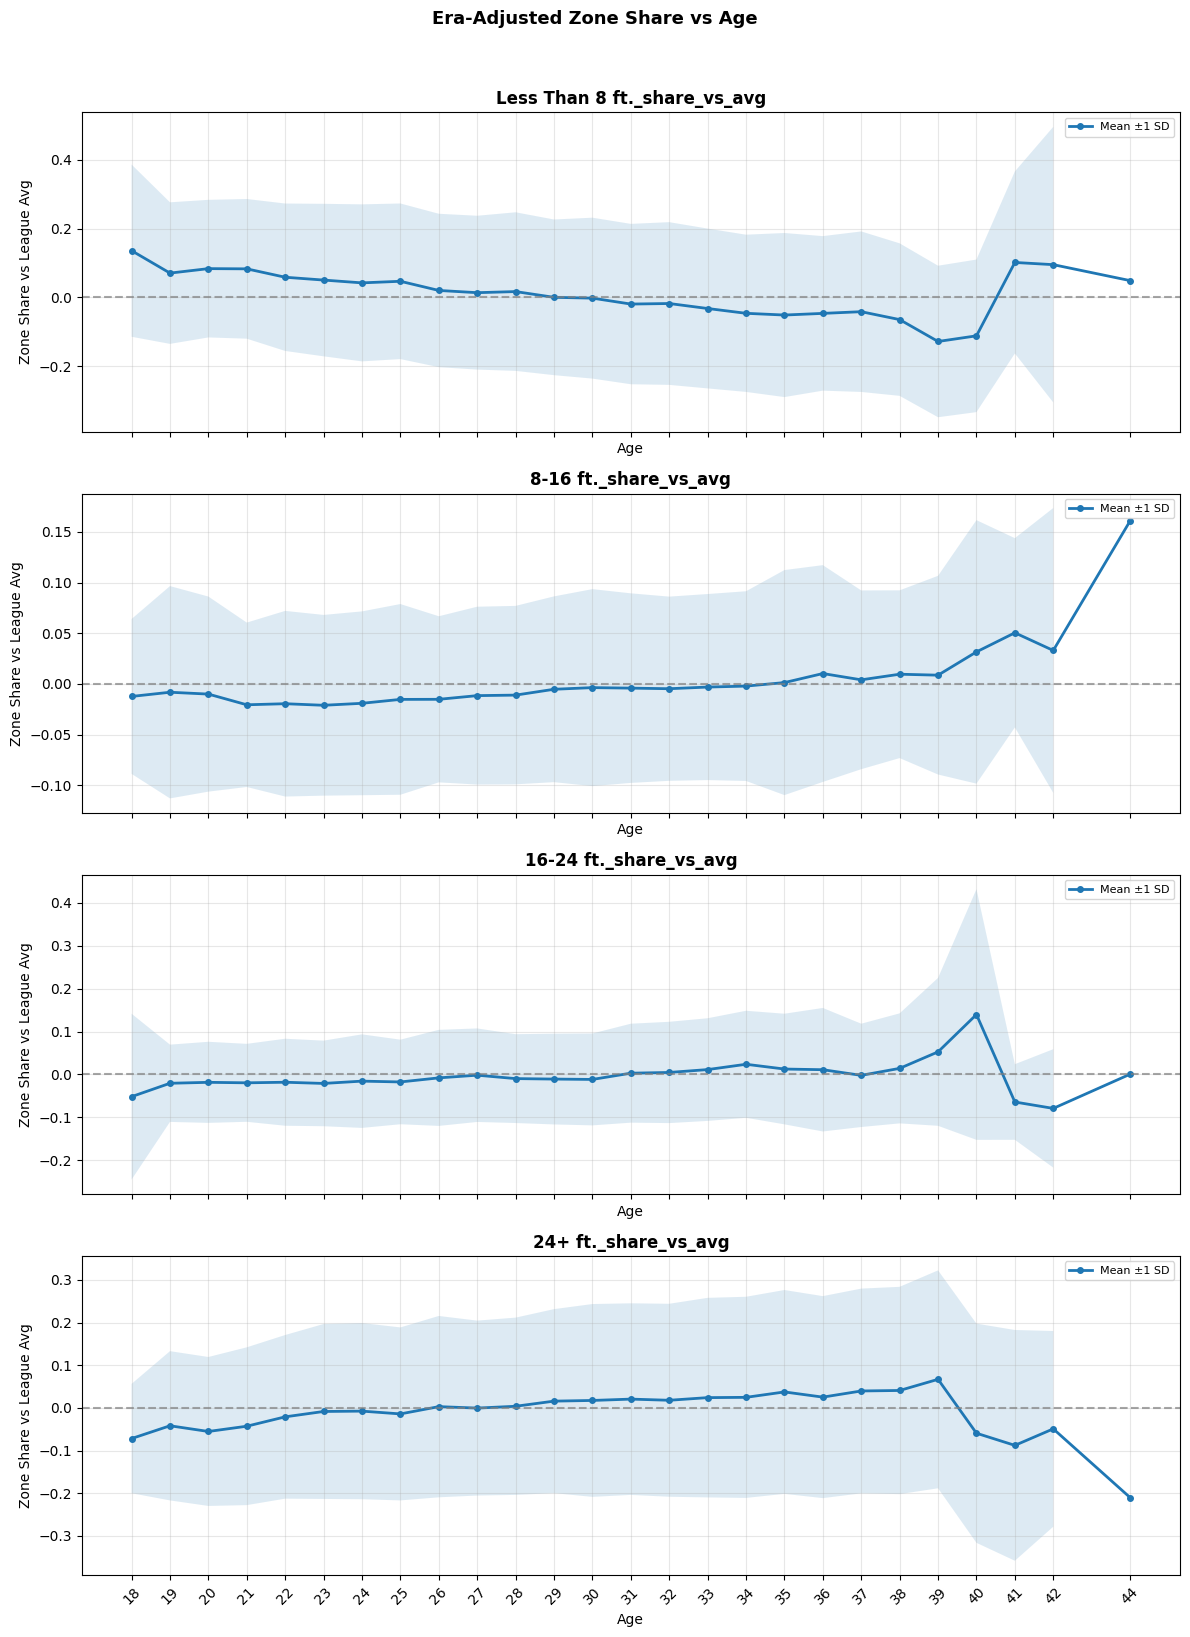

In [ ]:
fig, axes = plt.subplots(len(share_vs_avg_cols), 1, figsize=(12, 4 * len(share_vs_avg_cols)), sharex=True)

for ax, zone in zip(axes, share_vs_avg_cols):
    col = zone
    mean_age = player_seasons_full.groupby('age')[col].mean()
    std_age  = player_seasons_full.groupby('age')[col].std()

    ax.fill_between(mean_age.index,
                    mean_age - std_age,
                    mean_age + std_age,
                    alpha=0.15)

    ax.plot(mean_age.index,
            mean_age,
            linewidth=2,
            marker='o',
            markersize=4,
            label='Mean ±1 SD')

    ax.axhline(0, color='gray', linestyle='--', alpha=0.7)
    ax.set_title(zone, fontsize=12, fontweight='bold')
    ax.set_xlabel("Age")
    ax.set_ylabel("Zone Share vs League Avg")
    ax.set_xticks(mean_age.index)
    ax.tick_params(axis='x', rotation=45)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)


plt.suptitle("Era-Adjusted Zone Share vs Age",
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Players generally start their careers above league average at the rim, but that trend erodes with age, reflecting a decline of burst and lift. By the late 20s and early 30s, most players are finishing less at the rim compared to league average. The 8-16 ft. zone stays almost perfectly neutral until the very end of the career arc, and the 16-24 ft. line sits slightly below average for most of the aging curve. 24+ zone share has a steady increase as players age, which is the opposite direction from the rim shares. As players get older, they take more 3s to limit the physical toll on their body.

There are some spikes and larger standard deviation ranges starting around 38 years old. This is due to a lot smaller of sample size, so outliers carry more influence here.

### 4.9 Zone Share Distribution by Age and Position

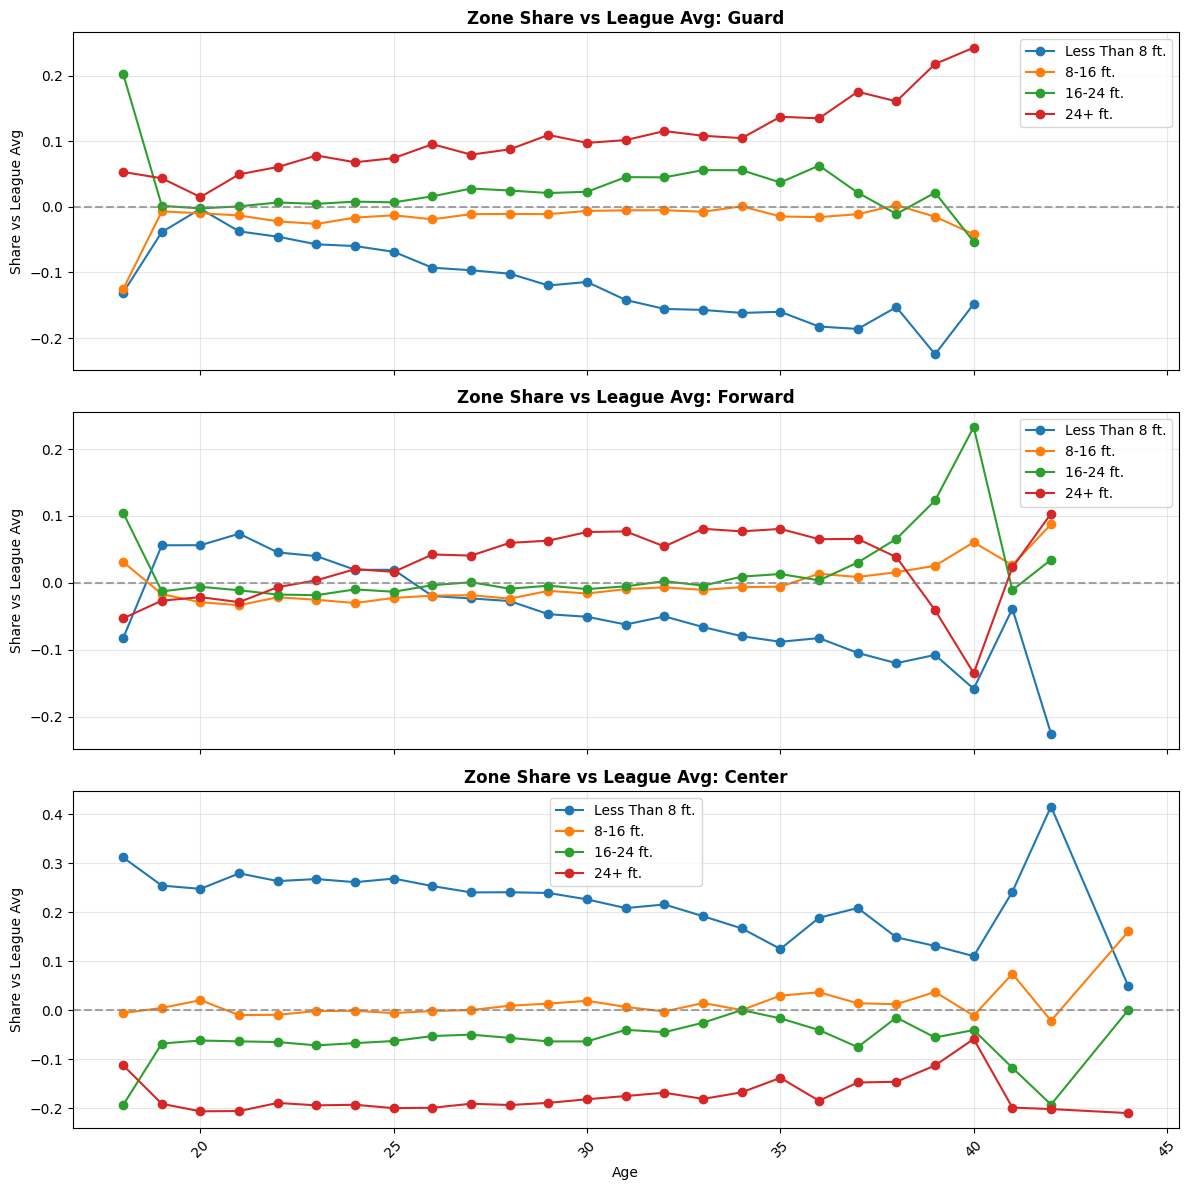

In [ ]:
share_vs_avg_cols = [f"{zone}_share_vs_avg" for zone in ['Less Than 8 ft.', '8-16 ft.', '16-24 ft.', '24+ ft.']]
fig, axes = plt.subplots(len(position_labels), 1, figsize=(12, 4 * len(position_labels)), sharex=True)

if len(position_labels) == 1:
    axes = [axes]

for ax, pos in zip(axes, position_labels):
    # Filter for this position
    pos_df = player_seasons_full[player_seasons_full['simple_position'] == pos]
    zone_means = pos_df.groupby('age')[share_vs_avg_cols].mean()

    # Plot each zone
    for zone in ordered_zones:
        ax.plot(zone_means.index, zone_means[f"{zone}_share_vs_avg"], marker='o', label=zone)

    ax.set_title(f'Zone Share vs League Avg: {pos}', fontsize=12, fontweight='bold')
    ax.set_ylabel('Share vs League Avg')
    ax.axhline(0, color='gray', linestyle='--', alpha=0.7)
    ax.legend()
    ax.grid(alpha=0.3)

plt.xlabel('Age')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The age curves make the positional identities even clearer. Guards age into their perimeter-first profile, as their 24+ ft. share rises above league average as they get older, while their rim frequency steadily falls below it. Forwards stay closest to league norms across the aging curve, but the pattern still tilts toward modern spacing. Their long-range share gradually climbs above average with age, while their at-rim share drifts slightly below it.Centers remain the inverse case. They are well above league average at the rim at every age and well below it from deep. The midrange deficit widens as they get older. Overall, the aging curve follows the general intuition that as players age, they take less rim shots and more distance shots regardless of position.

### 4.10 Relationships Between Shots & Draft Position

A position a player was drafted can have significant relationships with their play and ,more importantly, their opportunities. In the NBA, we can see countless examples of players getting more opportunities because of the investment the team has made in them (i.e if you are drafted higher, the team has made a more significant investment into you via salary and the loss of taking someone else).

In this section, we analyze the relationships between shots & draft position. We ask a variety of questions as shown below.

#### Creating the view

In [ ]:
# A quick view of the data prior to joining
player_info.head()

,person_id,name,birthdate,position,height,weight,school,country,draft_year,draft_round,draft_number,from_year,to_year,team_name,birth_year,height_inches,simple_position
0,1000,Shandon Anderson,1973-12-31T00:00:00,Guard-Forward,6-6,215.0,Georgia,USA,1996,2,54,1996,2005,Knicks,1973,78.0,Forward
1,101106,Andrew Bogut,1984-11-28T00:00:00,Center,7-0,260.0,Utah,Australia,2005,1,1,2005,2018,Bucks,1984,84.0,Center
2,101107,Marvin Williams,1986-06-19T00:00:00,Forward,6-8,237.0,North Carolina,USA,2005,1,2,2005,2019,Hawks,1986,80.0,Forward
3,101108,Chris Paul,1985-05-06T00:00:00,Guard,6-0,175.0,Wake Forest,USA,2005,1,4,2005,2025,NaN,1985,72.0,Guard
4,101109,Raymond Felton,1984-06-26T00:00:00,Guard,6-1,205.0,North Carolina,USA,2005,1,5,2005,2018,Bobcats,1984,73.0,Guard


In [ ]:
all_shots.head()

,SEASON_1,SEASON_2,TEAM_ID,TEAM_NAME,PLAYER_ID,PLAYER_NAME,POSITION_GROUP,POSITION,GAME_DATE,GAME_ID,HOME_TEAM,AWAY_TEAM,EVENT_TYPE,SHOT_MADE,ACTION_TYPE,SHOT_TYPE,BASIC_ZONE,ZONE_NAME,ZONE_ABB,ZONE_RANGE,LOC_X,LOC_Y,SHOT_DISTANCE,QUARTER,MINS_LEFT,SECS_LEFT,IS_CLUTCH
0,2004,2003-04,1610612747,Los Angeles Lakers,977,Kobe Bryant,G,SG,04-14-2004,20301187,POR,LAL,Made Shot,True,Jump Shot,3PT Field Goal,Above the Break 3,Left Side Center,LC,24+ ft.,20.0,21.35,25,6,0,0,1
1,2004,2003-04,1610612757,Portland Trail Blazers,757,Damon Stoudamire,G,PG,04-14-2004,20301187,POR,LAL,Made Shot,True,Driving Layup Shot,2PT Field Goal,Restricted Area,Center,C,Less Than 8 ft.,-0.0,5.25,0,6,0,2,1
2,2004,2003-04,1610612747,Los Angeles Lakers,977,Kobe Bryant,G,SG,04-14-2004,20301187,POR,LAL,Missed Shot,False,Jump Shot,2PT Field Goal,Mid-Range,Left Side Center,LC,16-24 ft.,13.3,24.45,23,6,0,9,1
3,2004,2003-04,1610612757,Portland Trail Blazers,757,Damon Stoudamire,G,PG,04-14-2004,20301187,POR,LAL,Made Shot,True,Jump Shot,2PT Field Goal,Mid-Range,Left Side,L,16-24 ft.,16.4,13.95,18,6,0,31,1
4,2004,2003-04,1610612757,Portland Trail Blazers,757,Damon Stoudamire,G,PG,04-14-2004,20301187,POR,LAL,Missed Shot,False,Jump Shot,2PT Field Goal,Mid-Range,Right Side,R,16-24 ft.,-15.8,7.85,16,6,0,55,1


In [ ]:
# Creating the view
player_info_cols_required = ['person_id', 'draft_round', 'draft_number', 'from_year', 'to_year']
player_info['person_id'] = player_info['person_id'].astype(int)
draft_and_shots_table =  all_shots.merge(player_info[player_info_cols_required], how='left', left_on='PLAYER_ID', right_on='person_id')
draft_and_shots_table.head()

,SEASON_1,SEASON_2,TEAM_ID,TEAM_NAME,PLAYER_ID,PLAYER_NAME,POSITION_GROUP,POSITION,GAME_DATE,GAME_ID,HOME_TEAM,AWAY_TEAM,EVENT_TYPE,SHOT_MADE,ACTION_TYPE,SHOT_TYPE,BASIC_ZONE,ZONE_NAME,ZONE_ABB,ZONE_RANGE,LOC_X,LOC_Y,SHOT_DISTANCE,QUARTER,MINS_LEFT,SECS_LEFT,IS_CLUTCH,person_id,draft_round,draft_number,from_year,to_year
0,2004,2003-04,1610612747,Los Angeles Lakers,977,Kobe Bryant,G,SG,04-14-2004,20301187,POR,LAL,Made Shot,True,Jump Shot,3PT Field Goal,Above the Break 3,Left Side Center,LC,24+ ft.,20.0,21.35,25,6,0,0,1,977,1,13,1996,2015
1,2004,2003-04,1610612757,Portland Trail Blazers,757,Damon Stoudamire,G,PG,04-14-2004,20301187,POR,LAL,Made Shot,True,Driving Layup Shot,2PT Field Goal,Restricted Area,Center,C,Less Than 8 ft.,-0.0,5.25,0,6,0,2,1,757,1,7,1995,2007
2,2004,2003-04,1610612747,Los Angeles Lakers,977,Kobe Bryant,G,SG,04-14-2004,20301187,POR,LAL,Missed Shot,False,Jump Shot,2PT Field Goal,Mid-Range,Left Side Center,LC,16-24 ft.,13.3,24.45,23,6,0,9,1,977,1,13,1996,2015
3,2004,2003-04,1610612757,Portland Trail Blazers,757,Damon Stoudamire,G,PG,04-14-2004,20301187,POR,LAL,Made Shot,True,Jump Shot,2PT Field Goal,Mid-Range,Left Side,L,16-24 ft.,16.4,13.95,18,6,0,31,1,757,1,7,1995,2007
4,2004,2003-04,1610612757,Portland Trail Blazers,757,Damon Stoudamire,G,PG,04-14-2004,20301187,POR,LAL,Missed Shot,False,Jump Shot,2PT Field Goal,Mid-Range,Right Side,R,16-24 ft.,-15.8,7.85,16,6,0,55,1,757,1,7,1995,2007


In [ ]:
# Cleaning the view if needed
draft_and_shots_table['draft_round'].value_counts()

,count
draft_round,
1,3077589
2,759110
Undrafted,381844
0,7088
4,126


In [ ]:
# We have some individuals drafted in round 0 & round 4. How is this possible since
# the NBA draft has 2 rounds?
suspicious_rounds = ['0', '4']
non_drafted_rows = draft_and_shots_table[draft_and_shots_table['draft_round'].isin(suspicious_rounds)]
non_drafted_rows[['draft_round', 'draft_number']].value_counts()

draft_round  draft_number
0            0               3048
4            78                95
             82                31
Name: count, dtype: int64

In [ ]:
# Taking a look at how many players are apart of this group and who they are
non_drafted_rows[['PLAYER_ID', 'PLAYER_NAME']].groupby('PLAYER_ID').sum().reset_index()

,PLAYER_ID,PLAYER_NAME
0,2891,Mark JonesMark JonesMark JonesMark JonesMark J...
1,201041,Walker RussellWalker RussellWalker RussellWalk...
2,202951,Jeremy PargoJeremy PargoJeremy PargoJeremy Par...
3,203186,Willie ReedWillie ReedWillie ReedWillie ReedWi...
4,203613,Jonathon SimmonsJonathon SimmonsJonathon Simmo...
5,203687,Reggie HearnReggie Hearn
6,203705,Josh MagetteJosh MagetteJosh MagetteJosh Maget...
7,203710,C.J. WilliamsC.J. WilliamsC.J. WilliamsC.J. Wi...
8,203816,Scotty HopsonScotty HopsonScotty HopsonScotty ...
9,204065,David StocktonDavid StocktonDavid StocktonDavi...


As we can see in the above cell, we have entries where the draft round = 0 or 4. These rounds would correspond to players getting into the NBA from non-traditional methods (i.e methods other than the NBA draft like coming over from the overseas leagues like the EuroLeague). These players were not drafted. Since the number of players who fall in this category is 12, we can just drop their rows since we won't see any realistic impact.

In [ ]:
cleaned_draft_and_shots_table = draft_and_shots_table[draft_and_shots_table['draft_round'].isin(['1','2', 'Undrafted'])]
cleaned_draft_and_shots_table.head()

,SEASON_1,SEASON_2,TEAM_ID,TEAM_NAME,PLAYER_ID,PLAYER_NAME,POSITION_GROUP,POSITION,GAME_DATE,GAME_ID,HOME_TEAM,AWAY_TEAM,EVENT_TYPE,SHOT_MADE,ACTION_TYPE,SHOT_TYPE,BASIC_ZONE,ZONE_NAME,ZONE_ABB,ZONE_RANGE,LOC_X,LOC_Y,SHOT_DISTANCE,QUARTER,MINS_LEFT,SECS_LEFT,IS_CLUTCH,person_id,draft_round,draft_number,from_year,to_year
0,2004,2003-04,1610612747,Los Angeles Lakers,977,Kobe Bryant,G,SG,04-14-2004,20301187,POR,LAL,Made Shot,True,Jump Shot,3PT Field Goal,Above the Break 3,Left Side Center,LC,24+ ft.,20.0,21.35,25,6,0,0,1,977,1,13,1996,2015
1,2004,2003-04,1610612757,Portland Trail Blazers,757,Damon Stoudamire,G,PG,04-14-2004,20301187,POR,LAL,Made Shot,True,Driving Layup Shot,2PT Field Goal,Restricted Area,Center,C,Less Than 8 ft.,-0.0,5.25,0,6,0,2,1,757,1,7,1995,2007
2,2004,2003-04,1610612747,Los Angeles Lakers,977,Kobe Bryant,G,SG,04-14-2004,20301187,POR,LAL,Missed Shot,False,Jump Shot,2PT Field Goal,Mid-Range,Left Side Center,LC,16-24 ft.,13.3,24.45,23,6,0,9,1,977,1,13,1996,2015
3,2004,2003-04,1610612757,Portland Trail Blazers,757,Damon Stoudamire,G,PG,04-14-2004,20301187,POR,LAL,Made Shot,True,Jump Shot,2PT Field Goal,Mid-Range,Left Side,L,16-24 ft.,16.4,13.95,18,6,0,31,1,757,1,7,1995,2007
4,2004,2003-04,1610612757,Portland Trail Blazers,757,Damon Stoudamire,G,PG,04-14-2004,20301187,POR,LAL,Missed Shot,False,Jump Shot,2PT Field Goal,Mid-Range,Right Side,R,16-24 ft.,-15.8,7.85,16,6,0,55,1,757,1,7,1995,2007


In [ ]:
cleaned_draft_and_shots_table[['draft_round']].value_counts()

,count
draft_round,
1,3077589
2,759110
Undrafted,381844


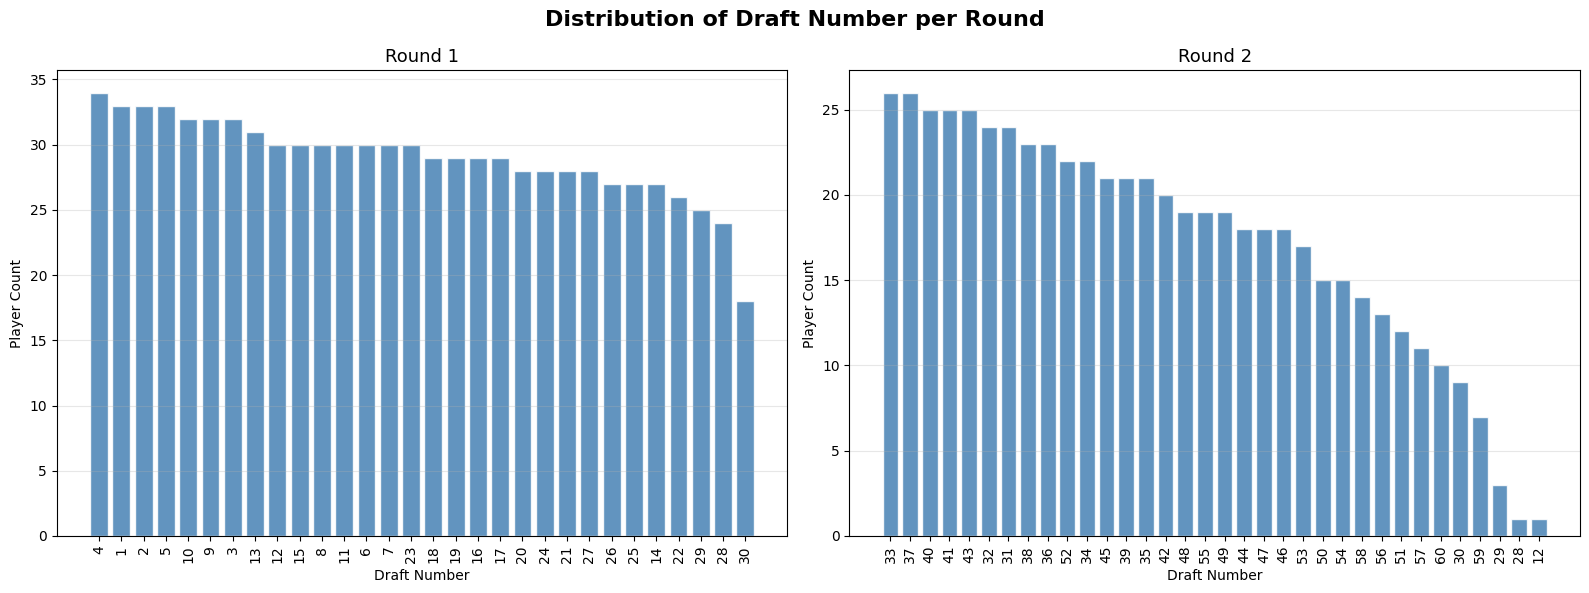

In [ ]:
# Looking at the distribution of draft_number per round
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Distribution of Draft Number per Round', fontsize=16, fontweight='bold')

for ax, (round_num, group) in zip(axes, cleaned_draft_and_shots_table.groupby('draft_round')):
    unique_players = group.drop_duplicates(subset='PLAYER_ID')
    counts = unique_players['draft_number'].value_counts().sort_values(ascending=False)
    ax.bar(counts.index.astype(str), counts.values, color='steelblue', edgecolor='white', alpha=0.85)
    ax.set_title(f'Round {int(round_num)}', fontsize=13)
    ax.set_xlabel('Draft Number')
    ax.set_ylabel('Player Count')
    ax.tick_params(axis='x', rotation=90)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

The distribution of draft numbers looks relatively ok. However, we do see that in round 2, we have draft numbers that come before 30. It's worth investigating to see who players those are.

In [ ]:
cleaned_draft_and_shots_table[
    (cleaned_draft_and_shots_table['draft_round'] == "2") &
    (cleaned_draft_and_shots_table['draft_number'].isin(["12", "28", "29", "30"]))
][['PLAYER_NAME', 'PLAYER_ID', 'draft_round', 'draft_number', 'from_year', 'to_year']].drop_duplicates(subset='PLAYER_ID')

,PLAYER_NAME,PLAYER_ID,draft_round,draft_number,from_year,to_year
107,Ansu Sesay,1738,2,30,2001,2004
408,Lucious Harris,446,2,28,1993,2004
452,Toni Kukoc,389,2,29,1993,2005
474,Gilbert Arenas,2240,2,30,2001,2011
728,Roger Mason Jr.,2427,2,30,2002,2013
828,Trenton Hassell,2239,2,29,2001,2009
1797,Maciej Lampe,2573,2,30,2003,2005
2020,P.J. Brown,136,2,29,1993,2007
8912,Sean Rooks,399,2,30,1992,2003
14396,Othella Harrington,970,2,30,1996,2007


Looking at the odd looking draft numbers in round 2, we can see that most of these players started their career before 2005. In that case, being drafted with the 28,29, or 30th pick makes sense since prior to 2005, there were 29 teams in the NBA. We have one outlier (Jerry Smith who was picked 12 in the 2nd round). This seems to be faulty data. Since it's just 1 player, let's remove that row.

In [ ]:
cleaned_draft_and_shots_table = cleaned_draft_and_shots_table[
    ~(
        (cleaned_draft_and_shots_table['draft_round'] == 2) &
        (cleaned_draft_and_shots_table['draft_number'] == 12)
    )
]

#### Career Length vs. Draft Position

In [ ]:
cleaned_draft_and_shots_table['career_length'] = cleaned_draft_and_shots_table['to_year'] - cleaned_draft_and_shots_table['from_year']
cleaned_draft_and_shots_table.head()

,SEASON_1,SEASON_2,TEAM_ID,TEAM_NAME,PLAYER_ID,PLAYER_NAME,POSITION_GROUP,POSITION,GAME_DATE,GAME_ID,HOME_TEAM,AWAY_TEAM,EVENT_TYPE,SHOT_MADE,ACTION_TYPE,SHOT_TYPE,BASIC_ZONE,ZONE_NAME,ZONE_ABB,ZONE_RANGE,LOC_X,LOC_Y,SHOT_DISTANCE,QUARTER,MINS_LEFT,SECS_LEFT,IS_CLUTCH,person_id,draft_round,draft_number,from_year,to_year,career_length
0,2004,2003-04,1610612747,Los Angeles Lakers,977,Kobe Bryant,G,SG,04-14-2004,20301187,POR,LAL,Made Shot,True,Jump Shot,3PT Field Goal,Above the Break 3,Left Side Center,LC,24+ ft.,20.0,21.35,25,6,0,0,1,977,1,13,1996,2015,19
1,2004,2003-04,1610612757,Portland Trail Blazers,757,Damon Stoudamire,G,PG,04-14-2004,20301187,POR,LAL,Made Shot,True,Driving Layup Shot,2PT Field Goal,Restricted Area,Center,C,Less Than 8 ft.,-0.0,5.25,0,6,0,2,1,757,1,7,1995,2007,12
2,2004,2003-04,1610612747,Los Angeles Lakers,977,Kobe Bryant,G,SG,04-14-2004,20301187,POR,LAL,Missed Shot,False,Jump Shot,2PT Field Goal,Mid-Range,Left Side Center,LC,16-24 ft.,13.3,24.45,23,6,0,9,1,977,1,13,1996,2015,19
3,2004,2003-04,1610612757,Portland Trail Blazers,757,Damon Stoudamire,G,PG,04-14-2004,20301187,POR,LAL,Made Shot,True,Jump Shot,2PT Field Goal,Mid-Range,Left Side,L,16-24 ft.,16.4,13.95,18,6,0,31,1,757,1,7,1995,2007,12
4,2004,2003-04,1610612757,Portland Trail Blazers,757,Damon Stoudamire,G,PG,04-14-2004,20301187,POR,LAL,Missed Shot,False,Jump Shot,2PT Field Goal,Mid-Range,Right Side,R,16-24 ft.,-15.8,7.85,16,6,0,55,1,757,1,7,1995,2007,12


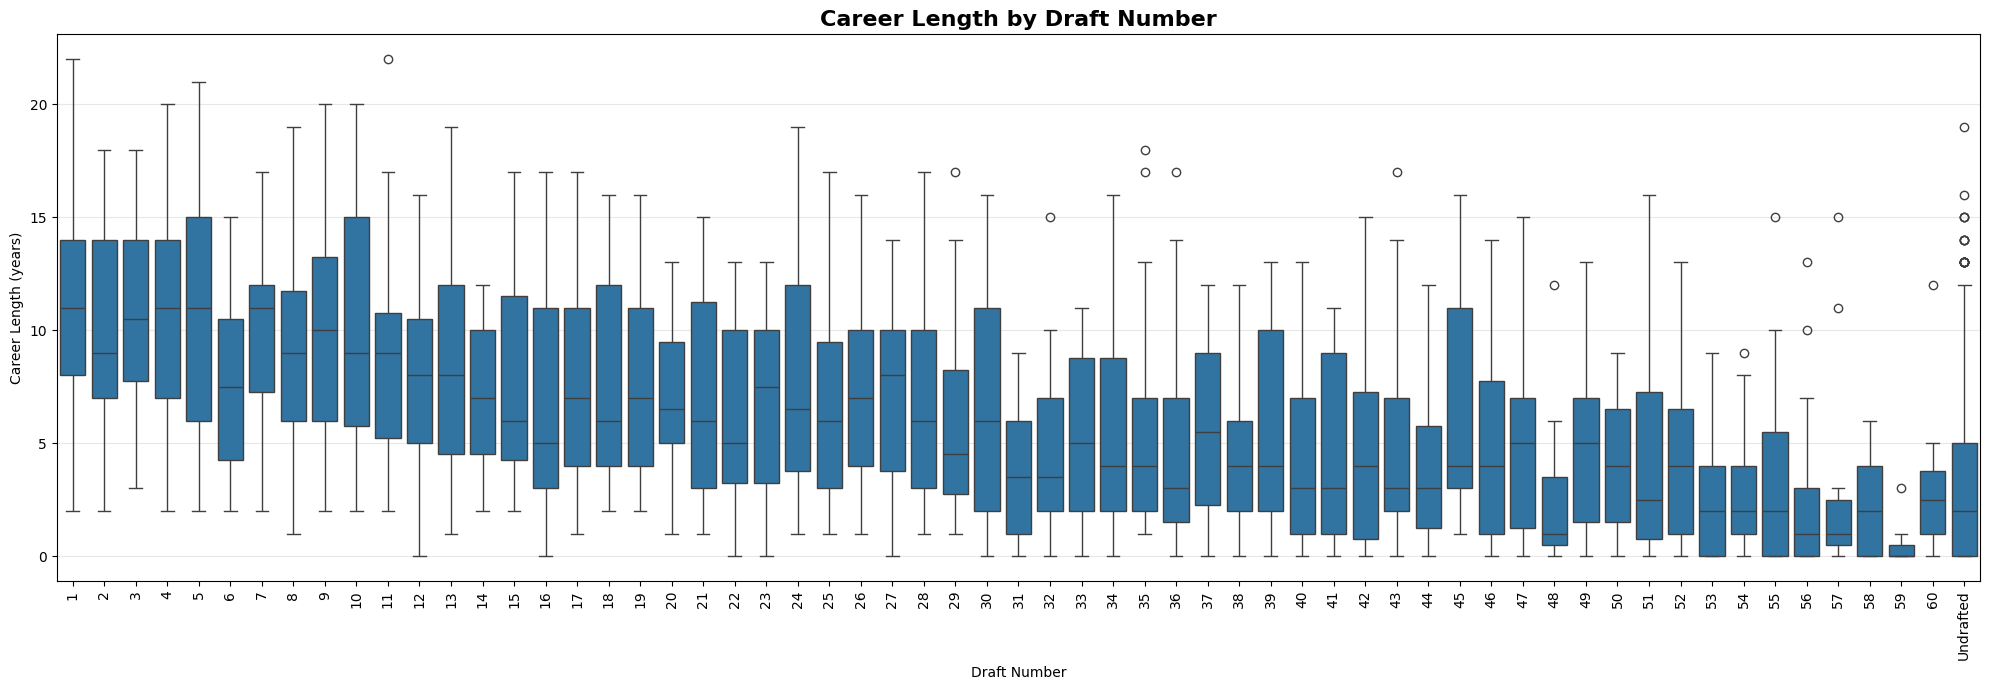

In [ ]:
# Grabbing the unique players
unique_players = cleaned_draft_and_shots_table.drop_duplicates(subset='PLAYER_ID')

drafted = sorted(unique_players[unique_players['draft_number'] != 'Undrafted']['draft_number'].dropna().unique().astype(int))
order = [str(x) for x in drafted] + ['Undrafted']

plt.figure(figsize=(20, 7))
sns.boxplot(data=unique_players, x=unique_players['draft_number'].astype(str), y='career_length', order=order)
plt.title('Career Length by Draft Number', fontsize=16, fontweight='bold')
plt.xlabel('Draft Number')
plt.ylabel('Career Length (years)')
plt.xticks(rotation=90)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

The above visual shows the distribution of career lengths by draft number. As we can see, the lower numbers (i.e picks 1,2, etc) have a wider variance of career lengths (and a higher mean) than the higher picks (i.e 60). This proves the claim that the higher you get drafted, the more opportunities you get.

#### Shot Volume vs. Draft Position

Does a player's draft number impact the amount of shots taken? We hypothesize yes, but let's see if the data confirms this.

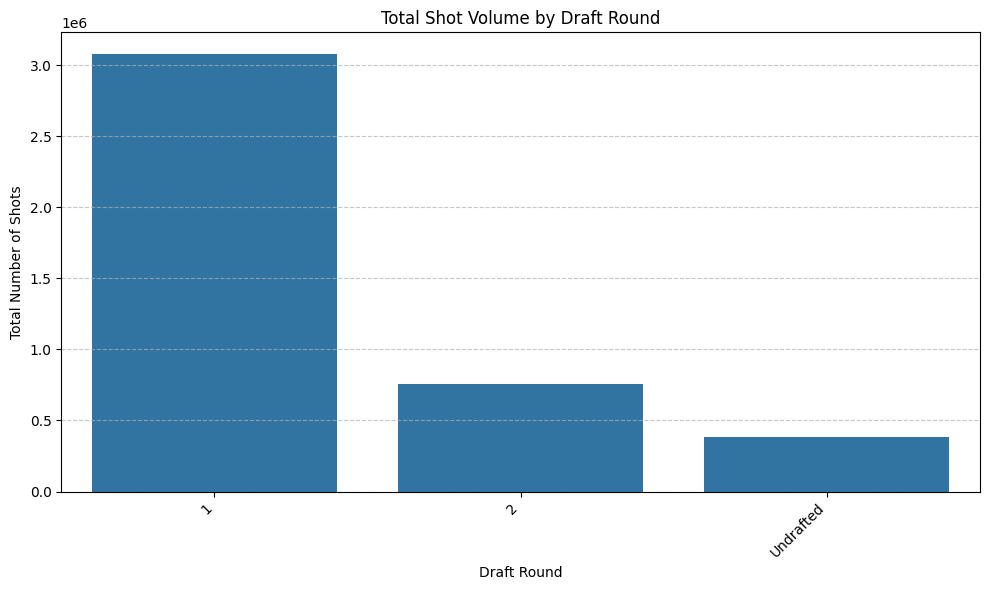

In [ ]:
shot_volume_by_draft_round = cleaned_draft_and_shots_table.groupby('draft_round').size()

plt.figure(figsize=(10, 6))
sns.barplot(x=shot_volume_by_draft_round.index, y=shot_volume_by_draft_round.values)
plt.title('Total Shot Volume by Draft Round')
plt.xlabel('Draft Round')
plt.ylabel('Total Number of Shots')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

As the above bar chart shows, players drafted in round 1 have a much higher shot volume than undrafted players and players drafted in round 2. This is simply a result of first round picks getting more playing time, having longer careers, thus giving them more shot attempts over the entire dataset.

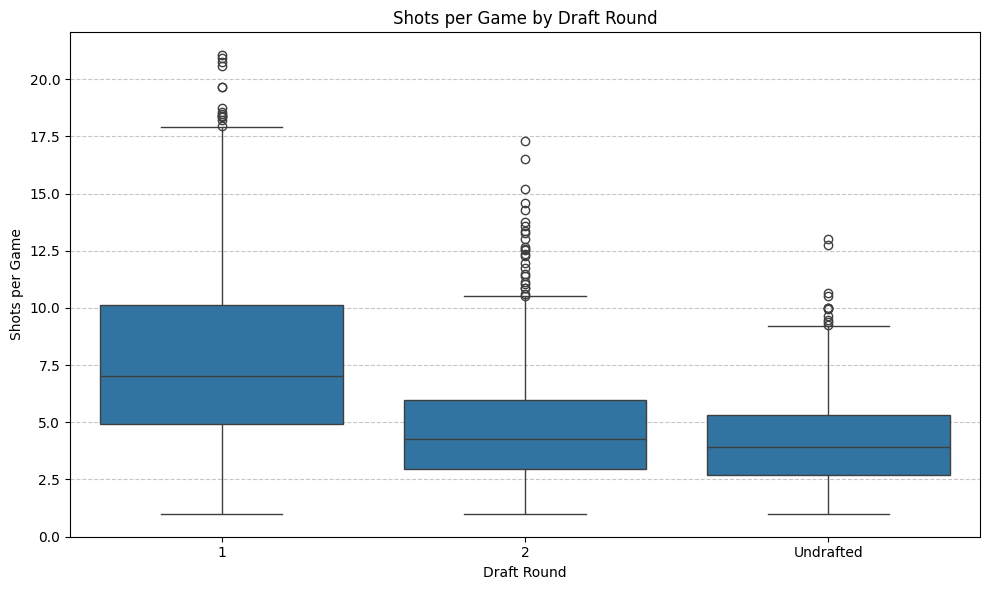

In [ ]:
per_player = (
    cleaned_draft_and_shots_table.groupby(['draft_round', 'PLAYER_ID'])
    .agg(shots=('PLAYER_ID', 'count'),
         games=('GAME_ID', 'nunique'))
    .reset_index()
)
per_player['shots_per_game'] = per_player['shots'] / per_player['games']

plt.figure(figsize=(10, 6))
sns.boxplot(data=per_player, x='draft_round', y='shots_per_game',
            order=['1', '2', 'Undrafted'])
plt.title('Shots per Game by Draft Round')
plt.xlabel('Draft Round')
plt.ylabel('Shots per Game')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

To address the difference in volume based on career lengths and total playing time above, we normalized the data to show shots per player per game by the draft round.

Round 1 picks take significantly more shots per game than round 2 and undrafted players, with a median of around 7 shots per game compared to roughly 4.5 for both round 2 and undrafted players. Round 1 has a much wider IQR (roughly 5 to 10) and a long upper tail reaching past 20 shots per game, which is where the high-usage stars like LeBron, Kobe, and Harden live. This reflects the reality that round 1 picks get the opportunity to become primary offensive options in a way that round 2 and undrafted players rarely do.

The similarity between round 2 and undrafted players is an interesting finding in itself. Once a player makes the roster regardless of draft status, their shot volume per game converges to roughly the same level, suggesting that the draft round distinction matters less for players who actually stick in the league. The selection pressure of just making and staying on a roster equalizes things. The difference is really about the ceiling, not the floor.

#### Shot Distance vs. Draft Position

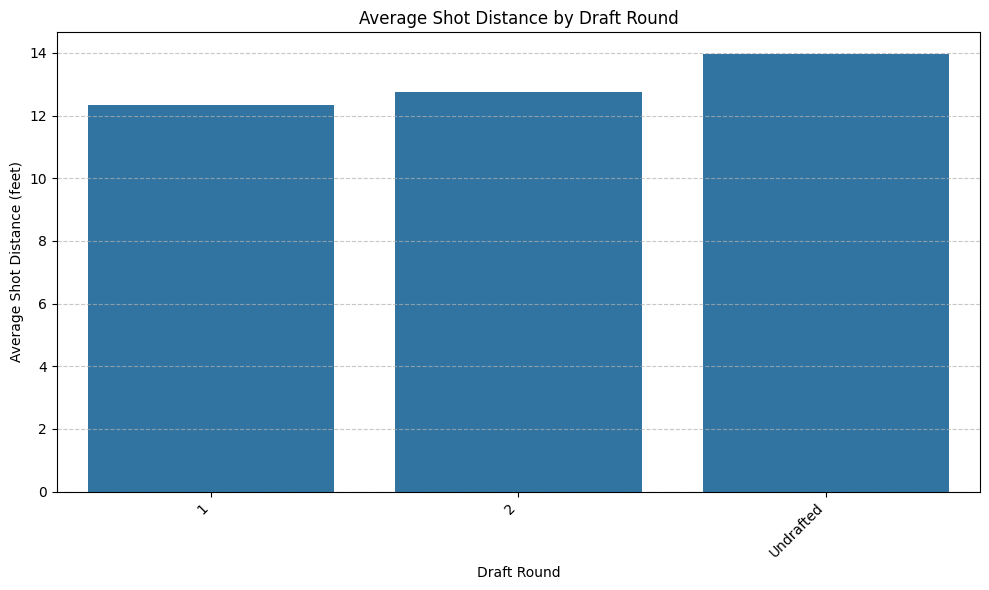

In [ ]:
avg_shot_distance_by_draft_round = cleaned_draft_and_shots_table.groupby('draft_round')['SHOT_DISTANCE'].mean()

plt.figure(figsize=(10, 6))
sns.barplot(x=avg_shot_distance_by_draft_round.index, y=avg_shot_distance_by_draft_round.values)
plt.title('Average Shot Distance by Draft Round')
plt.xlabel('Draft Round')
plt.ylabel('Average Shot Distance (feet)')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Average shot distance is roughly consistent across draft rounds, suggesting that draft position doesn't influence where on the floor a player operates.

#### Shot Success Rate vs. Draft Position

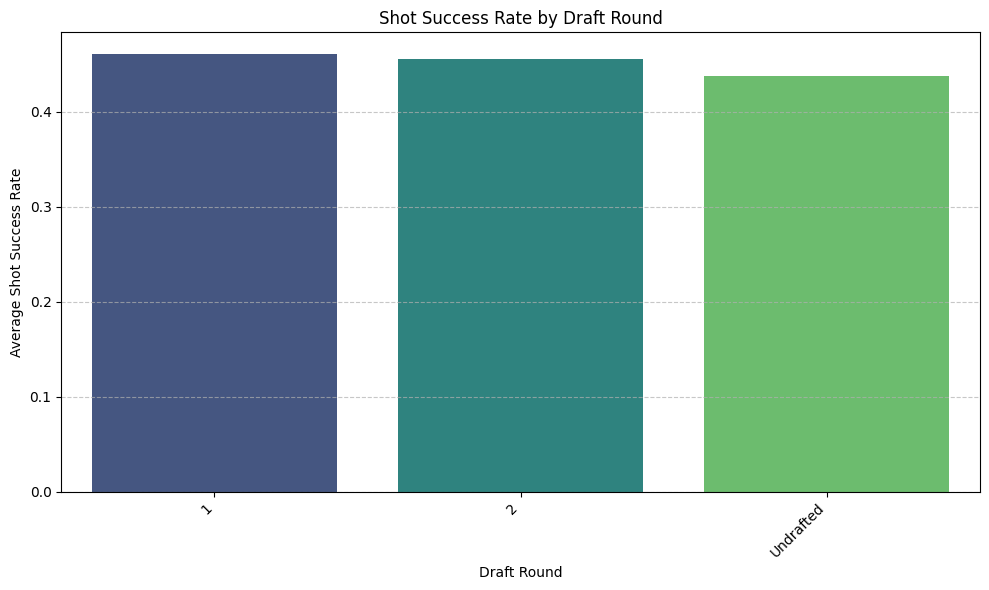

In [ ]:
shot_success_by_draft_round = cleaned_draft_and_shots_table.groupby('draft_round')['SHOT_MADE'].mean()

plt.figure(figsize=(10, 6))
sns.barplot(x=shot_success_by_draft_round.index, y=shot_success_by_draft_round.values, palette='viridis')
plt.title('Shot Success Rate by Draft Round')
plt.xlabel('Draft Round')
plt.ylabel('Average Shot Success Rate')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

The bar chart shows virtually no difference in shot success rate across draft rounds. Round 1, round 2, and undrafted players all convert at similar rates once they're actually in the league taking shots. This makes intuitive sense given that players who remain in the league long enough to accumulate meaningful shot volume have already proven they can compete at this level regardless of how they entered it. The draft round predicts opportunity and career length, as we saw in the shots per game analysis, but not the quality of a shot once it's taken.

### 4.11 Shooting Efficiency by Time Remaining in Quarter

In this section, we analyze league-average shooting efficiency based on how much time is left in the quarter. This analysis combines shots from all players in the dataset to identify overall trends rather than focusing on individual players.

Shots taken late in the quarter may be more rushed or more difficult, while earlier shots may come from more structured offensive possessions. By grouping shots based on time remaining, we compare league-average field goal percentage (FG%) and shot selection behavior across different levels of time pressure.

In [ ]:
q_cols = ['QUARTER', 'MINS_LEFT', 'SECS_LEFT', 'SHOT_MADE', 'SHOT_DISTANCE']
time_df = merged.loc[:, q_cols].dropna()

# Keep only regulation quarters
time_df = time_df[time_df['QUARTER'] <= 4]

# Convert to total seconds remaining in the quarter
time_df['time_remaining_sec'] = time_df['MINS_LEFT'] * 60 + time_df['SECS_LEFT']

# Create time buckets
time_df['time_group'] = pd.cut(
    time_df['time_remaining_sec'],
    bins=[0, 60, 180, 360, 720],
    labels=['0-1 min', '1-3 min', '3-6 min', '6-12 min'],
    include_lowest=True
)

# Summary table
time_summary = (
    time_df.groupby('time_group', observed=False)
    .agg(
        attempts=('SHOT_MADE', 'count'),
        fg_pct=('SHOT_MADE', 'mean'),
        avg_distance=('SHOT_DISTANCE', 'mean')
    ).reset_index()
)

time_summary['fg_pct'] = (time_summary['fg_pct'] * 100).round(2)
time_summary['avg_distance'] = time_summary['avg_distance'].round(2)

display(time_summary)

,time_group,attempts,fg_pct,avg_distance
0,0-1 min,419219,41.72,13.69
1,1-3 min,681400,46.02,12.36
2,3-6 min,1035140,46.64,12.24
3,6-12 min,2055755,46.35,12.34


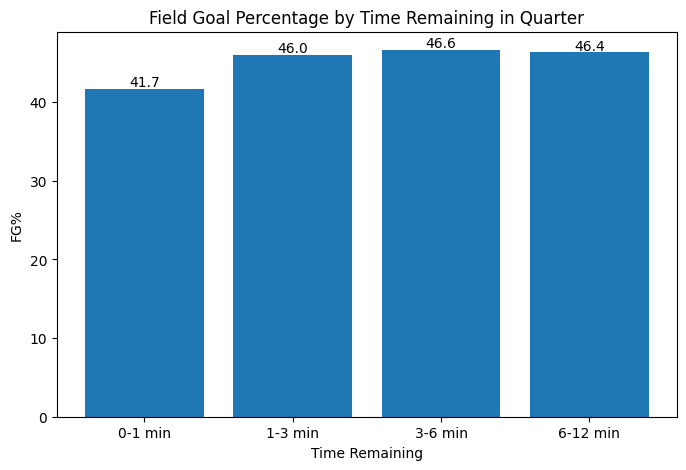

In [ ]:
plt.figure(figsize=(8,5))
plt.bar(time_summary['time_group'].astype(str),time_summary['fg_pct'])
plt.title("Field Goal Percentage by Time Remaining in Quarter")
plt.xlabel("Time Remaining")
plt.ylabel("FG%")

for i, val in enumerate(time_summary['fg_pct']):
    plt.text(i, val + 0.3, f'{val:.1f}', ha='center')

plt.show()

This graph shows the league-average field goal percentage (FG%) based on the amount of time remaining in the quarter. The results indicate that shooting efficiency is lowest in the final minute (41.7%) and higher earlier in the quarter, remaining relatively stable between the 1–12 minute intervals (around 46%). This suggests that last-minute pressure may lead to more difficult or rushed shots, which can slightly reduce shooting efficiency compared to earlier in the quarter.

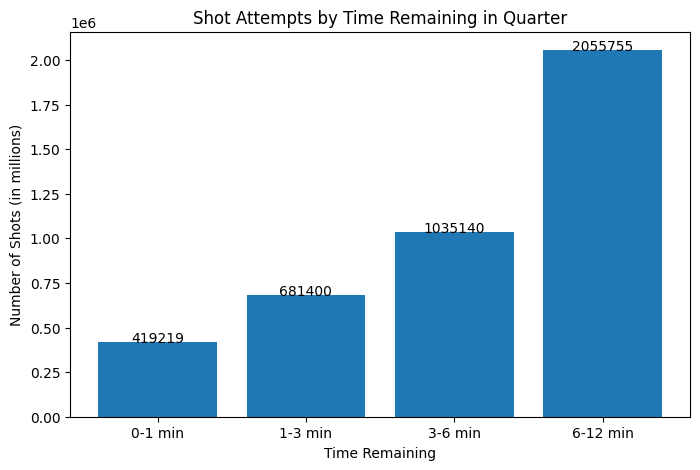

In [ ]:
plt.figure(figsize=(8,5))
plt.bar(time_summary['time_group'].astype(str),time_summary['attempts'])
plt.title("Shot Attempts by Time Remaining in Quarter")
plt.xlabel("Time Remaining")
plt.ylabel("Number of Shots (in millions)" )

for i, val in enumerate(time_summary['attempts']):
    plt.text(i, val + 5, f'{val}', ha='center')

plt.show()

This graph shows how many shots are taken at different times in the quarter. More total shots taken in the 6-12 minute range makes sense because the time window we are looking at is larger, and thus there are more possessions earlier in the quarter. We will normalize by shots per minute in each bucket below to make the analysis more comparable.

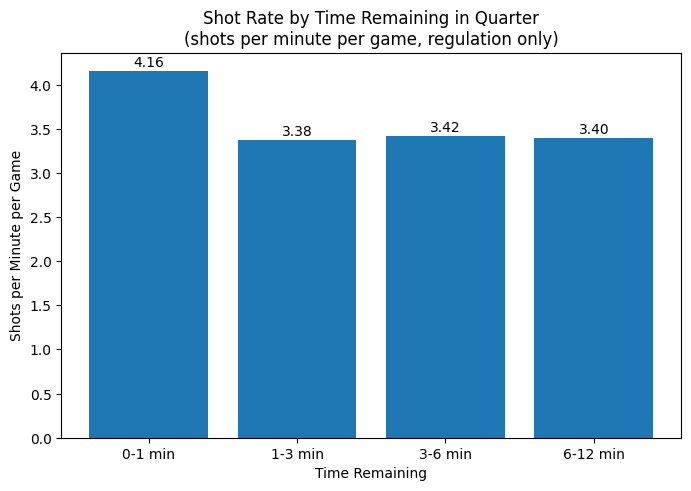

In [ ]:
n_games = merged['GAME_ID'].nunique()
n_quarters = 4

time_summary['duration_minutes'] = [1, 2, 3, 6]
time_summary['shots_per_min_per_game'] = (time_summary['attempts'] / time_summary['duration_minutes'] / n_games / n_quarters)

plt.figure(figsize=(8, 5))
plt.bar(time_summary['time_group'].astype(str), time_summary['shots_per_min_per_game'])
plt.title("Shot Rate by Time Remaining in Quarter\n(shots per minute per game, regulation only)")
plt.xlabel("Time Remaining")
plt.ylabel("Shots per Minute per Game")

for i, val in enumerate(time_summary['shots_per_min_per_game']):
    plt.text(i, val + 0.05, f'{val:.2f}', ha='center')

plt.show()

After normalizing for time window size and the number of games and quarters, the final minute stands out among the rest of the windows. Teams attempt shots at a rate of 4.16 per minute per game in the last minute of a quarter, compared to 3.38-3.42 across the rest of the quarter. The earlier unnormalized chart made it look like fewer shots were being taken late, but that was just a result of differing bucket widths. The 0-1 min window is six times narrower than the 6-12 min window, but once we account for that, we can see that teams are actually shooting at a meaningfully higher rate as the clock winds down, consistent with the urgency of end-of-quarter possessions, 2-for-1 possessions, and buzzer-beater attempts. This pairs well with the FG% finding above, as teams are shooting more in the final minute but converting at a lower rate, suggesting the shot quality is declining even as the volume goes up.

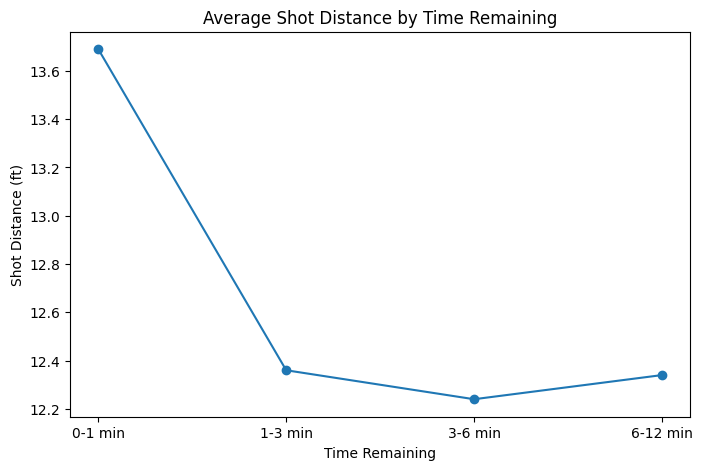

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    time_summary['time_group'].astype(str),
    time_summary['avg_distance'],
    marker='o'
)

plt.title("Average Shot Distance by Time Remaining")
plt.xlabel("Time Remaining")
plt.ylabel("Shot Distance (ft)")

plt.show()

This graph shows the average shot distance at different times remaining in the quarter. The results show that shots taken in the final minute are farther from the basket compared to shots taken earlier in the quarter. This suggests that players may take more difficult or rushed shots when time is running out. Earlier in the quarter, shot distance stays fairly consistent, which may reflect more controlled and structured offensive plays.

In [ ]:
quarter_time_summary = time_df.groupby(
    ['QUARTER', 'time_group'],
    observed=False
).agg(
    attempts=('SHOT_MADE', 'count'),
    fg_pct=('SHOT_MADE', 'mean')
).reset_index()

quarter_time_summary['fg_pct'] = (
    quarter_time_summary['fg_pct'] * 100
).round(2)

display(quarter_time_summary)

,QUARTER,time_group,attempts,fg_pct
0,1,0-1 min,106182,41.92
1,1,1-3 min,175804,46.48
2,1,3-6 min,272488,47.74
3,1,6-12 min,545468,47.46
4,2,0-1 min,106521,42.79
5,2,1-3 min,172465,47.55
6,2,3-6 min,262691,47.13
7,2,6-12 min,512929,45.93
8,3,0-1 min,102767,40.81
9,3,1-3 min,166033,45.45


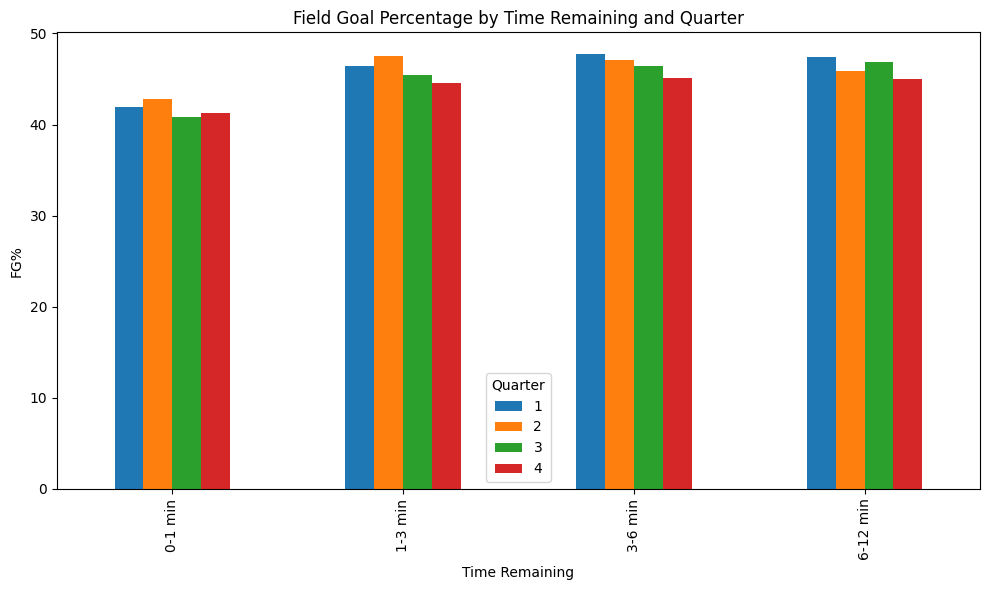

In [ ]:
pivot_fg = quarter_time_summary.pivot(index='time_group',columns='QUARTER',values='fg_pct')
pivot_fg.plot(kind='bar', figsize=(10,6))
plt.title("Field Goal Percentage by Time Remaining and Quarter")
plt.xlabel("Time Remaining")
plt.ylabel("FG%")
plt.legend(title="Quarter")
plt.tight_layout()
plt.show()

This graph shows the field goal percentage (FG%) at different times remaining in the quarter across the game. Overall, shooting efficiency is lowest in the final minute and higher earlier in the quarter. This suggests that players may take more difficult or rushed shots when time is running out, which can slightly reduce shooting efficiency. Earlier in the quarter, efficiency stays fairly consistent, likely because players have more time to run structured offensive plays.

## 5: Feature Engineering




Below, we are doing some feature engineering and data processing as we get ready to model.

`shot_zone_share_vs_avg` extracts the era-adjusted zone deviation for the specific zone each shot was taken from, giving us a continuous measure of how characteristic that zone is for the shooter in that season. `is_characteristic_zone` converts it into a binary flag for interpretability, indicating whether or not the specific shot came from a zone the player
over-indexes in or not. `specialization_strength` takes the absolute value, capturing how strongly specialized the player is in this zone regardless of direction, which lets the model pick up on the fact that a player who is heavily non-characteristic in a zone is just as distinctive as one who is heavily characteristic.

Since random forest requires numeric inputs, we need to encode columns like
`action_bucket`, `simple_position`, `SHOT_TYPE`, and `ZONE_RANGE` as integers. These are categorical variables with no meaningful ordinal relationship,
but random forest handles this well by splitting on individual values rather than treating the encoding as a continuous scale.


### 5.1 Action Type Bucketing

The raw `ACTION_TYPE` column has over 60 distinct values, most of which are
variations of the same baseline action. Passing all 60 values directly
into a model would add noise without adding signal, so we consolidate them into
five broader buckets: Jump Shot, Layup/Dunk, Floater, Hook Shot, and
Other. That captures the shot type that actually matter for
predicting shot difficulty. The bucketing decisions are based on the action type
efficiency patterns we observed in section 1.5.

In [ ]:
print(merged['ACTION_TYPE'].value_counts().to_string())

ACTION_TYPE
Jump Shot                             1994453
Layup Shot                             437829
Driving Layup Shot                     288735
Pullup Jump shot                       231328
Step Back Jump shot                     85049
Turnaround Jump Shot                    70918
Dunk Shot                               67837
Running Jump Shot                       67561
Hook Shot                               66326
Driving Floating Jump Shot              65841
Fadeaway Jump Shot                      64249
Floating Jump shot                      58095
Running Layup Shot                      55288
Tip Shot                                46728
Driving Finger Roll Layup Shot          45454
Cutting Layup Shot                      42926
Reverse Layup Shot                      42579
Tip Layup Shot                          39178
Putback Layup Shot                      35111
Turnaround Fadeaway shot                30572
Alley Oop Dunk Shot                     28203
Jump Bank Shot        

In [ ]:
action_map = {
    'Jump Shot':                          'Jump Shot',
    'Pullup Jump shot':                   'Jump Shot',
    'Step Back Jump shot':                'Jump Shot',
    'Fadeaway Jump Shot':                 'Jump Shot',
    'Turnaround Jump Shot':               'Jump Shot',
    'Running Jump Shot':                  'Jump Shot',
    'Jump Bank Shot':                     'Jump Shot',
    'Running Pull-Up Jump Shot':          'Jump Shot',
    'Driving Jump shot':                  'Jump Shot',
    'Running Bank shot':                  'Jump Shot',
    'Turnaround Bank shot':               'Jump Shot',
    'Driving Bank shot':                  'Jump Shot',
    'Turnaround Fadeaway Bank Jump Shot': 'Jump Shot',
    'Fadeaway Bank shot':                 'Jump Shot',
    'Pullup Bank shot':                   'Jump Shot',
    'Step Back Bank Jump Shot':           'Jump Shot',
    'Layup Shot':                         'Layup/Dunk',
    'Driving Layup Shot':                 'Layup/Dunk',
    'Running Layup Shot':                 'Layup/Dunk',
    'Reverse Layup Shot':                 'Layup/Dunk',
    'Cutting Layup Shot':                 'Layup/Dunk',
    'Tip Layup Shot':                     'Layup/Dunk',
    'Putback Layup Shot':                 'Layup/Dunk',
    'Driving Reverse Layup Shot':         'Layup/Dunk',
    'Running Reverse Layup Shot':         'Layup/Dunk',
    'Alley Oop Layup shot':               'Layup/Dunk',
    'Running Alley Oop Layup Shot':       'Layup/Dunk',
    'Dunk Shot':                          'Layup/Dunk',
    'Alley Oop Dunk Shot':                'Layup/Dunk',
    'Driving Dunk Shot':                  'Layup/Dunk',
    'Cutting Dunk Shot':                  'Layup/Dunk',
    'Slam Dunk Shot':                     'Layup/Dunk',
    'Running Dunk Shot':                  'Layup/Dunk',
    'Putback Dunk Shot':                  'Layup/Dunk',
    'Running Alley Oop Dunk Shot':        'Layup/Dunk',
    'Tip Dunk Shot':                      'Layup/Dunk',
    'Driving Slam Dunk Shot':             'Layup/Dunk',
    'Reverse Dunk Shot':                  'Layup/Dunk',
    'Follow Up Dunk Shot':                'Layup/Dunk',
    'Putback Slam Dunk Shot':             'Layup/Dunk',
    'Running Slam Dunk Shot':             'Layup/Dunk',
    'Driving Reverse Dunk Shot':          'Layup/Dunk',
    'Running Reverse Dunk Shot':          'Layup/Dunk',
    'Reverse Slam Dunk Shot':             'Layup/Dunk',
    'Putback Reverse Dunk Shot':          'Layup/Dunk',
    'Floating Jump shot':                 'Floater',
    'Driving Floating Jump Shot':         'Floater',
    'Driving Floating Bank Jump Shot':    'Floater',
    'Driving Finger Roll Layup Shot':     'Floater',
    'Finger Roll Layup Shot':             'Floater',
    'Running Finger Roll Layup Shot':     'Floater',
    'Cutting Finger Roll Layup Shot':     'Floater',
    'Driving Finger Roll Shot':           'Floater',
    'Finger Roll Shot':                   'Floater',
    'Running Finger Roll Shot':           'Floater',
    'Hook Shot':                          'Post/Hook',
    'Driving Hook Shot':                  'Post/Hook',
    'Turnaround Fadeaway shot':           'Post/Hook',
    'Turnaround Hook Shot':               'Post/Hook',
    'Jump Hook Shot':                     'Post/Hook',
    'Running Hook Shot':                  'Post/Hook',
    'Hook Bank Shot':                     'Post/Hook',
    'Jump Bank Hook Shot':                'Post/Hook',
    'Turnaround Bank Hook Shot':          'Post/Hook',
    'Driving Bank Hook Shot':             'Post/Hook',
    'Running Bank Hook Shot':             'Post/Hook',
    'Turnaround Finger Roll Shot':        'Post/Hook',
    'Tip Shot':                           'Tip/Other',
    'Running Tip Shot':                   'Tip/Other',
}

merged['action_bucket'] = merged['ACTION_TYPE'].map(action_map).fillna('Other')
merged = merged[merged['ACTION_TYPE'] != 'No Shot']

### 5.2 Specialization Feature Construction

With the era-adjusted zone profiles built in section 4.6, we can also include
specialization context to each individual shot. For every shot in the modeling
dataset, we look up the shooter's `share_vs_avg` for the zone that shot was
taken from in that season. This gives us three features: a continuous measure
of how characteristic that zone is for the shooter (`shot_zone_share_vs_avg`),
a binary flag for whether it's a characteristic zone at all (`is_characteristic_zone`), and the absolute value of the deviation as a measure of specialization strength regardless of direction (`specialization_strength`). Together these features let the model distinguish between a player shooting in their comfort zone versus one taking shots they rarely attempt.

In [ ]:
zone_col_map = {
    'Less Than 8 ft.': 'Less Than 8 ft._share_vs_avg',
    '8-16 ft.': '8-16 ft._share_vs_avg',
    '16-24 ft.': '16-24 ft._share_vs_avg',
    '24+ ft.': '24+ ft._share_vs_avg',
}

model_df = merged.merge(
    player_seasons_full[['PLAYER_ID', 'SEASON_1',
                         'Less Than 8 ft._share_vs_avg',
                         '8-16 ft._share_vs_avg',
                         '16-24 ft._share_vs_avg',
                         '24+ ft._share_vs_avg']],
    on=['PLAYER_ID', 'SEASON_1'],
    how='inner'
)

# Get the share_vs_avg for the zone each shot was taken from
def get_shot_zone_share_vs_avg(row):
    col = zone_col_map.get(row['ZONE_RANGE'])
    if col is None:
        return np.nan
    return row[col]

#model_df['shot_zone_share_vs_avg'] = model_df.apply(get_shot_zone_share_vs_avg, axis=1)
model_df['shot_zone_share_vs_avg'] = np.where( # using apply seemed to crash the notebook
    model_df['ZONE_RANGE'] == 'Less Than 8 ft.', model_df['Less Than 8 ft._share_vs_avg'],
    np.where(
        model_df['ZONE_RANGE'] == '8-16 ft.', model_df['8-16 ft._share_vs_avg'],
        np.where(
            model_df['ZONE_RANGE'] == '16-24 ft.', model_df['16-24 ft._share_vs_avg'],
            np.where(
                model_df['ZONE_RANGE'] == '24+ ft.', model_df['24+ ft._share_vs_avg'],
                np.nan
            )
        )
    )
)
model_df['is_characteristic_zone'] = (model_df['shot_zone_share_vs_avg'] > 0).astype(int)
model_df['specialization_strength'] = model_df['shot_zone_share_vs_avg'].abs()

We will do some encoding and a bit more cleaning before we get to our final model dataset. We drop any rows with missing values in the required columns, filter to the three main positions, and restrict to the four primary zones. We also combine `MINS_LEFT` and `SECS_LEFT` into a single `time_remaining` field in seconds since the two columns together are what actually captures game situation.

We also encode the categorical columns `action_bucket`, `simple_position`, `SHOT_TYPE`, and `ZONE_RANGE`. We treat the encodings
as category identifiers rather than them being on a continuous scale. We also take the absolute value of `LOC_X` since the court is symmetric and a shot at -5 and +5 are bascially identical, which we confirmed in section 1.4.

In [ ]:
required_cols = ['SHOT_MADE', 'SHOT_DISTANCE', 'SHOT_TYPE', 'action_bucket',
                 'QUARTER', 'MINS_LEFT', 'SECS_LEFT', 'age', 'years_in_league',
                 'simple_position', 'shot_zone_share_vs_avg', 'ZONE_RANGE']

model_df = model_df.dropna(subset=required_cols)
model_df = model_df[model_df['simple_position'].isin(['Guard', 'Forward', 'Center'])]
model_df = model_df[model_df['ZONE_RANGE'].isin(ZONES)]

model_df['time_remaining'] = model_df['MINS_LEFT'] * 60 + model_df['SECS_LEFT']

# Encode categoricals
le_action = LabelEncoder()
le_position = LabelEncoder()
le_shottype = LabelEncoder()
le_zone = LabelEncoder()

model_df['action_enc'] = le_action.fit_transform(model_df['action_bucket'])
model_df['position_enc'] = le_position.fit_transform(model_df['simple_position'])
model_df['shottype_enc'] = le_shottype.fit_transform(model_df['SHOT_TYPE'])
model_df['zone_enc'] = le_zone.fit_transform(model_df['ZONE_RANGE'])

model_df['LOC_X_abs'] = abs(model_df['LOC_X'])

print(f"Modeling dataset shape: {model_df.shape}")
print(f"Shot make rate: {model_df['SHOT_MADE'].mean():.3f}")
print(f"\nShots per zone:")
print(model_df['ZONE_RANGE'].value_counts())

model_df.head()

Modeling dataset shape: (4203799, 59)
Shot make rate: 0.459

Shots per zone:
ZONE_RANGE
Less Than 8 ft.    1731537
24+ ft.            1190426
16-24 ft.           680925
8-16 ft.            600911
Name: count, dtype: int64


,SEASON_1,SEASON_2,TEAM_ID,TEAM_NAME,PLAYER_ID,PLAYER_NAME,POSITION_GROUP,POSITION,GAME_DATE,GAME_ID,HOME_TEAM,AWAY_TEAM,EVENT_TYPE,SHOT_MADE,ACTION_TYPE,SHOT_TYPE,BASIC_ZONE,ZONE_NAME,ZONE_ABB,ZONE_RANGE,LOC_X,LOC_Y,SHOT_DISTANCE,QUARTER,MINS_LEFT,SECS_LEFT,person_id,name,birthdate,position,height,weight,school,country,draft_year,draft_round,draft_number,from_year,to_year,team_name,birth_year,height_inches,simple_position,age,years_in_league,action_bucket,Less Than 8 ft._share_vs_avg,8-16 ft._share_vs_avg,16-24 ft._share_vs_avg,24+ ft._share_vs_avg,shot_zone_share_vs_avg,is_characteristic_zone,specialization_strength,time_remaining,action_enc,position_enc,shottype_enc,zone_enc,LOC_X_abs
0,2004,2003-04,1610612747,Los Angeles Lakers,977,Kobe Bryant,G,SG,04-14-2004,20301187,POR,LAL,Made Shot,True,Jump Shot,3PT Field Goal,Above the Break 3,Left Side Center,LC,24+ ft.,20.0,21.35,25,6,0,0,977,Kobe Bryant,1978-08-23T00:00:00,Forward-Guard,6-6,212.0,Lower Merion HS (PA),USA,1996,1,13,1996,2015,Lakers,1978,78.0,Forward,25,9,Jump Shot,0.013955,0.000687,-0.009952,-0.004689,-0.004689,0,0.004689,0,1,1,1,1,20.0
1,2004,2003-04,1610612757,Portland Trail Blazers,757,Damon Stoudamire,G,PG,04-14-2004,20301187,POR,LAL,Made Shot,True,Driving Layup Shot,2PT Field Goal,Restricted Area,Center,C,Less Than 8 ft.,-0.0,5.25,0,6,0,2,757,Damon Stoudamire,1973-09-03T00:00:00,Guard,5-10,171.0,Arizona,USA,1995,1,7,1995,2007,Trail Blazers,1973,70.0,Guard,30,10,Layup/Dunk,-0.197743,-0.047741,0.013449,0.232035,-0.197743,0,0.197743,2,2,2,0,3,0.0
2,2004,2003-04,1610612747,Los Angeles Lakers,977,Kobe Bryant,G,SG,04-14-2004,20301187,POR,LAL,Missed Shot,False,Jump Shot,2PT Field Goal,Mid-Range,Left Side Center,LC,16-24 ft.,13.3,24.45,23,6,0,9,977,Kobe Bryant,1978-08-23T00:00:00,Forward-Guard,6-6,212.0,Lower Merion HS (PA),USA,1996,1,13,1996,2015,Lakers,1978,78.0,Forward,25,9,Jump Shot,0.013955,0.000687,-0.009952,-0.004689,-0.009952,0,0.009952,9,1,1,0,0,13.3
3,2004,2003-04,1610612757,Portland Trail Blazers,757,Damon Stoudamire,G,PG,04-14-2004,20301187,POR,LAL,Made Shot,True,Jump Shot,2PT Field Goal,Mid-Range,Left Side,L,16-24 ft.,16.4,13.95,18,6,0,31,757,Damon Stoudamire,1973-09-03T00:00:00,Guard,5-10,171.0,Arizona,USA,1995,1,7,1995,2007,Trail Blazers,1973,70.0,Guard,30,10,Jump Shot,-0.197743,-0.047741,0.013449,0.232035,0.013449,1,0.013449,31,1,2,0,0,16.4
4,2004,2003-04,1610612757,Portland Trail Blazers,757,Damon Stoudamire,G,PG,04-14-2004,20301187,POR,LAL,Missed Shot,False,Jump Shot,2PT Field Goal,Mid-Range,Right Side,R,16-24 ft.,-15.8,7.85,16,6,0,55,757,Damon Stoudamire,1973-09-03T00:00:00,Guard,5-10,171.0,Arizona,USA,1995,1,7,1995,2007,Trail Blazers,1973,70.0,Guard,30,10,Jump Shot,-0.197743,-0.047741,0.013449,0.232035,0.013449,1,0.013449,55,1,2,0,0,15.8


The dataset has over 4.2 million shots after merging and cleaning, which gives us enough data and predictive power to detect meaningful differences. The make rate is consistent with the league-wide FG% we observed in Section 1.

### 5.3 Distribution of Shot Zone Share vs. Average

Before modeling, we take a quick look at the specialization features to
understand their distributions and validate that they behave as expected.

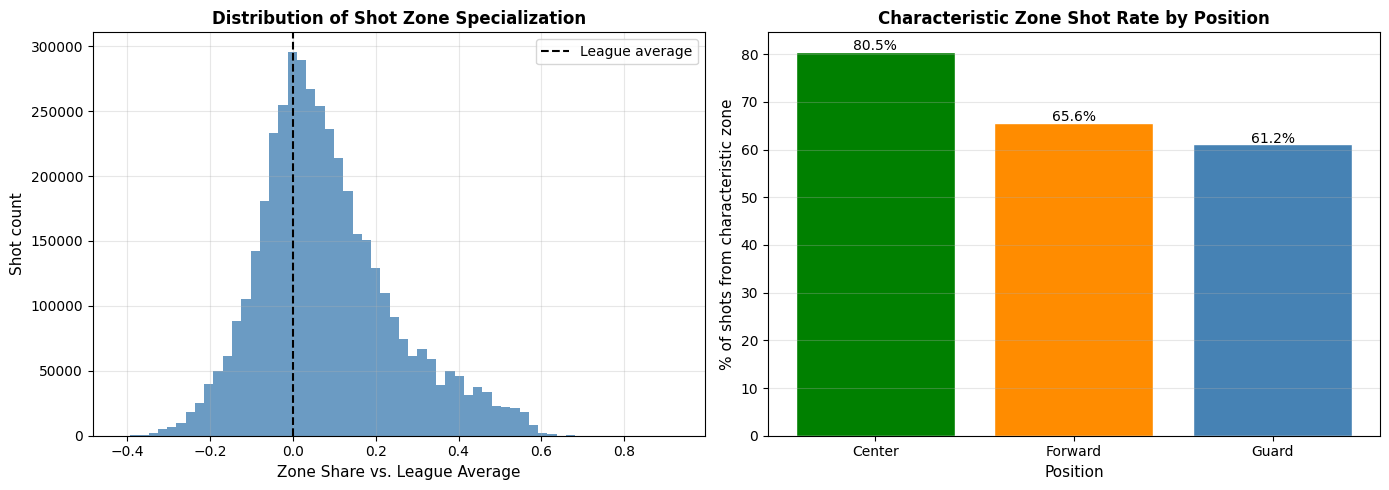

In [ ]:
fig, (p1, p2) = plt.subplots(1, 2, figsize=(14, 5))

p1.hist(model_df['shot_zone_share_vs_avg'], bins=60,
        color='steelblue', edgecolor='none', alpha=0.8)
p1.axvline(0, color='black', linestyle='--', lw=1.5, label='League average')
p1.set_xlabel('Zone Share vs. League Average', fontsize=11)
p1.set_ylabel('Shot count', fontsize=11)
p1.set_title('Distribution of Shot Zone Specialization', fontsize=12, fontweight='bold')
p1.legend()
p1.grid(alpha=0.3)

pos_color_map = {'Guard': 'steelblue', 'Forward': 'darkorange', 'Center': 'green'}
char_zone_by_pos = model_df.groupby('simple_position')['is_characteristic_zone'].mean() * 100
bar_colors = [pos_color_map[pos] for pos in char_zone_by_pos.index]

p2.bar(char_zone_by_pos.index, char_zone_by_pos.values,
       color=bar_colors, edgecolor='white')
p2.set_xlabel('Position', fontsize=11)
p2.set_ylabel('% of shots from characteristic zone', fontsize=11)
p2.set_title('Characteristic Zone Shot Rate by Position', fontsize=12, fontweight='bold')
for i, val in enumerate(char_zone_by_pos.values):
    p2.text(i, val + 0.3, f'{val:.1f}%', ha='center', fontsize=10)
p2.grid(axis='y', alpha=0.3)

plt.tight_layout()


The distribution of `shot_zone_share_vs_avg` is centered near zero whic is expected. We constructed the variable so that the league-wide average of zone deviations is zero. The slight right skew is the more interesting
finding. It suggests that players who specialize heavily in a zone tend to
take a disproportionate share of shots there, while players who are below
average in a zone are more evenly spread. In other words, extreme specialization
is more common in one direction than the other. You see more players who are
dramatically above average in a zone than players who are dramatically below it.

The characteristic zone shot rate chart on the right breaks this down by
position and reinforces the positional identities we built in section 4.
Centers have the highest characteristic zone rate at 80.5%, meaning 4 out of
every 5 center shots come from a zone they over-index in (most likely Less Than 8ft. shot). This reflects how narrowly defined center shot profiles are. Most centers operate almost exclusively at the rim and have very little zone diversity. Guards are the lowest at 61.2%, which makes sense given that guards take shots from a wider variety of locations and are less rigidly confined to specific zones. Forwards sit in between at 65.6%. The ordering maps directly onto how positionally specialized each role is, and validates that our `is_characteristic_zone` flag is capturing genuine role identity rather than random noise.

### 5.4 Raw FG% in Characteristic vs. Non-Characteristic Zones

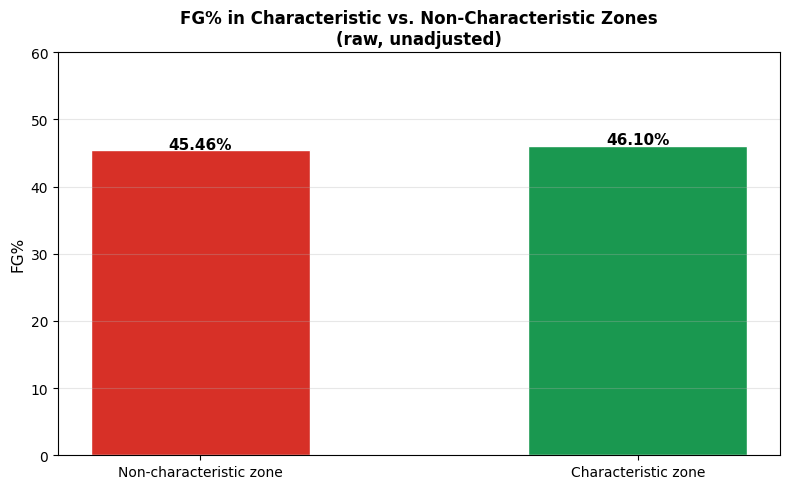

In [ ]:
char_fg = model_df.groupby('is_characteristic_zone')['SHOT_MADE'].mean() * 100

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(['Non-characteristic zone', 'Characteristic zone'],
              char_fg.values, color=['#d73027', '#1a9850'], edgecolor='white',
              width=0.5)
for bar, val in zip(bars, char_fg.values):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.2,
            f'{val:.2f}%', ha='center', fontsize=11, fontweight='bold')
ax.set_ylabel('FG%', fontsize=11)
ax.set_title('FG% in Characteristic vs. Non-Characteristic Zones\n(raw, unadjusted)',
             fontsize=12, fontweight='bold')
ax.set_ylim(0, 60)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()


The raw FG% difference between characteristic and non-characteristic zones is
small but in the expected direction, as it is 46.10% in characteristic zones vs. 45.46% outside them. The gap is only 0.64%, which on its own isn't a
compelling finding. A player who over-indexes at the rim will show both a high characteristic zone rate and a high FG% simply because rim shots are easier, not because specialization itself is driving efficiency. The future model in sections 5.3 and 5.4 controls for this by including shot distance, zone, and action type, isolating whether specialization adds signal on top of the difficulty of the shot itself.

### 5.5 Specialization Strength by Age

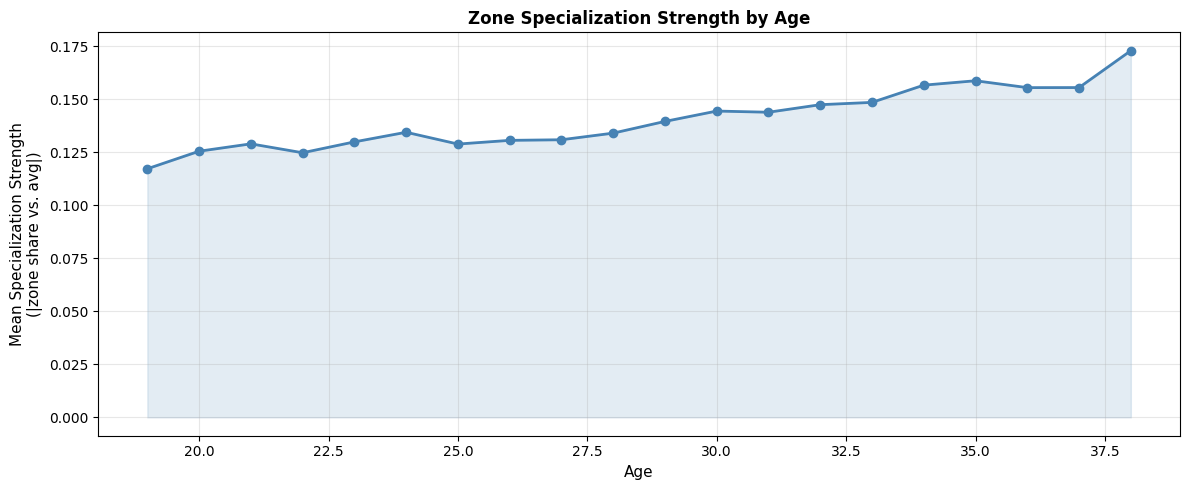

In [ ]:
age_spec = model_df[(model_df['age'] >= 19) & (model_df['age'] <= 38)].groupby('age').agg(
    mean_specialization=('specialization_strength', 'mean'),
    count=('SHOT_MADE', 'count')
).reset_index()
age_spec = age_spec[age_spec['count'] >= 500]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(age_spec['age'], age_spec['mean_specialization'],
        marker='o', linewidth=2, color='steelblue')
ax.fill_between(age_spec['age'], age_spec['mean_specialization'],
                alpha=0.15, color='steelblue')
ax.set_xlabel('Age', fontsize=11)
ax.set_ylabel('Mean Specialization Strength\n(|zone share vs. avg|)', fontsize=11)
ax.set_title('Zone Specialization Strength by Age', fontsize=12, fontweight='bold')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Zone specialization strength tends to increase with age which makes sense. Veteran players have had more time to refine their game around their strengths
and decrease shots from zones where they're less effective. Young players are more likely to take a wider variety of shots as they're still developing their identity. This trend also motivates including age as an interaction with specialization in the model rather than just as a standalone feature.

### 5.6 Zone Specialization and Shooting Efficiency

We examine the relationship between zone specialization and shooting efficiency. As a player shoots more from a zone relative to league average, do they also shoot better in that zone relative to league average?

Using FG% vs. league average rather than raw FG% controls for the fact that some
zones are easier. For example, a center shooting 65% at the rim isn't impressive if the league average there is 62%. This is the same logic we applied to zone shares.

In [ ]:
league_zone_fg = (
    zone_stats
    .groupby(['SEASON_1', 'ZONE_RANGE'])
    .agg(league_makes=('makes', 'sum'),
         league_attempts=('attempts', 'sum'))
    .reset_index()
)
league_zone_fg['league_fg_pct'] = (
    league_zone_fg['league_makes'] / league_zone_fg['league_attempts']
)

# Join league average FG% onto player-season-zone data
zone_analysis = zone_stats.merge(
    league_zone_fg[['SEASON_1', 'ZONE_RANGE', 'league_fg_pct']],
    on=['SEASON_1', 'ZONE_RANGE'],
    how='left'
)

zone_analysis['fg_pct_vs_avg'] = zone_analysis['fg_pct'] - zone_analysis['league_fg_pct']

share_vs_avg_long = player_seasons_full.melt(
    id_vars=['PLAYER_ID', 'SEASON_1', 'age'],
    value_vars=[f'{z}_share_vs_avg' for z in ZONES],
    var_name='zone_col',
    value_name='share_vs_avg'
)
share_vs_avg_long['ZONE_RANGE'] = share_vs_avg_long['zone_col'].str.replace(
    '_share_vs_avg', ''
)
share_vs_avg_long = share_vs_avg_long.drop(columns='zone_col')

zone_analysis = zone_analysis.merge(
    share_vs_avg_long[['PLAYER_ID', 'SEASON_1', 'ZONE_RANGE', 'share_vs_avg', 'age']],
    on=['PLAYER_ID', 'SEASON_1', 'ZONE_RANGE'],
    how='inner'
)

zone_analysis = zone_analysis[zone_analysis['attempts'] >= 20].copy()

print(f"Player-season-zone observations: {len(zone_analysis):,}")
print(f"\nShare vs avg summary:")
print(zone_analysis['share_vs_avg'].describe().round(3))
print(f"\nFG% vs avg summary:")
print(zone_analysis['fg_pct_vs_avg'].describe().round(3))


Player-season-zone observations: 27,163

Share vs avg summary:
count    27163.000
mean         0.039
std          0.157
min         -0.379
25%         -0.057
50%          0.013
75%          0.112
max          0.667
Name: share_vs_avg, dtype: float64

FG% vs avg summary:
count    27163.000
mean        -0.014
std          0.072
min         -0.363
25%         -0.056
50%         -0.010
75%          0.032
max          0.338
Name: fg_pct_vs_avg, dtype: float64


We put `share_vs_avg` into bins and plot the mean `fg_pct_vs_avg` for each
bin. A positive slope would confirm that players who specialize heavily in a
zone also shoot above league average in that zone.

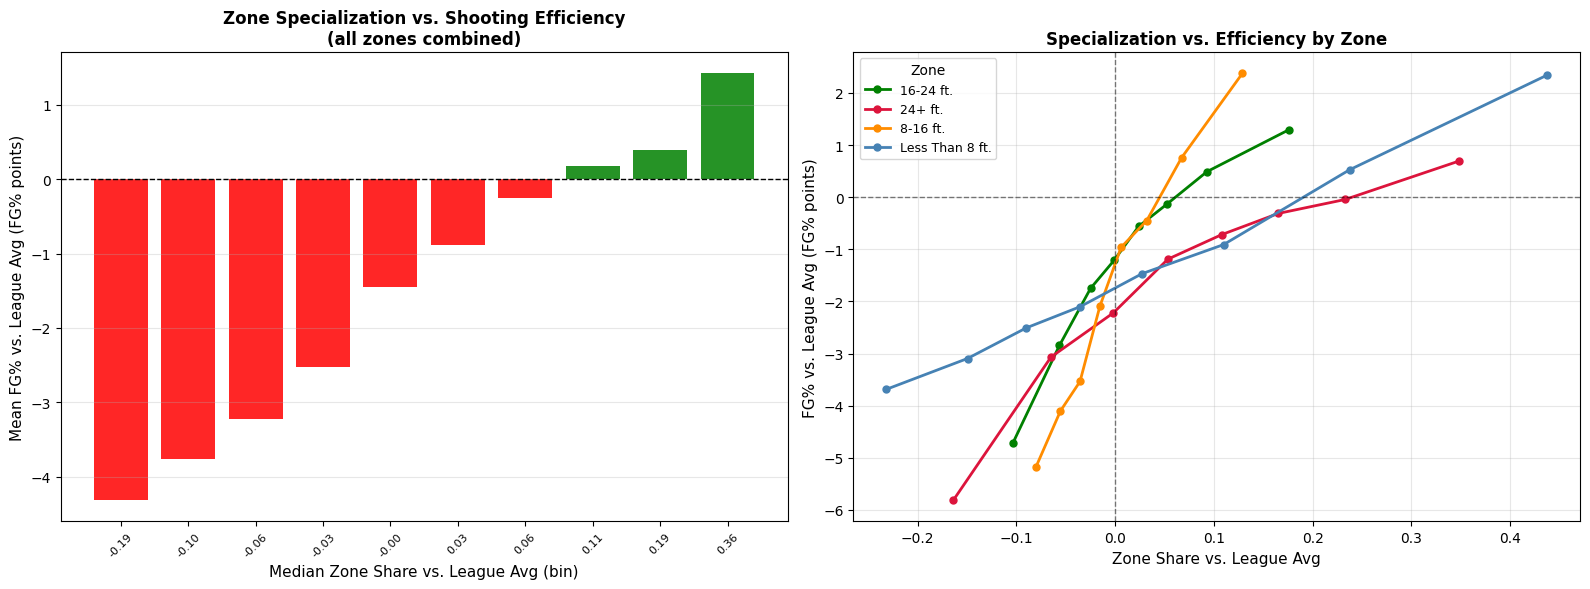

Correlation between share_vs_avg and fg_pct_vs_avg by zone:
Less Than 8 ft.: 0.256
8-16 ft.: 0.297
16-24 ft.: 0.243
24+ ft.: 0.306


In [ ]:
zone_analysis['share_vs_avg_bin'] = pd.qcut(
    zone_analysis['share_vs_avg'], q=10, duplicates='drop'
)

bin_summary = zone_analysis.groupby('share_vs_avg_bin', observed=True).agg(
    mean_fg_vs_avg=('fg_pct_vs_avg', 'mean'),
    median_share_vs_avg=('share_vs_avg', 'median'),
    count=('fg_pct_vs_avg', 'count')
).reset_index()

fig, (p1, p2) = plt.subplots(1, 2, figsize=(16, 6))

colors = ['green' if v > 0 else 'red'
          for v in bin_summary['mean_fg_vs_avg']]
p1.bar(range(len(bin_summary)), bin_summary['mean_fg_vs_avg'] * 100,
       color = colors, alpha = 0.85)
p1.axhline(0, color = 'black', lw = 1, linestyle='--')
p1.set_xticks(range(len(bin_summary)))
p1.set_xticklabels(
    [f'{v:.2f}' for v in bin_summary['median_share_vs_avg']],
    rotation = 45, fontsize = 8
)
p1.set_xlabel('Median Zone Share vs. League Avg (bin)', fontsize = 11)
p1.set_ylabel('Mean FG% vs. League Avg (FG% points)', fontsize = 11)
p1.set_title('Zone Specialization vs. Shooting Efficiency\n(all zones combined)',
             fontsize = 12, fontweight = 'bold')
p1.grid(axis = 'y', alpha = 0.3)

zone_colors = {
    'Less Than 8 ft.': 'steelblue',
    '8-16 ft.': 'darkorange',
    '16-24 ft.': 'green',
    '24+ ft.': 'crimson'
}
for zone, grp in zone_analysis.groupby('ZONE_RANGE'):
    grp_bin = grp.groupby(
        pd.qcut(grp['share_vs_avg'], q = 8, duplicates = 'drop'), observed=True
    ).agg(
        mean_share = ('share_vs_avg', 'median'),
        mean_fg = ('fg_pct_vs_avg', 'mean')
    ).reset_index()
    p2.plot(grp_bin['mean_share'], grp_bin['mean_fg'] * 100,
            marker = 'o', linewidth = 2, markersize = 5,
            label = zone, color = zone_colors.get(zone, 'gray'))

p2.axhline(0, color='black', lw = 1, linestyle='--', alpha = 0.5)
p2.axvline(0, color='black', lw = 1, linestyle='--', alpha = 0.5)
p2.set_xlabel('Zone Share vs. League Avg', fontsize = 11)
p2.set_ylabel('FG% vs. League Avg (FG% points)', fontsize = 11)
p2.set_title('Specialization vs. Efficiency by Zone',
             fontsize = 12, fontweight = 'bold')
p2.legend(title = 'Zone', fontsize = 9)
p2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

corr_less8 = zone_analysis[zone_analysis['ZONE_RANGE'] == 'Less Than 8 ft.']['share_vs_avg'].corr(
    zone_analysis[zone_analysis['ZONE_RANGE'] == 'Less Than 8 ft.']['fg_pct_vs_avg'])

corr_8_16 = zone_analysis[zone_analysis['ZONE_RANGE'] == '8-16 ft.']['share_vs_avg'].corr(
    zone_analysis[zone_analysis['ZONE_RANGE'] == '8-16 ft.']['fg_pct_vs_avg'])

corr_16_24 = zone_analysis[zone_analysis['ZONE_RANGE'] == '16-24 ft.']['share_vs_avg'].corr(
    zone_analysis[zone_analysis['ZONE_RANGE'] == '16-24 ft.']['fg_pct_vs_avg'])

corr_24plus = zone_analysis[zone_analysis['ZONE_RANGE'] == '24+ ft.']['share_vs_avg'].corr(
    zone_analysis[zone_analysis['ZONE_RANGE'] == '24+ ft.']['fg_pct_vs_avg'])

print(f"Correlation between share_vs_avg and fg_pct_vs_avg by zone:")
print(f"Less Than 8 ft.: {corr_less8:.3f}")
print(f"8-16 ft.: {corr_8_16:.3f}")
print(f"16-24 ft.: {corr_16_24:.3f}")
print(f"24+ ft.: {corr_24plus:.3f}")

The correlation analysis establishes that zone specialization has a weak, positive association with above-average shooting efficiency across all four
zones, with correlations ranging from 0.243 to 0.306. This motivates including
`shot_zone_share_vs_avg` as a feature in a shot-level predictive model. If
the relationship holds at the player-season-zone level, it should also carry
signal when predicting individual shot outcomes. We test this by comparing a
baseline model that knows only about the shot itself against an enriched model
that adds zone specialization and player identity features on top.

The left chart shows a clear pattern when all zones are combined. Players who
are below league average in a zone (negative share_vs_avg) tend to shoot below
league average efficiency there, while players who over-index in a zone tend to
shoot above it.

The right chart breaks this down by zone and reveals some interesting
differences. The rim zone (Less Than 8 ft.) shows the most gradual and linear
relationship, with efficiency vs. average rising steadily as specialization
increases, which makes sense given how dominant rim shooting is for paint
specialists like centers. The 8-16 ft. and 16-24 ft. zones show steeper slopes,
suggesting that midrange specialists get a proportionally larger efficiency
boost from shooting in their preferred zones. The 24+ ft. zone has a positive
but shallower slope on the right side, reflecting that 3-point shooting is more
variable and harder to predict from zone specialization alone.

The correlation analysis confirms the direction of these trends across all four
zones, with correlations ranging from 0.243 to 0.306. These are weak but positive relationships not strong enough to predict shot outcomes
on their own, but meaningful enough to add signal in a model that already
controls for shot difficulty. This motivates including `shot_zone_share_vs_avg`
as a feature in the enriched model, where we test whether this player-season-
zone level relationship holds at the individual shot level as well.

## 6: Modeling and Analysis

Throughout our EDA we established that players have distinct zone profiles that
evolve with age, and that the league has shifted decisively toward more efficient shot selection over the past two decades. Now we want to explore this question central to our modeling and subsequent analysis: do players actually shoot better from the zones they specialize in?

We approach this in two stages. First, we build a shot quality model that predicts whether any given shot goes in (SHOT_MADE) using only the location of the shot on the floor. This baseline model treats every shooter as identical and only considers shot location without other shot context.

The second stage extends the baseline with shot context variables like type,
action, zone, and time remaining, as well as zone specialization features
derived from the era-adjusted zone profiles built in Section 4, specifically how characteristic the zone is for the shooter that season, how strongly specialized they are in that zone, and their age and experience. The difference in predictive performance between the baseline and enriched models is specifically attributable to those additional features, and that delta is the central finding.

The modeling approach is structured as a controlled comparison. The three models we will use are logistic regression, random forest, and XGBoost on both the baseline and enriched feature sets. Running all three in both configurations ensures that any improvement we see is consistent across models. Beyond the prediction task itself, we use the enriched model's outputs to compute a characteristic zone efficiency premium for each player which determines the difference between how they actually shoot in their characteristic zones versus outside them, after the model has controlled for shot difficulty. This shot premium gives us a player-level measure of how much they benefit from operating in their comfort zones that goes beyond raw FG%.

### 6.1 Feature Selection and Train-Test Split

The baseline feature set of just `LOC_X_abs` and `LOC_Y` is intentionally limited. We take the absolute value of LOC_X because the court is symmetric. A shot at LOC_X = -5 and LOC_X = +5 are functionally identical, and we confirmed this in the symmetry check in section 1.4. Using the court coordinates gives us the cleanest possible lower bound on what location alone can predict, and any improvement in the enriched models is then directly due to the additional features rather than being confounded by shot context that was already present in the baseline.

The enriched feature set extends the baseline with three groups of variables:
shot context (type, action type, zone, quarter, and time remaining), player
identity (age, years in league, position), and the specialization features
built in section 5 (shot_zone_share_vs_avg, is_characteristic_zone,
specialization_strength). We use an 80/20 stratified train-test split to
preserve the class distribution across both sets.

Given the dataset size of over 4 million shots, a single stratified 80/20 split will produce very stable estimates, with variance across cross-validation folds being negligible at this scale.

In [ ]:
BASELINE_FEATURES = [
    'LOC_X_abs',
    'LOC_Y'
]

ENRICHED_FEATURES = BASELINE_FEATURES + [
    'shottype_enc',
    'action_enc',
    'zone_enc',
    'QUARTER',
    'time_remaining',
    'shot_zone_share_vs_avg',
    'is_characteristic_zone',
    'specialization_strength',
    'age',
    'years_in_league',
    'position_enc'
]

TARGET = 'SHOT_MADE'
y = model_df[TARGET].astype(int).values

In [ ]:
train_idx, test_idx = train_test_split(np.arange(len(model_df)), test_size=0.2, random_state=42, stratify=y)

X_base = model_df[BASELINE_FEATURES].values
X_base_train = X_base[train_idx]
X_base_test = X_base[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

print(f"Train size: {len(y_train):,}  |  Test size: {len(y_test):,}")
print(f"Make rate (train): {y_train.mean():.3f}  |  Make rate (test): {y_test.mean():.3f}")

Train size: 3,363,039  |  Test size: 840,760
Make rate (train): 0.459  |  Make rate (test): 0.459


The raw dataset contains roughly 54% missed shots and 46% makes. While this
imbalance is not severe, it is enough to bias the model toward predicting the
majority class which is misses. This artificially inflates accuracy
and decreases F1. We undersample the majority class to create a balanced 50/50
split before training, ensuring the models are focused on distinguishing makes from misses rather than defaulting toward the more common outcome.

After we rebalance the dataset, **our total dataset is over 3.8 million rows**, each representing one shot. The train dataset is around 3.08 million rows and the test dataset is 771k rows, with a balanced 50/50 split between makes and misses.

In [ ]:
made_df = model_df[model_df['SHOT_MADE'] == 1]
missed_df = model_df[model_df['SHOT_MADE'] == 0]

missed_balanced  = resample(missed_df, n_samples=len(made_df), random_state=42)
balanced_df = pd.concat([made_df, missed_balanced]).sample(frac=1, random_state=42).reset_index(drop=True)

print(f"Balanced dataset size: {len(balanced_df):,}")
print(f"Make rate: {balanced_df['SHOT_MADE'].mean():.3f}")

y = balanced_df['SHOT_MADE'].astype(int).values

train_idx, test_idx = train_test_split(np.arange(len(balanced_df)), test_size=0.2, random_state=42, stratify=y)

X_base = balanced_df[BASELINE_FEATURES].values
X_base_train = X_base[train_idx]
X_base_test  = X_base[test_idx]

y_train = y[train_idx]
y_test  = y[test_idx]

print(f"Train size: {len(y_train):,}  |  Test size: {len(y_test):,}")
print(f"Make rate (train): {y_train.mean():.3f}  |  Make rate (test): {y_test.mean():.3f}")

Balanced dataset size: 3,857,744
Make rate: 0.500
Train size: 3,086,195  |  Test size: 771,549
Make rate (train): 0.500  |  Make rate (test): 0.500


### 6.2 Baseline Models

We train three model architectures on the baseline features. Logistic
regression serves as the interpretable linear benchmark. It assumes a linear
decision boundary between makes and misses, which we know from section 1.4 is
not the true shape of the efficiency surface, but it gives us a clean reference
point and its coefficients are directly interpretable. Random forest is included
because it can naturally handle the non-linear relationship between court location and FG% that we identified in the LOC_Y analysis without requiring manual feature engineering. XGBoost is the third architecture, and it is a sequential boosting model that generally tends to be a very strong model performer. Its inclusion lets us confirm whether any gains from the enriched features hold up under the most competitive baseline we can set. Evaluating all three on the same feature sets ensures that findings aren't a byproduct of any single model's assumptions and that we can really understand how much shot context impacts makes and misses.

#### 6.2a Logistic Regression (Baseline)

In [ ]:
scaler = StandardScaler()
X_base_train_sc = scaler.fit_transform(X_base_train)
X_base_test_sc = scaler.transform(X_base_test)

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_base_train_sc, y_train)

lr_proba = lr.predict_proba(X_base_test_sc)[:, 1]
lr_pred = lr.predict(X_base_test_sc)
lr_auc = roc_auc_score(y_test, lr_proba)
lr_acc = accuracy_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)

print(f"\nLogistic Regression (baseline features)")
print(f"ROC-AUC: {lr_auc:.4f}")
print(f"Accuracy: {lr_acc:.4f}")
print(f"F1 Score: {lr_f1:.4f}")


Logistic Regression (baseline features)
ROC-AUC: 0.6114
Accuracy: 0.5715
F1 Score: 0.5923


#### 6.2b Random Forest (Baseline)

In [ ]:
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=50,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_base_train, y_train)

rf_proba = rf.predict_proba(X_base_test)[:, 1]
rf_pred = rf.predict(X_base_test)
rf_auc = roc_auc_score(y_test, rf_proba)
rf_acc = accuracy_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)

print(f"\nRandom Forest (baseline features)")
print(f"ROC-AUC: {rf_auc:.4f}")
print(f"Accuracy: {rf_acc:.4f}")
print(f"F1 Score: {rf_f1:.4f}")


Random Forest (baseline features)
ROC-AUC: 0.6242
Accuracy: 0.5988
F1 Score: 0.5149


#### 6.2c XGBoost (Baseline)

In [ ]:
gbm = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss'
)
gbm.fit(X_base_train, y_train)

gbm_proba = gbm.predict_proba(X_base_test)[:, 1]
gbm_pred = gbm.predict(X_base_test)
gbm_auc = roc_auc_score(y_test, gbm_proba)
gbm_acc = accuracy_score(y_test, gbm_pred)
gbm_f1 = f1_score(y_test, gbm_pred)

print(f"\nXGBoost (baseline features)")
print(f"ROC-AUC: {gbm_auc:.4f}")
print(f"Accuracy: {gbm_acc:.4f}")
print(f"F1 Score: {gbm_f1:.4f}")


XGBoost (baseline features)
ROC-AUC: 0.6243
Accuracy: 0.5991
F1 Score: 0.5124


The baseline results with only shot location make sense. AUC values in the
0.61-0.62 range and accuracy around 57-60% are reasonable given that LOC_X_abs
and LOC_Y alone are a very limited description of a shot. Two players standing
in the exact same spot can have wildly different make probabilities depending
on who they are, how they got there, and what the defense is doing.

The F1 gap between logistic regression and the two tree-based models is worth
noting. Logistic regression has the lowest AUC (0.6114) but the highest F1
(0.5923), while random forest and XGBoost have higher AUCs but much lower F1
scores around 0.51. Our tree-based models are likely predicting probabilities
that are more compressed toward 0.5 rather than pushing toward the extremes,
which means fewer shots get classified as makes at the standard 0.5 threshold,
pulling down recall and F1. Logistic regression's linear boundary produces more
spread out probabilities that happen to classify more shots as makes at that
same threshold. We find AUC to be the more reliable comparison metric since it
evaluates the full ranking of predictions across all thresholds rather than
just the binary outcome at 0.5, making it more robust to this kind of threshold
sensitivity.

Random forest and XGBoost are nearly identical across all three metrics at
0.6242 and 0.6243 AUC respectively. The slightly better performance both have over logistic regression confirms that the non-linear efficiency trend we identified in section 1.4 is real and meaningful even with just two features. The tree-based models are better at capturing the curved relationship between court location and FG%. Now, we are most interested to see how much all three improve once we add shot context and specialization features in the enriched models.

### 6.3 Enriched Models

We now retrain all three models on the enriched feature set. We keep the hyperparameters identical so that any performance difference is due to the additional features rather than model configuration.

In [ ]:
X_enriched = balanced_df[ENRICHED_FEATURES].values
X_enr_train = X_enriched[train_idx]
X_enr_test = X_enriched[test_idx]

#### 6.3a Logistic Regression (Enriched)

In [ ]:
scaler_enr = StandardScaler()
X_enr_train_sc = scaler_enr.fit_transform(X_enr_train)
X_enr_test_sc = scaler_enr.transform(X_enr_test)

lr_enr = LogisticRegression(max_iter=1000, random_state=42)
lr_enr.fit(X_enr_train_sc, y_train)
lr_enr_proba = lr_enr.predict_proba(X_enr_test_sc)[:, 1]
lr_enr_pred = lr_enr.predict(X_enr_test_sc)
lr_enr_auc = roc_auc_score(y_test, lr_enr_proba)
lr_enr_acc = accuracy_score(y_test, lr_enr_pred)
lr_enr_f1 = f1_score(y_test, lr_enr_pred)

print(f"\nLogistic Regression (enriched features)")
print(f"ROC-AUC: {lr_enr_auc:.4f}")
print(f"Accuracy: {lr_enr_acc:.4f}")
print(f"F1 Score: {lr_enr_f1:.4f}")


Logistic Regression (enriched features)
ROC-AUC: 0.6092
Accuracy: 0.5837
F1 Score: 0.5822


#### 6.3b Random Forest (Enriched)

In [ ]:
rf_enr = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=50,
    random_state=42,
    n_jobs=-1
)
rf_enr.fit(X_enr_train, y_train)
rf_enr_proba = rf_enr.predict_proba(X_enr_test)[:, 1]
rf_enr_pred  = rf_enr.predict(X_enr_test)
rf_enr_auc = roc_auc_score(y_test, rf_enr_proba)
rf_enr_acc = accuracy_score(y_test, rf_enr_pred)
rf_enr_f1  = f1_score(y_test, rf_enr_pred)

print(f"\nRandom Forest (enriched features)")
print(f"ROC-AUC: {rf_enr_auc:.4f}")
print(f"Accuracy: {rf_enr_acc:.4f}")
print(f"F1 Score: {rf_enr_f1:.4f}")


Random Forest (enriched features)
ROC-AUC: 0.6368
Accuracy: 0.6052
F1 Score: 0.5414


#### 6.3c XGBoost (Enriched)

In [ ]:
gbm_enr= XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss'
)

gbm_enr.fit(X_enr_train, y_train)
gbm_enr_proba = gbm_enr.predict_proba(X_enr_test)[:, 1]
gbm_enr_pred = gbm_enr.predict(X_enr_test)
gbm_enr_auc = roc_auc_score(y_test, gbm_enr_proba)
gbm_enr_acc = accuracy_score(y_test, gbm_enr_pred)
gbm_enr_f1 = f1_score(y_test, gbm_enr_pred)

print(f"\nXGBoost (enriched features)")
print(f"ROC-AUC: {gbm_enr_auc:.4f}")
print(f"Accuracy: {gbm_enr_acc:.4f}")
print(f"F1 Score: {gbm_enr_f1:.4f}")


XGBoost (enriched features)
ROC-AUC: 0.6400
Accuracy: 0.6061
F1 Score: 0.5416


The tree-based enriched models show clear improvement over their baselines on
AUC and accuracy. Random forest rises from 0.6242 to 0.6368 and XGBoost from
0.6243 to 0.6400 which suggests that the shot context and specialization features are adding real predictive value. Logistic regression is the exception, with AUC dropping marginally from 0.6114 to 0.6092, likely because the additional features introduce non-linear relationships that a linear model can't fully understand or use. The full side-by-side comparison and interpretation is in section 6.4 below.

### 6.4 Model Comparison

In [ ]:
full_results = pd.DataFrame({
    'Model': [
        'Logistic Regression', 'Logistic Regression + Specialization',
        'Random Forest', 'Random Forest + Specialization',
        'XGBoost', 'XGBoost + Specialization',
    ],
    'ROC-AUC': [
        round(lr_auc, 4), round(lr_enr_auc, 4),
        round(rf_auc, 4), round(rf_enr_auc, 4),
        round(gbm_auc, 4), round(gbm_enr_auc, 4),
    ],
    'Accuracy': [
        round(lr_acc, 4), round(lr_enr_acc, 4),
        round(rf_acc, 4), round(rf_enr_acc, 4),
        round(gbm_acc, 4), round(gbm_enr_acc, 4),
    ],
    'F1': [
        round(lr_f1, 4), round(lr_enr_f1, 4),
        round(rf_f1, 4), round(rf_enr_f1, 4),
        round(gbm_f1, 4), round(gbm_enr_f1, 4),
    ],
    'Change in AUC': [
        '-', f'{lr_enr_auc - lr_auc:.4f}',
        '-', f'+{rf_enr_auc - rf_auc:.4f}',
        '-', f'+{gbm_enr_auc - gbm_auc:.4f}',
    ],
})
display(full_results)

,Model,ROC-AUC,Accuracy,F1,Change in AUC
0,Logistic Regression,0.6114,0.5715,0.5923,-
1,Logistic Regression + Specialization,0.6092,0.5837,0.5822,-0.0022
2,Random Forest,0.6242,0.5988,0.5149,-
3,Random Forest + Specialization,0.6368,0.6052,0.5414,+0.0125
4,XGBoost,0.6243,0.5991,0.5124,-
5,XGBoost + Specialization,0.6400,0.6061,0.5416,+0.0157


The tree-based enriched models improve over their baselines. XGBoost is the strongest performer with an AUC of 0.6400 and accuracy of 0.6061, followed closely by random forest at 0.6368. Both gains are significant, with +0.0157 for XGBoost and +0.0125 for random forest. This confirms that the shot context and specialization features carry real predictive signal beyond just court location alone.

Logistic regression is the exception. Its AUC drops marginally from 0.6114 to
0.6092 can be explained by the fact that the enriched feature set introduces
non-linear relationships between specialization, age, and zone that a linear
model cannot capture effectively. The accuracy improvement from 0.5715 to
0.5837 suggests the additional features do help logistic regression make better
binary predictions at the 0.5 threshold, even if they don't improve its overall
ranking of shots by make probability.

The F1 pattern is interesting. Logistic regression's F1 drops from 0.5923 to
0.5822 in the enriched configuration, while the tree-based models actually
improve slightly from around 0.51 to 0.54. This suggests the enriched features
help random forest and XGBoost become more balanced across both classes rather
than strongly favoring misses, while logistic regression becomes slightly more
conservative in its predictions.

Accuracy values around 60% are meaningful on a balanced 50/50 dataset where
a naive majority-class predictor would achieve exactly 50%. The ceiling for
shot-level prediction is limited without features like defender distance or shot clock, so these results reflect what is realistically achievable from the data we have.

### 6.5 AUC Curves

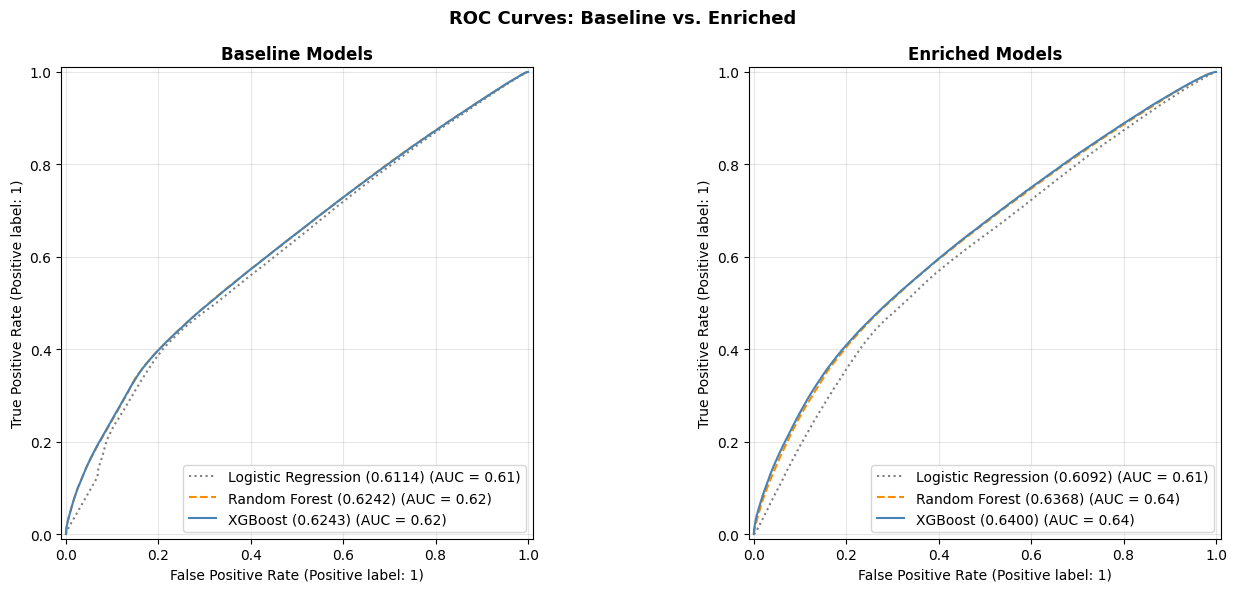

In [ ]:
fig, (p1, p2) = plt.subplots(1, 2, figsize=(14, 6))

RocCurveDisplay.from_predictions(y_test, lr_proba,  ax=p1, name=f'Logistic Regression ({lr_auc:.4f})',  color='gray', linestyle=':')
RocCurveDisplay.from_predictions(y_test, rf_proba,  ax=p1, name=f'Random Forest ({rf_auc:.4f})', color='darkorange',  linestyle='--')
RocCurveDisplay.from_predictions(y_test, gbm_proba, ax=p1, name=f'XGBoost ({gbm_auc:.4f})', color='steelblue')
p1.set_title('Baseline Models', fontsize=12, fontweight='bold')
p1.grid(alpha=0.3)

RocCurveDisplay.from_predictions(y_test, lr_enr_proba,  ax=p2, name=f'Logistic Regression ({lr_enr_auc:.4f})',  color='gray', linestyle=':')
RocCurveDisplay.from_predictions(y_test, rf_enr_proba,  ax=p2, name=f'Random Forest ({rf_enr_auc:.4f})', color='darkorange',  linestyle='--')
RocCurveDisplay.from_predictions(y_test, gbm_enr_proba, ax=p2, name=f'XGBoost ({gbm_enr_auc:.4f})', color='steelblue')
p2.set_title('Enriched Models', fontsize=12, fontweight='bold')
p2.grid(alpha=0.3)

plt.suptitle('ROC Curves: Baseline vs. Enriched', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

The ROC curves tell the same story as the metrics table but make the separation
between models more visible. In the baseline panel, all three models are nearly
indistinguishable from each other across the full curve, which makes sense
given that they're all working from the same two features. The small separation
that does exist shows random forest and XGBoost performing slightly above logisticregression, consistent with the AUC gap that we previously saw.

The enriched panel shows a clear divergence between logistic regression and the
two tree-based models. Random forest and XGBoost shift upward together and
remain nearly identical to each other, while logistic regression stays close to
its baseline curve and actually falls slightly below it. This matches the marginal AUC drop from 0.6114 to 0.6092 we noted earlier. This visual separation confirms that the enriched features help the tree-based models
meaningfully, but a linear model cannot leverage those same features as
effectively. The consistent gap between logistic regression and the tree-based
models across the full range of thresholds rather than just at one point
confirms this is a structural limitation of the model rather than a threshold
artifact.

### 6.6 Confusion Matrices


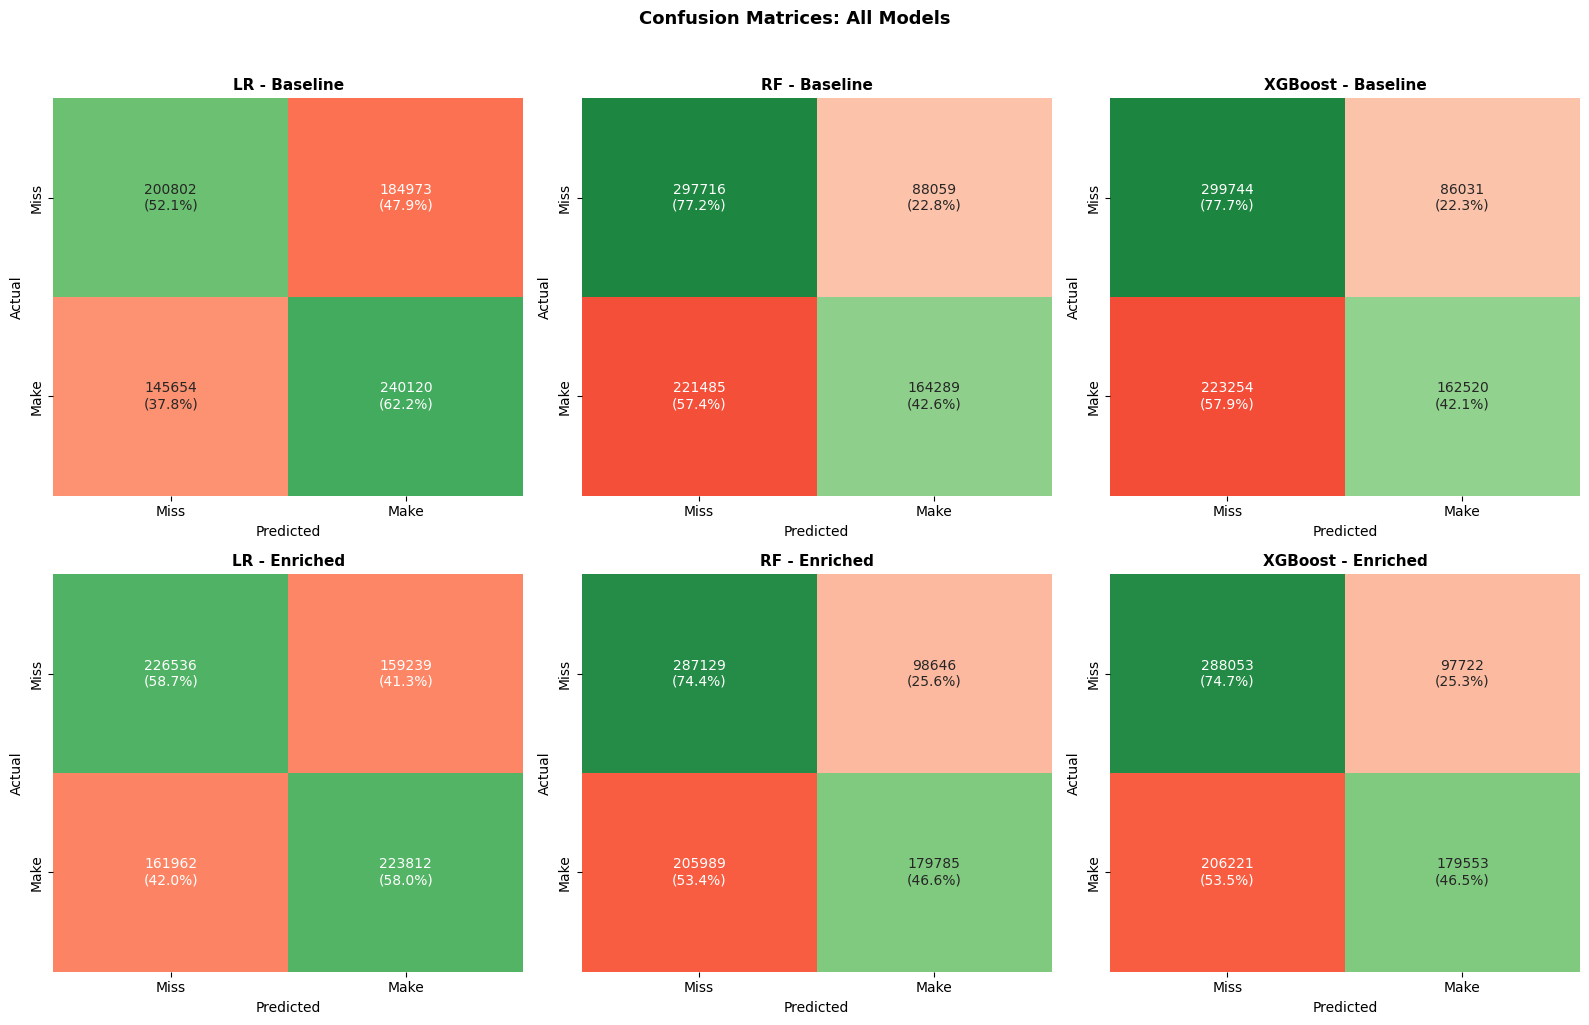

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

preds = [lr_pred, rf_pred, gbm_pred, lr_enr_pred, rf_enr_pred, gbm_enr_pred]
titles = ['LR - Baseline', 'RF - Baseline', 'XGBoost - Baseline',
          'LR - Enriched', 'RF - Enriched', 'XGBoost - Enriched']

for ax, pred, title in zip(axes.flatten(), preds, titles):
    cm_counts = confusion_matrix(y_test, pred)
    cm_norm = confusion_matrix(y_test, pred, normalize='true')

    labels = np.array([
        [f"{cm_counts[i, j]}\n({cm_norm[i, j]:.1%})"
         for j in range(cm_counts.shape[1])]
        for i in range(cm_counts.shape[0])
    ])

    diag_mask = np.eye(cm_norm.shape[0], dtype=bool)
    off_diag_mask = ~diag_mask

    # Correct predictions in green
    sns.heatmap(cm_norm,
                mask=off_diag_mask,
                cmap="Greens",
                vmin=0, vmax=1,
                annot=labels,
                fmt="",
                cbar=False,
                xticklabels=['Miss', 'Make'],
                yticklabels=['Miss', 'Make'],
                ax=ax)

    # Incorrect predictions in red
    sns.heatmap(cm_norm,
                mask=diag_mask,
                cmap="Reds",
                vmin=0, vmax=1,
                annot=labels,
                fmt="",
                cbar=False,
                xticklabels=['Miss', 'Make'],
                yticklabels=['Miss', 'Make'],
                ax=ax)

    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle('Confusion Matrices: All Models', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

The confusion matrices highlight the differences between logistic regression and the two tree-based models. In the baseline, logistic regression is the most balanced of the three. It correctly identifying 62.2% of actual makes and 52.1% of actual misses, a relatively even split. Random forest and XGBoost take the opposite approach, correctly identifying 77.2% and 77.7% of misses respectively but only 42.6% and 42.1% of actual makes, strongly favoring miss predictions over make predictions.

The enriched models shift the balance meaningfully across all three models. Logistic regression becomes more conservative, with its miss predictions improving from 52.1% to 58.7% while make predictions drops from 62.2% to 58.0%, suggesting the additional features are helping it better identify shots that won't go in at the cost of some makes. The tree-based models show improvement on make predictions with the enriched data, with random forest rising from 42.6% to 46.6% and XGBoost from 42.1% to 46.5%, while maintaining strong miss predictions above 74%. The enriched models are becoming more balanced across both classes rather than strongly favoring misses, which is consistent with the AUC improvements we saw in the metrics table.

### 6.7 Feature Importance

In [ ]:
FEATURE_LABELS = {
    'LOC_X_abs': 'LOC_X (abs)',
    'LOC_Y': 'LOC_Y',
    'shottype_enc': 'Shot Type (2PT/3PT)',
    'action_enc': 'Action Type',
    'zone_enc': 'Zone',
    'QUARTER': 'Quarter',
    'time_remaining': 'Time Remaining',
    'shot_zone_share_vs_avg': 'Zone Share vs. Avg',
    'is_characteristic_zone': 'Is Characteristic Zone',
    'specialization_strength': 'Specialization Strength',
    'age': 'Age',
    'years_in_league': 'Years in League',
    'position_enc': 'Position',
}


In [ ]:
lr_coef = pd.DataFrame({
    'feature': ENRICHED_FEATURES,
    'coefficient': lr_enr.coef_[0]
}).sort_values('coefficient', ascending=False)
lr_coef['label'] = lr_coef['feature'].map(FEATURE_LABELS)
display(lr_coef[['label', 'coefficient']].reset_index(drop=True))

,label,coefficient
0,Zone,0.125409
1,Action Type,0.080303
2,Zone Share vs. Avg,0.052247
3,Years in League,0.050347
4,Time Remaining,0.021480
5,Is Characteristic Zone,0.021383
6,Specialization Strength,0.021354
7,Position,0.009558
8,Quarter,-0.022998
9,Age,-0.024236


In [ ]:
rf_imp = pd.DataFrame({
    'feature': ENRICHED_FEATURES,
    'importance': rf_enr.feature_importances_
}).sort_values('importance', ascending=False)
rf_imp['label'] = rf_imp['feature'].map(FEATURE_LABELS)
display(rf_imp[['label', 'importance']].reset_index(drop=True))

,label,importance
0,Action Type,0.281736
1,Zone,0.200984
2,LOC_X (abs),0.198482
3,LOC_Y,0.191886
4,Shot Type (2PT/3PT),0.051684
5,Time Remaining,0.023427
6,Zone Share vs. Avg,0.016760
7,Position,0.013005
8,Specialization Strength,0.009300
9,Is Characteristic Zone,0.004935


In [ ]:
gbm_imp = pd.DataFrame({
    'feature': ENRICHED_FEATURES,
    'importance': gbm_enr.feature_importances_
}).sort_values('importance', ascending=False)
gbm_imp['label'] = gbm_imp['feature'].map(FEATURE_LABELS)
display(gbm_imp[['label', 'importance']].reset_index(drop=True))

,label,importance
0,Action Type,0.629295
1,LOC_Y,0.071479
2,LOC_X (abs),0.055600
3,Position,0.053662
4,Zone,0.048475
5,Shot Type (2PT/3PT),0.044145
6,Time Remaining,0.034012
7,Zone Share vs. Avg,0.020767
8,Years in League,0.018830
9,Quarter,0.013031


Across all three models, action type and zone are the most important features which makes sense. How a shot is created and where it comes from are the primary drivers of difficulty. LOC_Y is consistently important across Random Forest and XGBoost, indicating the strong efficiency trend from the basket outward that we established in the EDA.

Among the specialization features, zone_share_vs_avg is the most important
across all three models, which directly validates the correlation analysis we performed earlier. The degree to which a zone is characteristic for a player carries real predictive signal at the shot level. Years in league also appears
consistently, which may indicate that experienced players outperform expectations slightly on any given shot.

Note that for Random Forest and XGBoost, we don't get direction, only scale of importance based on the coefficient. However, the Logistic Regression coefficients can also include negatives, which can tell a cleaner directional story. Zone and action type are positive, meaning shots from certain zones and with certain actions are more likely to go in. LOC_Y is negative, confirming that shots further from the basket are harder to make. Shot type is negative, which seems counterintuitive at first but makes sense once you control for everything else. After we account for zone, distance, and action type, the remaining 3PT attempts are those taken from difficult spots by players who don't specialize there. Zone share vs. avg is positive across all three models, meaning players shooting from their characteristic zones have a higher predicted make probability, consistent with our hypothesis.

Specialization strength and is_characteristic_zone are some of the weakest
specialization features in the tree-based models. This is mostly because zone_share_vs_avg already captures the continuous measure of specialization, making the engineered binary and absolute value features somewhat redundant.

### 6.8 Characteristic Zone Efficiency Premium


For each shot in the dataset, we use the enriched XGBoost model specifically for the efficiency premium calculation for three reasons. First, it is our best performing model with the highest AUC of 0.6392, meaning its predicted probabilities are the most accurate representation of shot difficulty we have. Second, XGBoost's predicted probabilities are better calibrated than random forest's for this kind of residual analysis, as it has a wider range of predicted probabilities that will help create separation in the efficiency premium analysis. Third, using a single model ensures the residuals are on a consistent scale across all players and seasons, which is essential for the premium to be a meaningful comparison across different player profiles.

The residual for each shot is the difference between the actual outcome
(1 for make, 0 for miss) and the model's predicted probability. A positive
residual means the player outperformed what the model expected on that shot
given all of the available context in our dataset, such as location, action type, game situation, and their zone profile.

For each player we split their shots into two groups: those taken from their
characteristic zones (where share_vs_avg > 0) and those taken outside of their characteristic zones. We compute the average residual for each group separately, then take the difference. This is the efficiency premium.

The reason we look at the difference rather than the characteristic zone
residual alone is to isolate the specialization effect from overall shooting
quality. A player who is simply a great shooter will outperform the model
everywhere since their residuals will be positive in both zones and the difference will be small. The premium specifically captures players who are
disproportionately better in their characteristic zones relative to how they
perform outside them. A large positive premium means operating in their comfort
zone genuinely lifts their performance beyond what their general shooting skill
alone would predict.

Ultimately the premium is answering the question "for which players does zone
context matter most"? A large positive premium means the player genuinely thrives in their comfort zone. The zone itself is doing work for them beyond what their general shooting skill would predict. A large negative premium means the opposite, that the player is somehow shooting worse than expected in the zones they gravitate toward most.

Players analyzed: 1112

Top 15 - Largest efficiency premium:


,PLAYER_NAME,simple_position,total_shots,char_zone_fg_pct,nonchar_zone_fg_pct,efficiency_premium_pct
0,Michael Olowokandi,Center,924.0,44.53,10.00,20.88
1,Rudy Gobert,Center,5431.0,67.18,21.28,19.11
2,Steven Hunter,Center,1062.0,61.19,18.18,19.05
3,Walker Kessler,Center,764.0,71.25,24.32,19.00
4,Andris Biedrins,Center,2409.0,60.93,23.16,17.81
5,Jalen Duren,Center,962.0,66.59,28.41,17.63
6,Jan Vesely,Forward,503.0,58.00,18.06,17.44
7,DeAndre Jordan,Center,5583.0,68.58,21.99,16.78
8,Moses Brown,Center,547.0,57.87,15.00,15.69
9,Maurice Taylor,Center,1627.0,47.02,13.33,15.54



Bottom 15 - Smallest efficiency premium:


,PLAYER_NAME,simple_position,total_shots,char_zone_fg_pct,nonchar_zone_fg_pct,efficiency_premium_pct
1097,Dwayne Bacon,Forward,1419.0,41.11,39.01,-10.17
1098,Justin Hamilton,Center,577.0,39.86,53.38,-10.51
1099,Antonio Blakeney,Guard,538.0,34.87,48.29,-10.61
1100,Isaiah Stewart,Center,1722.0,51.28,40.34,-10.63
1101,Isaiah Roby,Forward,906.0,53.26,38.70,-11.01
1102,Justin Jackson,Forward,1504.0,33.50,59.34,-11.15
1103,Ziaire Williams,Forward,993.0,30.59,57.49,-11.22
1104,Eric Williams,Forward,1045.0,39.23,46.20,-11.79
1105,Jarell Martin,Forward,863.0,44.58,40.38,-11.89
1106,Eddie Griffin,Forward,918.0,26.99,51.19,-12.54


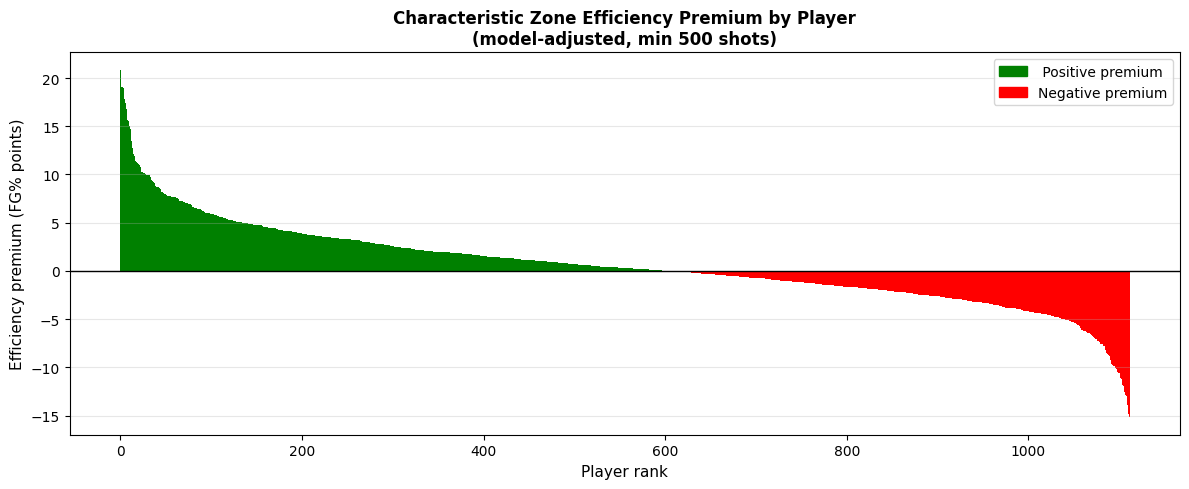

In [ ]:
model_df['predicted_fg'] = gbm_enr.predict_proba(model_df[ENRICHED_FEATURES].values)[:, 1]
model_df['residual'] = model_df['SHOT_MADE'].astype(int) - model_df['predicted_fg']

# Calculating efficiency premium per player
player_premium = model_df.groupby(['PLAYER_ID', 'PLAYER_NAME', 'simple_position']).apply(
    lambda df: pd.Series({
        'total_shots': len(df),
        'char_zone_fg_pct': round(df[df['is_characteristic_zone'] == 1]['SHOT_MADE'].mean() * 100, 2),
        'nonchar_zone_fg_pct': round(df[df['is_characteristic_zone'] == 0]['SHOT_MADE'].mean() * 100, 2),
        'char_zone_residual': df[df['is_characteristic_zone'] == 1]['residual'].mean(),
        'nonchar_zone_residual': df[df['is_characteristic_zone'] == 0]['residual'].mean(),
    })
).reset_index()

player_premium['efficiency_premium_pct'] = ((player_premium['char_zone_residual'] - player_premium['nonchar_zone_residual']) * 100).round(2)

# Filter to players with enough shots in both zones
player_premium = player_premium[
    (player_premium['total_shots'] >= 500) &
    (player_premium['char_zone_fg_pct'].notna()) &
    (player_premium['nonchar_zone_fg_pct'].notna())
].sort_values('efficiency_premium_pct', ascending=False).reset_index(drop=True)

print(f"Players analyzed: {len(player_premium)}")
print("\nTop 15 - Largest efficiency premium:")
display(player_premium[['PLAYER_NAME', 'simple_position', 'total_shots', 'char_zone_fg_pct', 'nonchar_zone_fg_pct', 'efficiency_premium_pct']].head(15))

print("\nBottom 15 - Smallest efficiency premium:")
display(player_premium[['PLAYER_NAME', 'simple_position', 'total_shots', 'char_zone_fg_pct', 'nonchar_zone_fg_pct', 'efficiency_premium_pct']].tail(15))

fig, ax = plt.subplots(figsize = (12, 5))
colors = ['green' if p > 0 else 'red'
          for p in player_premium['efficiency_premium_pct']]
ax.bar(range(len(player_premium)), player_premium['efficiency_premium_pct'],
       color = colors, edgecolor = 'none', width=1.0)
ax.axhline(0, color = 'black', lw=1)
ax.set_xlabel('Player rank', fontsize=11)
ax.set_ylabel('Efficiency premium (FG% points)', fontsize=11)
ax.set_title('Characteristic Zone Efficiency Premium by Player\n(model-adjusted, min 500 shots)',
             fontsize = 12, fontweight = 'bold')
ax.grid(axis = 'y', alpha = 0.3)
green_patch = mpatches.Patch(color = 'green', label =' Positive premium')
red_patch = mpatches.Patch(color = 'red', label = 'Negative premium')
ax.legend(handles=[green_patch, red_patch])
plt.tight_layout()
plt.show()

The efficiency premium analysis confirms the pattern we observed earlier. The
top of the leaderboard is dominated by centers that really only shoot in the
paint, such as Rudy Gobert, Walker Kessler, DeAndre Jordan, and Shaquille
O'Neal. Their large efficiency premiums reflect how dramatically their
efficiency drops when forced to shoot outside their characteristic zone. A
player like Gobert shooting 67.18% in his characteristic zone but only 21.28%
outside it illustrates the metric's key limitation. For extreme paint
specialists, the premium is capturing positional extremity more than a pure
specialization effect.

Malcolm Delaney is the most interesting entry in the top 15 as the only
guard, shooting 42.70% in his characteristic zone versus 32.46% outside
it for a premium of 12.16 FG% points. That's a meaningful gap for a guard and
suggests genuine zone-dependent efficiency rather than just a position effect.

The bottom of the leaderboard tells a different story. Austin Reaves has the
largest negative premium at -15.18, shooting 39.53% in his characteristic zone
but 66.88% outside it. This is most likely due to the era-adjusted zone profile
not accurately reflecting where he actually generates his best looks. This means his characteristic zone as defined by share vs. average doesn't align with where he is most effective. Reggie Miller also appears near the bottom at -13.95, which might be concerning at first glance, but he retired in 2005 so we only have his last year of playing, making his zone profile and subsequent analysis unreliable.

The distribution plot makes the overall pattern clear. The green region
has more points than the red, meaning the majority of players in our dataset shoot better in their characteristic zones after controlling for shot difficulty. The green side also has a much steeper drop-off, with a handful of extreme outliers at the top (the paint-only centers) pulling the distribution high before it rapidly heads toward zero. The red region is wider and more gradual, suggesting that negative premiums tend to be smaller in magnitude and more evenly distributed rather than driven by a few extreme cases the way the positive side is.

The asymmetry between the two sides is itself an interesting finding. If zone specialization had no relationship with efficiency, we would expect the distribution to be roughly symmetric around zero. The fact that positive premiums are more common and more extreme on the upside supports the central conclusion that players genuinely tend to perform better in the zones they gravitate toward, even after the model accounts for the difficulty of those shots.

In [ ]:
# Compare players featured in Section 3 expected points analysis
spotlight_players = ['Zion Williamson', 'Kevin Durant', 'Stephen Curry', 'Nikola Jokic']
spotlight = player_premium[player_premium['PLAYER_NAME'].isin(spotlight_players)][
    ['PLAYER_NAME', 'simple_position', 'total_shots', 'char_zone_fg_pct', 'nonchar_zone_fg_pct', 'efficiency_premium_pct']
].sort_values('efficiency_premium_pct', ascending=False)

print("Efficiency premium - Section 3 spotlight players:")
display(spotlight)

Efficiency premium - Section 3 spotlight players:


,PLAYER_NAME,simple_position,total_shots,char_zone_fg_pct,nonchar_zone_fg_pct,efficiency_premium_pct
362,Nikola Jokic,Center,9749.0,62.39,39.50,1.92
497,Zion Williamson,Forward,2959.0,61.67,33.98,0.72
511,Stephen Curry,Guard,16986.0,43.63,53.98,0.61
871,Kevin Durant,Forward,19865.0,45.31,55.18,-2.28


Revisiting the four players from the expected points analysis in Section 3 through the zone specialization analysis adds an interesting layer to what we saw earlier.

Jokic has the strongest positive premium at +1.92, shooting 62.39% in his characteristic zones versus 39.5% outside them. This is consistent with what we saw in the expected points analysis. He is one of the most efficient players in the league and the specialization framework captures that cleanly.

Zion's result is worth pausing on. Despite appearing below expected points in Section 3, his efficiency premium here is positive at +0.72, shooting 61.67% in his characteristic zones. However, two findings are not contradictory. Section 3 showed that Zion underperforms the high league-average benchmark set by paint shots, while this metric shows he still shoots better in his characteristic zones than outside them after the model controls for shot difficulty. He is a zone-dependent player in the truest sense.

Curry and Durant are the most counterintuitive entries. Curry shoots 43.63% in his characteristic zones but 53.98% outside them, producing a small positive premium of +0.61. Durant is the only one of the four with a negative premium at -2.28, shooting 45.31% in his characteristic zones versus 55.18% outside them. These results most likely reflects the same shortcoming with this specific analysis. Elite, versatile players who shoot efficiently everywhere don't show strong specialization effects because their non-characteristic zones are not actually weak spots. Durant in particular is so well-rounded that the zones he doesn't over-index in are still zones he shoots well from, which compresses or inverts the premium. This is actually a meaningful finding: the efficiency premium metric rewards zone-dependent players more than it rewards all-around ones.

## 7: Conclusion

This project set out to answer three questions about NBA shooting: how shot selection and efficiency have evolved over 20 seasons, whether players develop characteristic zone profiles that shift with age, and whether zone specialization actually predicts shooting efficiency. The EDA answers the first question clearly. The league has undergone a structural shift away from midrange shooting toward rim attempts and three-pointers. Corner three-point attempts nearly doubled as a share of total shots from 2004 to 2024. Interestingly, three-point accuracy has not improved despite the big increase in volume.

The era-adjusted zone share analysis answers the second question. Players do develop stable positional identities. Guards lean toward perimeter-heavy profiles as they age, centers remain anchored at the rim throughout their careers, and forwards have shown the most dramatic identity shift with their interior touches being replaced by more spacing roles over the past decade. The profiles evolve with age as we would expect and reflect the broader strategic transformation of the league.

The modeling answers the third question with nuance. Zone specialization carries a weak but consistent positive signal across all four court zones, with correlations between 0.243 and 0.306 between share vs. average and FG% vs. average. Adding specialization features improved AUC for both tree-based models, with XGBoost reaching 0.6400 (+0.0157 over baseline) and random forest 0.6368 (+0.0125 over baseline). Logistic regression was the exception, with AUC marginally dropping from 0.6114 to 0.6092 in the enriched configuration, reflecting the non-linear nature of the specialization signal that a linear model cannot fully capture. This confirms that who is shooting matters beyond just where the shot originates, but only models that can handle non-linearity benefit from knowing it.

However, there are many limitations to our modeling. Without shot clock data, defender distance, or play type, the ceiling for shot-level prediction is constrained.

The efficiency premium analysis we performed as a result of our models adds a player-level dimension to this finding. Most players shoot better in their characteristic zones after controlling for shot difficulty, and positive premiums are both more common and more extreme than negative ones. The most revealing cases, such as Curry and Durant, are the counterintuitive ones, because they both show near-zero or negative premiums not because they are inefficient, but because they shoot well everywhere. The metric specifically rewards zone-dependent players, and all-around players compress or invert the premium by having no real weak zones for the model to distinguish against. Future work incorporating defensive context and tracking data would substantially make these findings more impactful.

Overall, the results support a coherent picture. NBA shot selection has become more rational at the league level, individual players do develop and refine zone identities over their careers, and those identities carry predictive signal for shooting efficiency at the shot level.

## 8: Challenges and Obstacles


The biggest challenge throughout this project was finding a modeling approach
that was both novel and feasible given the columns available in the dataset.
We went through several iterations including predicting shot quality using spatial coordinates, testing game-level aggregations, looking at season-level data, and various framings of the zone specialization hypothesis, before we landed on the baseline vs. enriched comparison that made the most analytical sense. Without shot clock, defender distance, or play type data, the ceiling for shot-level prediction is inherently limited, and a lot of the work was understanding and acknowledging that ceiling.

Collecting the player info dataset through the NBA API introduced its own
challenges. The API rate limits required a 2 to 3 second sleep between each request, making the full scrape time-consuming. Some players as we explored had some missing data, resulting in 27 players with missing height and weight data. Merging the player info onto the shots dataset also required careful attention to ID types since the two sources stored player IDs in different formats.

The era-adjusted zone share construction in Section 4 was more involved than
anticipated. Normalizing player zone profiles against season-level league averages required careful merging across multiple aggregation levels, and getting the join logic right between shot-level data and player-season-level features introduced several opportunities for data leakage that we had to think through carefully.

We used a single train-test split rather than k-fold cross-validation. While the dataset size makes this unlikely to introduce meaningful variance, future work could validate this assumption explicitly.

Computational constraints were a recurring issue. The dataset contains over
4 million shots and several cells, so we ran into some runtime issues in Colab.

The efficiency premium analysis revealed a known limitation of the metric, as
the top of the leaderboard is dominated by paint-only centers like Rudy Gobert
and Dwight Howard whose large premiums reflect positional extremity rather than
a pure specialization effect. A more sophisticated version of this metric would
control for position explicitly when computing the premium.


## 9: Potential Next Steps

The most impactful extension of this project would be incorporating shot context data that our dataset doesn't have such as specifically defender distance and shot clock. With those features, the enriched model could distinguish between an open corner 3 and a contested one from the same coordinates, which would dramatically improve the signal available at the shot level and make the specialization features even more meaningful. Providing the defensive rating of the team to make more accurate predictions of make or miss. Additionally, capturing defensive statistics of the relevant player from the opponent, for example the opponents center position defensive rating.

The efficiency premium analysis could be expanded on in many ways. Filtering to guards and forwards only would remove the paint center confound and produce a cleaner leaderboard. Tracking how a player's premium evolves season by season would let us identify players who are developing more specialized and efficient shot profiles over their careers which could potentially be a useful signal for player development and roster construction.

Finally, the correlation analysis between zone specialization and above-average efficiency could be extended to test whether teams that better match shot
opportunities to player zone profiles see improved offensive efficiency at the
team level. Putting players in positions to shoot from their characteristic zones could lead to better offensive efficiency at the team level. That would connect the individual-level findings from this project to practical team strategy.